# 이야기담 — 추출한 동작을 내 그림에 입히기 (15-joint RTMPose → GIF)
**위에서부터 순서대로 실행.** GPU 런타임 권장 (없으면 CPU로도 실행됨)

- 1번: Drive 마운트 + mmpose 환경 복원 (Drive `yiyagidam/deploy`의 내 모델·config 사용)
- 2번: 애니메이션 스크립트 생성
- 3번: 스크립트 패치 (CPU 대응, `--seq-fps`, 상대 동작 `--relative`, 제자리 `--no-root`)
- 4번: 배경 분리 스크립트 생성
- 5번: 추출한 동작(`motion_out.zip`) 불러오기
- 6번: 그림 업로드 → 배경 분리 → 동작 입히기
- 7번: 결과 내려받기

## 1. Drive + 환경 복원

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content
!wget -q -nc https://repo.anaconda.com/miniconda/Miniconda3-latest-Linux-x86_64.sh
!test -d /usr/local/miniconda || bash Miniconda3-latest-Linux-x86_64.sh -b -p /usr/local/miniconda > /dev/null
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/main
!/usr/local/miniconda/bin/conda tos accept --override-channels --channel https://repo.anaconda.com/pkgs/r
!test -d /usr/local/miniconda/envs/mmpose_env || /usr/local/miniconda/bin/conda create -n mmpose_env python=3.10 -y -q

E = "/usr/local/miniconda/bin/conda run -n mmpose_env"
!{E} pip install -q torch==2.1.2 torchvision==0.16.2 --index-url https://download.pytorch.org/whl/cu121
!{E} pip install -q "numpy<2" "opencv-python<5"
!{E} pip install -q -U openmim
!{E} mim install -q mmengine "mmcv==2.1.0" "mmdet>=3.1.0"
!test -d mmpose || git clone -q https://github.com/open-mmlab/mmpose.git
!{E} pip install -q "numpy<2" chumpy --no-build-isolation
!{E} bash -c "cd /content/mmpose && pip install -q -e ."
!{E} pip install -q "albumentations==1.3.1" future
!{E} pip install -q "numpy<2" "opencv-python<5" "opencv-python-headless<5"

# 학습 때 쓴 dataset_info / config를 Drive(deploy)에서 복원
D = '/content/drive/MyDrive/yiyagidam/deploy'
!cp {D}/drawing15.py /content/mmpose/configs/_base_/datasets/drawing15.py
!cp {D}/drawing15_full.py /content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full.py
!ls -la {D}
!MPLBACKEND=Agg {E} python -c "import torch, mmpose; from mmpose.apis import init_model; print('CUDA', torch.cuda.is_available())"

Mounted at /content/drive
/content
accepted Terms of Service for https://repo.anaconda.com/pkgs/main
accepted Terms of Service for https://repo.anaconda.com/pkgs/r
Jupyter detected...
2 channel Terms of Service accepted
Retrieving notices: ...working... done
Channels:
 - defaults
Platform: linux-64
Solving environment: ...working... done

## Package Plan ##

  environment location: /usr/local/miniconda/envs/mmpose_env

  added / updated specs:
    - python=3.10


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    libnsl-2.0.0               |       h5eee18b_0          31 KB
    packaging-26.3             |  py310h06a4308_0         329 KB
    pip-26.2.2                 |     pyhc872135_0         1.1 MB
    python-3.10.22             |       hd9cb797_1        24.4 MB
    setuptools-84.0.0          |  py310h06a4308_0         968 KB
    tk-8.6.15                  |       h54e0aa7_0         3.4 M

## 2. 애니메이션 스크립트 생성

In [2]:
%%writefile /content/animate_drawing.py
"""손그림 + 15-joint 예측 -> 움직이는 GIF.

사용 (Colab, mmpose_env 안에서):
  # 1) test set에서 랜덤 6장 (GT bbox 사용)
  python animate_drawing.py --from-test 6
  # 2) 내가 올린 그림 (bbox 생략 = 이미지 전체)
  python animate_drawing.py --src /content/test_imgs
  # 3) 모델 없이 합성 막대인간 데모
  python animate_drawing.py --demo
"""
import os, sys, glob, json, argparse, random
os.environ.setdefault('MPLBACKEND', 'Agg')
import numpy as np, cv2
from PIL import Image

D = '/content/drive/MyDrive/yiyagidam/deploy'
CFG = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/drawing15_full.py'
CKPT = f'{D}/rtmpose-m_drawing15_ep30.pth'

# 0 nose 1 neck 2 r_sho 3 r_elb 4 r_wri 5 l_sho 6 l_elb 7 l_wri 8 pelvis
# 9 r_hip 10 r_knee 11 r_ankle 12 l_hip 13 l_knee 14 l_ankle
PARENT = {1: 8, 0: 1, 2: 1, 3: 2, 4: 3, 5: 1, 6: 5, 7: 6,
          9: 8, 10: 9, 11: 10, 12: 8, 13: 12, 14: 13}
ORDER = [8, 1, 0, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14]   # 부모가 항상 먼저
BONES = [(p, c) for c, p in PARENT.items()]
TIPS = {0, 4, 7, 11, 14}      # 끝마디(머리/손/발)는 가중치 계산 때 조금 연장
SKEL = [(0, 1), (1, 2), (2, 3), (3, 4), (1, 5), (5, 6), (6, 7), (1, 8),
        (8, 9), (9, 10), (10, 11), (8, 12), (12, 13), (13, 14)]


# ---------------------------------------------------------------- motions
def _rot(t):
    c, s = np.cos(t), np.sin(t)
    return np.array([[c, -s], [s, c]])


def _toward(rest, a, b, vec=(0.0, -1.0)):
    """a->b 뼈대를 vec 방향으로 돌리기 위한 부호있는 각도(rad). 기본은 위쪽."""
    d = rest[b] - rest[a]
    ang = np.arctan2(d[1], d[0])           # 화면 좌표(y 아래)
    tgt = np.arctan2(vec[1], vec[0])
    return (tgt - ang + np.pi) % (2 * np.pi) - np.pi


def _to_up(rest, a, b):
    return _toward(rest, a, b)


def _out(rest, hip):
    """골반 기준 바깥(좌/우) 방향 부호."""
    return 1.0 if rest[hip][0] >= rest[8][0] else -1.0


def motion(name, t, rest):
    """t in [0,1) (한 사이클). 관절별 회전(rad) dict와 루트 이동(px) 반환."""
    th = {j: 0.0 for j in range(15)}
    tr = np.zeros(2)
    S = np.ptp(rest[:, 1]) + 1e-6          # 몸 높이
    w = 2 * np.pi * t
    deg = np.deg2rad
    if name == 'wave':                      # 오른팔 들고 흔들기 + 살짝 흔들
        th[2] = 0.85 * _to_up(rest, 2, 3)
        th[3] = deg(32) * np.sin(2 * w)
        th[1] = deg(3) * np.sin(w)
    elif name == 'dance':                   # 양팔 들썩 + 몸 바운스 + 다리 번갈아
        tr[1] = -0.04 * S * abs(np.sin(w))
        th[8] = deg(5) * np.sin(w)
        th[2] = 0.55 * _to_up(rest, 2, 3) * (0.5 + 0.5 * np.sin(w))
        th[5] = 0.55 * _to_up(rest, 5, 6) * (0.5 + 0.5 * np.sin(w + np.pi))
        th[3] = deg(20) * np.sin(2 * w); th[6] = deg(-20) * np.sin(2 * w)
        th[9] = deg(14) * np.sin(w);   th[12] = deg(-14) * np.sin(w)
        th[0 + 1] = deg(-6) * np.sin(w)
    elif name == 'walk':                    # 제자리 걷기: 팔다리 교차 스윙
        tr[1] = -0.015 * S * abs(np.sin(2 * w))
        a = deg(24) * np.sin(w)
        th[9], th[12] = a, -a
        th[10], th[13] = deg(18) * max(0, np.sin(w + 1.2)), deg(18) * max(0, -np.sin(w + 1.2))
        th[2], th[5] = -deg(22) * np.sin(w), deg(22) * np.sin(w)
    elif name == 'cheer':                   # 만세 + 손 흔들기 + 가벼운 바운스
        h = abs(np.sin(w))
        tr[1] = -0.03 * S * h
        th[2] = 0.9 * _to_up(rest, 2, 3); th[5] = 0.9 * _to_up(rest, 5, 6)
        th[3] = deg(18) * np.sin(2 * w); th[6] = -deg(18) * np.sin(2 * w)
    elif name == 'jump':                    # 점프: 몸 위로 + 팔 위로 + 다리 벌리기
        h = max(0.0, np.sin(w))
        tr[1] = -0.18 * S * h
        th[2] = 0.8 * _to_up(rest, 2, 3) * h; th[5] = 0.8 * _to_up(rest, 5, 6) * h
        th[9] = 0.35 * _toward(rest, 9, 10, (_out(rest, 9), 0.6)) * h
        th[12] = 0.35 * _toward(rest, 12, 13, (_out(rest, 12), 0.6)) * h
    elif name == 'kick':                    # 오른발 차기 (오른쪽 다리가 옆으로)
        h = max(0.0, np.sin(w))
        th[9] = 0.75 * _toward(rest, 9, 10, (_out(rest, 9), -0.1)) * h
        th[10] = 0.0
        th[2] = 0.5 * _toward(rest, 2, 3, (-_out(rest, 9), 0.0)) * h
        th[8] = deg(-6) * h * _out(rest, 9)
    elif name == 'squat':                   # 스쿼트: 몸 내려가며 다리 벌어짐, 팔 앞으로
        q = 0.5 - 0.5 * np.cos(w)
        tr[1] = 0.07 * S * q
        th[9] = 0.45 * _toward(rest, 9, 10, (_out(rest, 9), 0.5)) * q
        th[12] = 0.45 * _toward(rest, 12, 13, (_out(rest, 12), 0.5)) * q
        th[2] = 0.5 * _toward(rest, 2, 3, (_out(rest, 2), 0.0)) * q
        th[5] = 0.5 * _toward(rest, 5, 6, (_out(rest, 5), 0.0)) * q
    else:
        raise ValueError(name)
    return th, tr


def pose(rest, th, tr):
    """FK: 관절 회전 -> 뼈대별 (회전, 현재 부모위치)와 새 관절 좌표."""
    pos = rest.copy().astype(np.float64)
    cum = {}
    pos[8] = rest[8] + tr
    cum[8] = th[8]
    for j in ORDER[1:]:
        p = PARENT[j]
        pos[j] = pos[p] + _rot(cum[p]) @ (rest[j] - rest[p])
        cum[j] = cum[p] + th[j]
    cb = {(PARENT[c], c): cum[PARENT[c]] for c in PARENT}      # 뼈대별 회전
    return pos, cb


def _wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


def retarget(rest, kt, amount):
    """다른 그림의 관절 kt 자세를 따라가는 뼈대별 회전(rest->target, amount 0~1)."""
    cb = {}
    for c, p in PARENT.items():
        dr, dt = rest[c] - rest[p], kt[c] - kt[p]
        cb[(p, c)] = amount * _wrap(np.arctan2(dt[1], dt[0]) - np.arctan2(dr[1], dr[0]))
    return cb


def pose_from_bones(rest, cb, tr=np.zeros(2)):
    pos = rest.copy().astype(np.float64)
    pos[8] = rest[8] + tr
    for j in ORDER[1:]:
        p = PARENT[j]
        pos[j] = pos[p] + _rot(cb[(p, j)]) @ (rest[j] - rest[p])
    return pos


# ---------------------------------------------------------------- warp
def seg_dist(P, a, b):
    ab = b - a
    t = np.clip(((P - a) @ ab) / (ab @ ab + 1e-9), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab), axis=1)


def extend(a, b, f=0.3):
    return b + (b - a) * f


def bind(crop, rest, S, up=2):
    """잉크 픽셀을 up배 확대해 뽑고, 휴식자세 기준 뼈대 가중치를 한 번만 계산."""
    big = cv2.resize(crop, None, fx=up, fy=up, interpolation=cv2.INTER_CUBIC)
    g = cv2.cvtColor(big, cv2.COLOR_BGR2GRAY).astype(np.int16)
    bgc = np.median(big.reshape(-1, 3)[::97], axis=0)
    bgg = int(np.median(g[::7, ::7]))
    ys, xs = np.nonzero(g < bgg - 30)
    P = np.stack([xs, ys], 1).astype(np.float64) / up        # crop 좌표계
    col = big[ys, xs]
    eps = (0.02 * S) ** 2
    Wt = np.zeros((len(P), len(BONES)))
    for k, (p, c) in enumerate(BONES):
        b = extend(rest[p], rest[c]) if c in TIPS else rest[c]
        Wt[:, k] = 1.0 / (seg_dist(P, rest[p], b) ** 2 + eps) ** 3
    Wt /= Wt.sum(1, keepdims=True)
    return dict(P=P, col=col, W=Wt, bg=tuple(int(v) for v in bgc), up=up, shape=big.shape)


def render(B, rest, pos, cum):
    up = B['up']; H, Wd = B['shape'][:2]
    new = np.zeros_like(B['P'])
    for k, (p, c) in enumerate(BONES):
        R = _rot(cum[(p, c)])
        new += B['W'][:, k:k + 1] * (pos[p] + (B['P'] - rest[p]) @ R.T)
    ix = np.round(new[:, 0] * up).astype(int); iy = np.round(new[:, 1] * up).astype(int)
    ok = (ix >= 0) & (ix < Wd) & (iy >= 0) & (iy < H)
    canvas = np.empty((H, Wd, 3), np.uint8); canvas[:] = B['bg']
    canvas[iy[ok], ix[ok]] = B['col'][ok]
    canvas = cv2.erode(canvas, np.ones((2, 2), np.uint8))        # 늘어난 틈 메우기
    return cv2.resize(canvas, (Wd // up, H // up), interpolation=cv2.INTER_AREA)


def prep(img, kp, bbox, out=512, pad=0.35):
    """bbox 주변을 잘라 long side=out 으로 맞추고 kp도 같이 변환."""
    H, W = img.shape[:2]
    x1, y1, x2, y2 = bbox
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    s = max(x2 - x1, y2 - y1) * (1 + pad * 2)
    bg = tuple(int(v) for v in np.median(img.reshape(-1, 3)[::97], axis=0))
    M = np.array([[out / s, 0, out / 2 - cx * out / s], [0, out / s, out / 2 - cy * out / s]], np.float32)
    crop = cv2.warpAffine(img, M, (out, out), flags=cv2.INTER_AREA, borderMode=cv2.BORDER_CONSTANT, borderValue=bg)
    kp2 = kp @ M[:, :2].T + M[:, 2]
    return crop, kp2, out * (np.ptp(kp2[:, 1]) + np.ptp(kp2[:, 0])) / 2 / out


def make_gif(img, kp, bbox, path, motions=('wave', 'dance', 'walk'), n=36, fps=25, out=512, targets=()):
    crop, rest, _ = prep(img, np.asarray(kp, np.float64), bbox, out)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = bind(crop, rest, S)
    frames = []
    for m in motions:
        for i in range(n):
            th, tr = motion(m, i / n, rest)
            pos, cum = pose(rest, th, tr)
            frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cum), cv2.COLOR_BGR2RGB)))
    for kt in targets:                       # 다른 그림의 자세로 갔다가 돌아오기
        kt = _fit(np.asarray(kt, np.float64), rest)
        for i in range(n):
            a = 0.5 - 0.5 * np.cos(2 * np.pi * i / n)
            a = min(1.0, a * 1.15)
            cb = retarget(rest, kt, a)
            pos = pose_from_bones(rest, cb)
            frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cb), cv2.COLOR_BGR2RGB)))
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0, optimize=True)
    return path


def overlay(img, kp, thr_pts=None):
    v = img.copy()
    for a, b in SKEL:
        cv2.line(v, tuple(map(int, kp[a])), tuple(map(int, kp[b])), (0, 128, 255), 2)
    for x, y in kp:
        cv2.circle(v, (int(x), int(y)), 3, (0, 0, 255), -1)
    return v


def _fit(kt, rest):
    """자세만 쓰므로 위치/크기 무시(방향만 사용). 형태 그대로 반환."""
    return kt



def smooth_seq(seq, k=5):
    """프레임 방향 이동평균으로 떨림 제거. seq: (T,15,2)"""
    if k <= 1 or len(seq) < k:
        return seq
    pad = k // 2
    p = np.concatenate([np.repeat(seq[:1], pad, 0), seq, np.repeat(seq[-1:], pad, 0)])
    return np.stack([p[i:i + len(seq)] for i in range(k)]).mean(0)


def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True):
    """seq(T,15,2): 영상/모캡에서 얻은 관절 시퀀스를 그림에 입힌다 (뼈대 방향 retarget)."""
    crop, rest, _ = prep(img, np.asarray(kp, np.float64), bbox, out)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = bind(crop, rest, S)
    seq = np.asarray(seq, np.float64).copy()
    if mirror:
        seq[:, :, 0] *= -1
        sw = [0, 1, 5, 6, 7, 2, 3, 4, 8, 12, 13, 14, 9, 10, 11]      # 좌우 관절 교환
        seq = seq[:, sw]
    body = max(np.ptp(seq[0, :, 1]), 1.0)
    frames = []
    for t in range(len(seq)):
        cb = retarget(rest, seq[t], 1.0)
        tr = (seq[t, 8] - seq[0, 8]) * (np.ptp(rest[:, 1]) / body) if follow_root else np.zeros(2)
        pos = pose_from_bones(rest, cb, tr)
        frames.append(Image.fromarray(cv2.cvtColor(render(B, rest, pos, cb), cv2.COLOR_BGR2RGB)))
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=int(1000 / fps), loop=0, optimize=True)
    return path


def c17to15(k):
    m = lambda a, b: (k[a] + k[b]) / 2
    return np.stack([k[0], m(5, 6), k[6], k[8], k[10], k[5], k[7], k[9], m(11, 12),
                     k[12], k[14], k[16], k[11], k[13], k[15]])


def extract_seq(video, max_frames=150, stride=None):
    """영상 -> (T,15,2) 관절 시퀀스. COCO-17 사전학습 RTMPose + 이전 프레임 기반 bbox 추적."""
    from mmpose.apis import init_model, inference_topdown
    cfg = '/content/mmpose/configs/body_2d_keypoint/rtmpose/coco/rtmpose-m_8xb256-420e_coco-256x192.py'
    ck = '/content/rtmpose-m_coco-256x192.pth'
    model = init_model(cfg, ck, device='cuda:0')
    cap = cv2.VideoCapture(video)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    stride = stride or max(1, int(round(n / max_frames)))
    seq, bb, i = [], None, 0
    while True:
        ok, fr = cap.read()
        if not ok:
            break
        if i % stride == 0:
            h, w = fr.shape[:2]
            box = bb if bb is not None else np.array([0, 0, w, h], np.float32)
            r = inference_topdown(model, fr, bboxes=box[None], bbox_format='xyxy')
            k = r[0].pred_instances.keypoints[0]
            seq.append(c17to15(k))
            x1, y1 = k.min(0); x2, y2 = k.max(0)
            cx, cy, sz = (x1 + x2) / 2, (y1 + y2) / 2, max(x2 - x1, y2 - y1) * 0.75 + 20
            bb = np.array([max(0, cx - sz), max(0, cy - sz), min(w, cx + sz), min(h, cy + sz)], np.float32)
        i += 1
    cap.release()
    return np.stack(seq), fps / stride


# ---------------------------------------------------------------- demo (모델 없이)
def synth():
    im = np.full((500, 400, 3), 250, np.uint8)
    kp = np.array([[200, 90], [200, 160], [160, 165], [120, 215], [90, 270], [240, 165], [280, 215], [310, 270],
                   [200, 290], [180, 292], [170, 370], [165, 450], [220, 292], [230, 370], [235, 450]], np.float64)
    for a, b in SKEL:
        cv2.line(im, tuple(map(int, kp[a])), tuple(map(int, kp[b])), (30, 30, 30), 3, cv2.LINE_AA)
    cv2.circle(im, (200, 100), 40, (30, 30, 30), 3, cv2.LINE_AA)
    cv2.circle(im, (186, 92), 3, (30, 30, 30), -1); cv2.circle(im, (214, 92), 3, (30, 30, 30), -1)
    cv2.ellipse(im, (200, 112), (14, 7), 0, 0, 180, (30, 30, 30), 2, cv2.LINE_AA)
    return im, kp, (60, 40, 340, 470)


# ---------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--src'); ap.add_argument('--from-test', type=int, default=0)
    ap.add_argument('--demo', action='store_true')
    ap.add_argument('--out', default='/content/anim_out')
    ap.add_argument('--motions', default='wave,dance,walk')
    ap.add_argument('--seed', type=int, default=0)
    ap.add_argument('--pose-from-test', type=int, default=0, help='test set의 다른 그림 K개 자세를 따라 하기')
    ap.add_argument('--pose-img', help='이 이미지(들)의 예측 자세를 따라 하기 (파일/폴더)')
    ap.add_argument('--demo-poses', action='store_true')
    ap.add_argument('--video', help='이 영상의 동작을 그림에 입히기 (mp4 등)')
    ap.add_argument('--seq', help='(T,15,2) .npy 관절 시퀀스 (모캡을 2D로 투영한 것 등)')
    ap.add_argument('--mirror', action='store_true', help='좌우 반전')
    ap.add_argument('--save-seq', help='영상에서 뽑은 시퀀스를 .npy로 저장')
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    motions = a.motions.split(',')

    if a.demo:
        im, kp, bb = synth()
        if a.seq:
            print(make_gif_seq(im, kp, bb, f'{a.out}/demo_seq.gif', smooth_seq(np.load(a.seq)), mirror=a.mirror)); return
        tg = []
        if a.demo_poses:     # 합성 목표 자세 2개
            t1 = kp.copy(); t1[[3, 4]] = kp[2] + np.array([[0, -50], [0, -110]])      # 오른팔 들기
            t1[[6, 7]] = kp[5] + np.array([[60, -30], [110, -70]])
            t2 = kp.copy(); t2[[10, 11]] = kp[9] + np.array([[-70, 40], [-130, 60]])  # 다리 벌리기
            t2[[13, 14]] = kp[12] + np.array([[70, 40], [130, 60]])
            tg = [t1, t2]
        print(make_gif(im, kp, bb, f'{a.out}/demo.gif', motions if motions != [''] else [], targets=tg))
        return

    from mmpose.apis import init_model, inference_topdown
    SEQ, SFPS = None, 25
    if a.video:
        SEQ, SFPS = extract_seq(a.video)
        print('video seq', SEQ.shape, 'fps', SFPS)
        if a.save_seq: np.save(a.save_seq, SEQ)
    elif a.seq:
        SEQ = np.load(a.seq)
    if SEQ is not None:
        SEQ = smooth_seq(SEQ)
    model = init_model(CFG, CKPT, device='cuda:0')
    jobs = []   # (name, path, bbox or None)
    if a.from_test:
        coco = json.load(open('/content/test_coco.json'))
        files = {i['id']: i['file_name'] for i in coco['images']}
        random.Random(a.seed).shuffle(coco['annotations'])
        for an in coco['annotations'][:a.from_test]:
            x, y, w, h = an['bbox']
            jobs.append((f"test_{an['image_id']}", '/content/data_small/' + files[an['image_id']], [x, y, x + w, y + h]))
    if a.src:
        fs = sorted(sum([glob.glob(os.path.join(a.src, e)) for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG')], [])) \
            if os.path.isdir(a.src) else [a.src]
        jobs += [(os.path.splitext(os.path.basename(f))[0], f, None) for f in fs]

    targets = []
    if a.pose_from_test:
        coco2 = json.load(open('/content/test_coco.json'))
        random.Random(a.seed + 1).shuffle(coco2['annotations'])
        for an in coco2['annotations'][:a.pose_from_test]:
            targets.append(np.array(an['keypoints']).reshape(15, 3)[:, :2])
    if a.pose_img:
        pf = sorted(sum([glob.glob(os.path.join(a.pose_img, e)) for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG')], [])) \
            if os.path.isdir(a.pose_img) else [a.pose_img]
        for f in pf:
            h0, w0 = cv2.imread(f).shape[:2]
            r = inference_topdown(model, f, bboxes=np.array([[0, 0, w0, h0]], np.float32), bbox_format='xyxy')
            targets.append(r[0].pred_instances.keypoints[0])

    for name, f, bb in jobs:
        im = cv2.imread(f)
        h, w = im.shape[:2]
        bb = bb or [0, 0, w, h]
        res = inference_topdown(model, f, bboxes=np.array([bb], np.float32), bbox_format='xyxy')
        kp = res[0].pred_instances.keypoints[0]
        sc = float(res[0].pred_instances.keypoint_scores[0].mean())
        gif = make_gif(im, kp, bb, f'{a.out}/{name}.gif', [m for m in motions if m], targets=targets) if (motions != [''] or targets) else '-'
        if SEQ is not None:
            make_gif_seq(im, kp, bb, f'{a.out}/{name}_video.gif', SEQ, fps=min(30, SFPS), mirror=a.mirror)
        cv2.imwrite(f'{a.out}/{name}_pose.jpg', overlay(im, kp))
        print(f'{name}: mean score {sc:.2f} -> {gif}')


if __name__ == '__main__':
    main()

Writing /content/animate_drawing.py


## 3. 스크립트 패치
여러 번 실행해도 안전.

In [3]:
from pathlib import Path
p = Path("/content/animate_drawing.py")
s = p.read_text(encoding="utf-8")
# ① GPU 없으면 CPU로 (그림 몇 장 추론은 CPU도 충분)
if "DEV = " not in s:
    head = "D = '/content/drive/MyDrive/yiyagidam/deploy'"
    assert head in s
    s = s.replace(head, head + "\ntry:\n    import torch\n    DEV = 'cuda:0' if torch.cuda.is_available() else 'cpu'\n"
                              "except Exception:\n    DEV = 'cpu'", 1)
    s = s.replace("device='cuda:0'", "device=DEV")
# ② --seq 시퀀스의 fps 지정 (추출한 동작은 15fps, 기존 코드는 25fps로 가정)
if "--seq-fps" not in s:
    a, b = "    ap.add_argument('--mirror'", "    elif a.seq:\n        SEQ = np.load(a.seq)\n"
    assert a in s and b in s
    s = s.replace(a, "    ap.add_argument('--seq-fps', type=float, default=25, help='--seq 시퀀스 fps')\n" + a, 1)
    s = s.replace(b, "    elif a.seq:\n        SEQ, SFPS = np.load(a.seq), a.seq_fps\n", 1)
p.write_text(s, encoding="utf-8")
print("패치 완료 | 장치:", "DEV" in s, "| --seq-fps:", "--seq-fps" in s)

패치 완료 | 장치: True | --seq-fps: True


In [4]:
from pathlib import Path
p = Path("/content/animate_drawing.py")
s = p.read_text(encoding="utf-8")
if "relative=False" not in s:
    # ① 상대 동작: 첫 프레임 대비 각 뼈의 '회전량'만 입힘 (그림의 원래 자세에서 출발)
    # ② 루트 이동 끄기: 카메라 쪽으로 걸어오는 영상은 위치/크기가 원근으로 변해 그림이 화면 밖으로 나감
    a = "def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True):"
    b = "        cb = retarget(rest, seq[t], 1.0)\n"
    assert a in s and b in s
    s = s.replace(a, "def make_gif_seq(img, kp, bbox, path, seq, fps=25, out=512, mirror=False, follow_root=True, relative=False):", 1)
    s = s.replace(b, "        cb = ({k: _wrap(v - cb0[k]) for k, v in retarget(rest, seq[t], 1.0).items()}\n"
                     "              if relative else retarget(rest, seq[t], 1.0))\n", 1)
    c = "    body = max(np.ptp(seq[0, :, 1]), 1.0)\n"
    assert c in s
    s = s.replace(c, c + "    cb0 = retarget(rest, seq[0], 1.0)\n", 1)
    d = "    ap.add_argument('--mirror'"
    s = s.replace(d, "    ap.add_argument('--relative', action='store_true', help='첫 프레임 대비 움직임만 입힘')\n"
                     "    ap.add_argument('--no-root', action='store_true', help='몸 이동 끄기 (제자리)')\n" + d, 1)
    e = "make_gif_seq(im, kp, bb, f'{a.out}/{name}_video.gif', SEQ, fps=min(30, SFPS), mirror=a.mirror)"
    assert e in s
    s = s.replace(e, "make_gif_seq(im, kp, bb, f'{a.out}/{name}_video.gif', SEQ, fps=min(30, SFPS), mirror=a.mirror,\n"
                     "                         follow_root=not a.no_root, relative=a.relative)", 1)
p.write_text(s, encoding="utf-8")
print("패치 완료 | --relative:", "--relative" in s, "| --no-root:", "--no-root" in s)

패치 완료 | --relative: True | --no-root: True


## 4. 배경 분리 스크립트 생성
종이 사진에서 인물만 남김: 조명 보정(종이를 흰색으로) → 잉크 덩어리로 대략 위치 → **내 모델로 관절 추출** → 관절 주변 몸 모양 영역 안의 잉크만 남김 → 인물에 맞게 자르기.
글씨, 종이 가장자리, 바닥 그림자처럼 인물에서 떨어진 것은 빠지고, 연한 연필 선(얼굴 등)은 남는다.

In [8]:
%%writefile /content/segment_drawing.py
"""종이 그림 사진 → 배경 제거(흰 배경 + 인물만, 인물에 맞게 자르기).
① 조명 보정(종이 흰색) → 잉크 덩어리로 대략 위치 ② 내 모델로 관절 추출
③ 관절 주변 몸 모양 영역 안의 잉크만 남김 (글씨, 종이 가장자리, 그림자 제거)
사용: python segment_drawing.py <입력 폴더> <출력 폴더>"""
import os, sys, glob
os.environ.setdefault('MPLBACKEND', 'Agg')
import cv2
import numpy as np
sys.path.insert(0, '/content')
import animate_drawing as ad                      # 내 모델 경로(CFG, CKPT)와 장치(DEV)를 그대로 사용

BONES15 = [(1, 0), (1, 2), (2, 3), (3, 4), (1, 5), (5, 6), (6, 7), (1, 8),
           (8, 9), (9, 10), (10, 11), (8, 12), (12, 13), (13, 14)]


def load(path, max_side=1280):
    """jpg는 휴대폰 회전 정보(EXIF)를 반영해서 읽고, 투명 PNG는 흰 배경에 합성. 큰 사진은 긴 변 max_side로 축소."""
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED if path.lower().endswith('.png') else cv2.IMREAD_COLOR)
    if img is None:
        return None
    if img.ndim == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    if img.shape[2] == 4:
        a = img[:, :, 3:4].astype(np.float32) / 255
        img = (img[:, :, :3] * a + 255 * (1 - a)).astype(np.uint8)
    s = max_side / max(img.shape[:2])
    if s < 1:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img


def normalize_paper(img):
    """조명 보정: 종이를 흰색으로 (그림자, 종이 색 제거). 종이 밝기는 작게 줄인 이미지에서 추정 (크기와 무관하게 동작)"""
    H, W = img.shape[:2]
    g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    s = 256 / max(H, W)
    small = cv2.resize(g, (max(1, round(W * s)), max(1, round(H * s))), interpolation=cv2.INTER_AREA)
    ck = max(3, int(min(small.shape) * 0.05) | 1)
    small = cv2.morphologyEx(small, cv2.MORPH_CLOSE, np.ones((ck, ck), np.uint8))    # 연필 선 지우기
    small = cv2.medianBlur(small, min(255, max(3, int(min(small.shape) * 0.15) | 1)))
    paper = cv2.resize(small, (W, H), interpolation=cv2.INTER_LINEAR).astype(np.float32) + 1
    return np.clip(img.astype(np.float32) / paper[..., None] * 255, 0, 255).astype(np.uint8)


def ink_mask(norm, ink_thr=215, sat_thr=40, close_frac=0.02):
    """잉크/색칠 픽셀 → 획 잇기 → 닫힌 외곽선 안쪽 채우기"""
    H, W = norm.shape[:2]
    ng = cv2.cvtColor(norm, cv2.COLOR_BGR2GRAY)
    sat = cv2.cvtColor(norm, cv2.COLOR_BGR2HSV)[..., 1]
    m = ((ng < ink_thr) | (sat > sat_thr)).astype(np.uint8)
    ck = max(3, int(min(H, W) * close_frac) | 1)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((ck, ck), np.uint8))
    ff = m.copy()
    cv2.floodFill(ff, np.zeros((H + 2, W + 2), np.uint8), (0, 0), 1)
    return m | (1 - ff)


def rough_box(m, margin=0.1):
    """잉크 덩어리 중 인물일 가능성이 큰 것(크고, 가운데, 테두리에 안 닿고, 가늘고 길지 않은 것)의 범위"""
    H, W = m.shape
    n, lab, st, cen = cv2.connectedComponentsWithStats(m)
    best, best_score = None, -1
    for i in range(1, n):
        x, y, w, h, a = st[i]
        touches = x <= 1 or y <= 1 or x + w >= W - 1 or y + h >= H - 1
        if a < 0.003 * H * W or touches or max(w, h) / max(1, min(w, h)) > 5:
            continue
        score = a * (1 - 0.5 * np.hypot(cen[i][0] / W - .5, cen[i][1] / H - .5))
        if score > best_score:
            best, best_score = i, score
    if best is None:
        return [0, 0, W, H]
    x, y, w, h = st[best][:4]
    p = int(max(w, h) * margin)
    return [max(0, x - p), max(0, y - p), min(W, x + w + p), min(H, y + h + p)]


def body_envelope(shape, kp, limb=0.13, torso=0.45, head=1.7):
    """관절 주변의 몸 모양 영역: 팔다리 = 굵은 막대, 몸통 = 더 굵은 막대, 머리 = 코 중심 원 (크기는 그림 속 몸 크기 기준)"""
    env = np.zeros(shape[:2], np.uint8)
    body_h = np.ptp(kp[:, 1]) + 1
    neck_pelvis = np.linalg.norm(kp[1] - kp[8]) + 1
    for p, c in BONES15:
        if (p, c) == (1, 0):
            continue
        r = torso * neck_pelvis if (p, c) == (1, 8) else limb * body_h
        cv2.line(env, tuple(map(int, kp[p])), tuple(map(int, kp[c])), 1, max(2, int(2 * r)))
        cv2.circle(env, tuple(map(int, kp[c])), int(r), 1, -1)
    cv2.circle(env, tuple(map(int, kp[0])), int(head * np.linalg.norm(kp[0] - kp[1])), 1, -1)
    foot = int(max(kp[11, 1], kp[14, 1]) + 0.06 * body_h)      # 발목 아래 바닥 그림자 자르기
    env[min(foot, env.shape[0]):] = 0
    return env


def separate_with_pose(img, kp, margin=0.12):
    H, W = img.shape[:2]
    norm = normalize_paper(img)
    m = ink_mask(norm) & body_envelope(img.shape, kp)
    n, lab = cv2.connectedComponents(m)
    keep = np.zeros_like(m)
    for j in range(15):                           # 관절 근처를 지나는 덩어리만 남김
        x, y = np.clip(kp[j].round().astype(int), 0, [W - 1, H - 1])
        r = max(3, int(0.03 * np.ptp(kp[:, 1])))
        ids = np.unique(lab[max(0, y - r):y + r + 1, max(0, x - r):x + r + 1])
        for i in ids[ids > 0]:
            keep[lab == i] = 1
    if keep.sum() == 0:
        return None, keep, (0, 0)
    x, y, w, h = cv2.boundingRect(keep)
    pad = int(max(w, h) * margin)
    x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), min(W, x + w + pad), min(H, y + h + pad)
    out = np.full_like(norm, 255)
    out[keep > 0] = norm[keep > 0]
    return out[y0:y1, x0:x1], keep, (x0, y0)


def main():
    src, dst = sys.argv[1], sys.argv[2]
    os.makedirs(f'{dst}/_debug', exist_ok=True)
    from mmpose.apis import init_model, inference_topdown
    model = init_model(ad.CFG, ad.CKPT, device=ad.DEV)
    files = sorted(f for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG') for f in glob.glob(os.path.join(src, e)))
    for f in files:
        name = os.path.splitext(os.path.basename(f))[0]
        img = load(f)
        if img is None:
            print(f'{name}: 읽기 실패'); continue
        box = rough_box(ink_mask(normalize_paper(img)))
        r = inference_topdown(model, img, bboxes=np.array([box], np.float32), bbox_format='xyxy')[0]
        kp, sc = r.pred_instances.keypoints[0], float(r.pred_instances.keypoint_scores[0].mean())
        clean, keep, _ = separate_with_pose(img, kp)
        if clean is None:
            print(f'{name}: 인물 영역을 못 찾음 → 원본 사용'); clean = img
        cv2.imwrite(f'{dst}/{name}.png', clean)
        ov = img.copy()
        t = max(2, max(img.shape[:2]) // 300)                     # 확인 이미지 선 굵기
        ov[keep > 0] = (0.5 * ov[keep > 0] + [0, 0, 127]).astype(np.uint8)
        cv2.rectangle(ov, tuple(map(int, box[:2])), tuple(map(int, box[2:])), (255, 160, 0), t)
        for p, c in BONES15:
            cv2.line(ov, tuple(map(int, kp[p])), tuple(map(int, kp[c])), (0, 200, 0), t)
        h = img.shape[0]
        cl = cv2.resize(clean, (max(1, int(clean.shape[1] * h / clean.shape[0])), h))
        cv2.imwrite(f'{dst}/_debug/{name}.jpg', np.concatenate([ov, cl], 1))
        print(f'{name}: 관절 점수 {sc:.2f} | 인물 영역 {int(keep.sum())}px | 잘라낸 크기 {clean.shape[1]}x{clean.shape[0]}')


if __name__ == '__main__':
    main()

Overwriting /content/segment_drawing.py


## 5. 추출한 동작 불러오기
`motion_out.zip`을 업로드하거나 Drive 경로를 `MOTION_ZIP`에 지정.

In [9]:
import json, re, zipfile, shutil
import numpy as np
from pathlib import Path

MOTION_ZIP = None    # Drive에 올렸으면 경로. 예) "/content/drive/MyDrive/yiyagidam/motion_out.zip". None이면 업로드 창
MOTION_ROOT, NPY_DIR = Path("/content/motion_out"), Path("/content/motion_npy")

if not (MOTION_ROOT / "summary.json").exists():
    if MOTION_ZIP is None:
        from google.colab import files
        MOTION_ZIP = next(iter(files.upload()))
    shutil.rmtree(MOTION_ROOT, ignore_errors=True)
    zipfile.ZipFile(MOTION_ZIP).extractall(MOTION_ROOT)


def motion_to_npy(js, out_npy):
    """동작 json → (T,15,2) npy. 비어 있는 관절은 앞/뒤 프레임 값으로 채움."""
    r = json.loads(Path(js).read_text(encoding="utf-8").replace("null", "NaN"))
    K = np.array(r["keypoints_px"], float)[..., :2]
    for t in range(1, len(K)):
        K[t] = np.where(np.isnan(K[t]), K[t - 1], K[t])
    for t in range(len(K) - 2, -1, -1):
        K[t] = np.where(np.isnan(K[t]), K[t + 1], K[t])
    if np.isnan(K).any():
        return None
    np.save(out_npy, K)
    return r["fps"], len(K)


NPY_DIR.mkdir(exist_ok=True)
summary = json.loads((MOTION_ROOT / "summary.json").read_text(encoding="utf-8"))
motions = []
for s in summary:
    if not s.get("best_camera"):
        continue
    stem = re.sub(r"[^\w\-]+", "_", s["seq"])
    r = motion_to_npy(MOTION_ROOT / "motions" / f"{stem}.json", NPY_DIR / f"{stem}.npy")
    if r:
        motions.append(dict(stem=stem, npy=str(NPY_DIR / f"{stem}.npy"), fps=r[0], frames=r[1], seq=s["seq"]))
for i, m in enumerate(motions):
    print(f"[{i}] {m['seq']}  {m['frames']}프레임 / {m['frames'] / m['fps']:.1f}초")

[0] image_1-1/1-1_006-C05  86프레임 / 5.7초
[1] image_1-1/1-1_008-C11  101프레임 / 6.7초
[2] image_1-1/1-1_601-C04  71프레임 / 4.7초


## 6. 그림 업로드 → 배경 분리 → 동작 입히기
- 배경 분리 확인 이미지: 왼쪽 빨강 = 남긴 영역, 초록 = 관절, 파란 박스 = 대략 위치 / 오른쪽 = 결과. 인물 일부가 잘리거나 다른 게 섞이면 알려 주세요
- `_pose.jpg`: 배경을 지운 그림에서 내 모델이 다시 뽑은 관절
- 원본 사람 영상과 그림 GIF가 같은 팔다리를 같은 방향으로 움직이는지 비교. 좌우 반대면 `MIRROR = True`

Saving KakaoTalk_20261028_192709367_12.jpg to KakaoTalk_20261028_192709367_12.jpg
Saving KakaoTalk_20261028_192709367_13.jpg to KakaoTalk_20261028_192709367_13.jpg
Saving KakaoTalk_20261028_192709367_14.jpg to KakaoTalk_20261028_192709367_14.jpg
Saving KakaoTalk_20261028_192709367_15.jpg to KakaoTalk_20261028_192709367_15.jpg
Saving KakaoTalk_20261028_192709367_16.jpg to KakaoTalk_20261028_192709367_16.jpg
Saving KakaoTalk_20261028_192709367_17.jpg to KakaoTalk_20261028_192709367_17.jpg
Saving KakaoTalk_20261028_192709367_18.jpg to KakaoTalk_20261028_192709367_18.jpg
Saving KakaoTalk_20261028_192709367_19.jpg to KakaoTalk_20261028_192709367_19.jpg
Saving KakaoTalk_20261028_192709367_20.jpg to KakaoTalk_20261028_192709367_20.jpg
Saving KakaoTalk_20261028_192709367_21.jpg to KakaoTalk_20261028_192709367_21.jpg
Saving KakaoTalk_20261028_192709367_23.jpg to KakaoTalk_20261028_192709367_23.jpg
Loads checkpoint by local backend from path: /content/drive/MyDrive/yiyagidam/deploy/rtmpose-m_dra

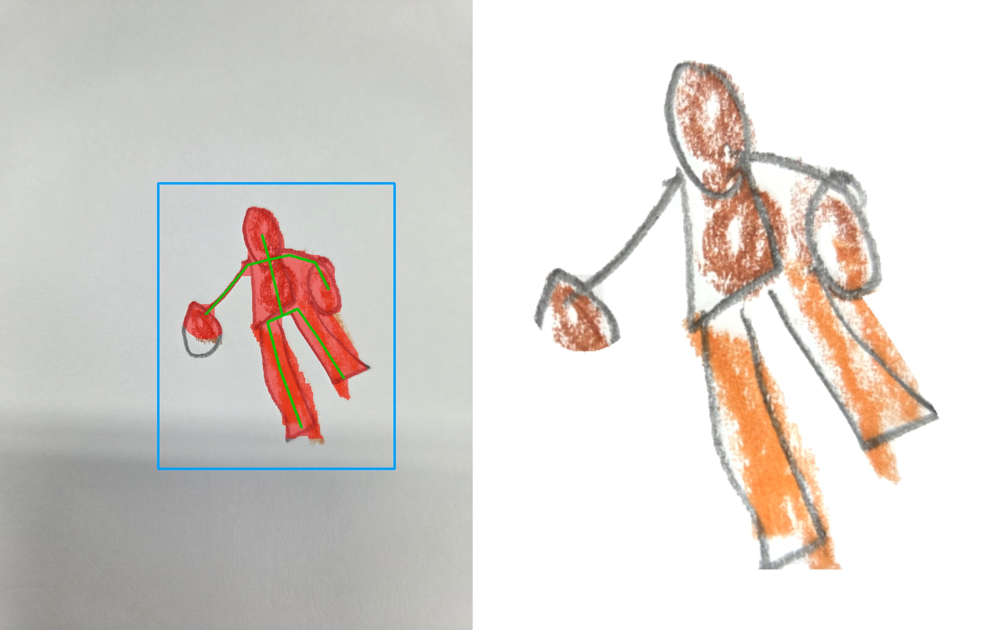

KakaoTalk_20261028_192709367_13.jpg


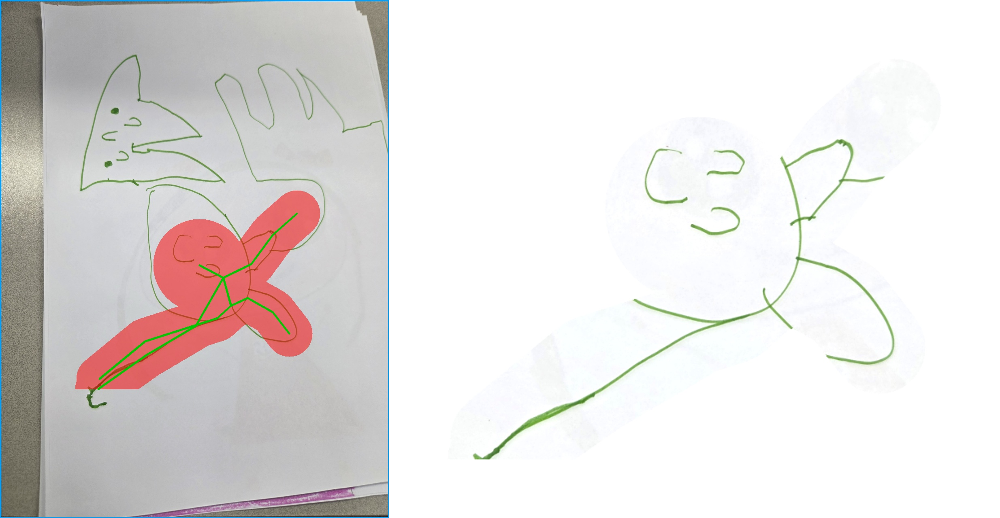

KakaoTalk_20261028_192709367_14.jpg


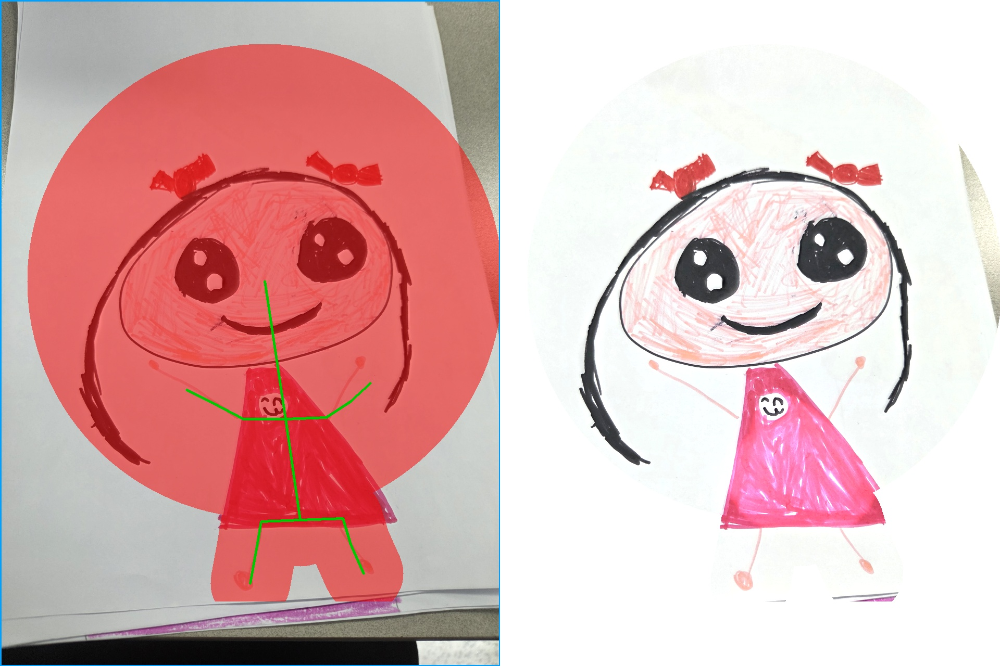

KakaoTalk_20261028_192709367_15.jpg


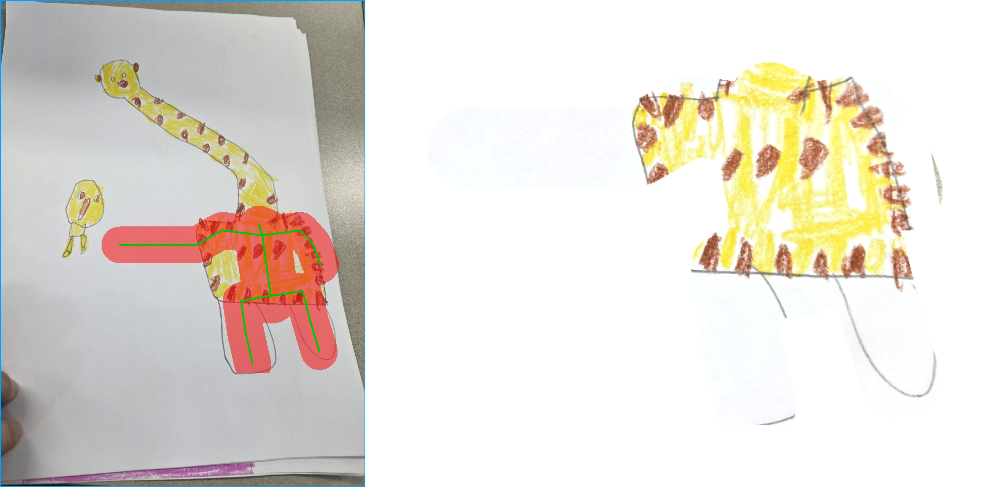

KakaoTalk_20261028_192709367_16.jpg


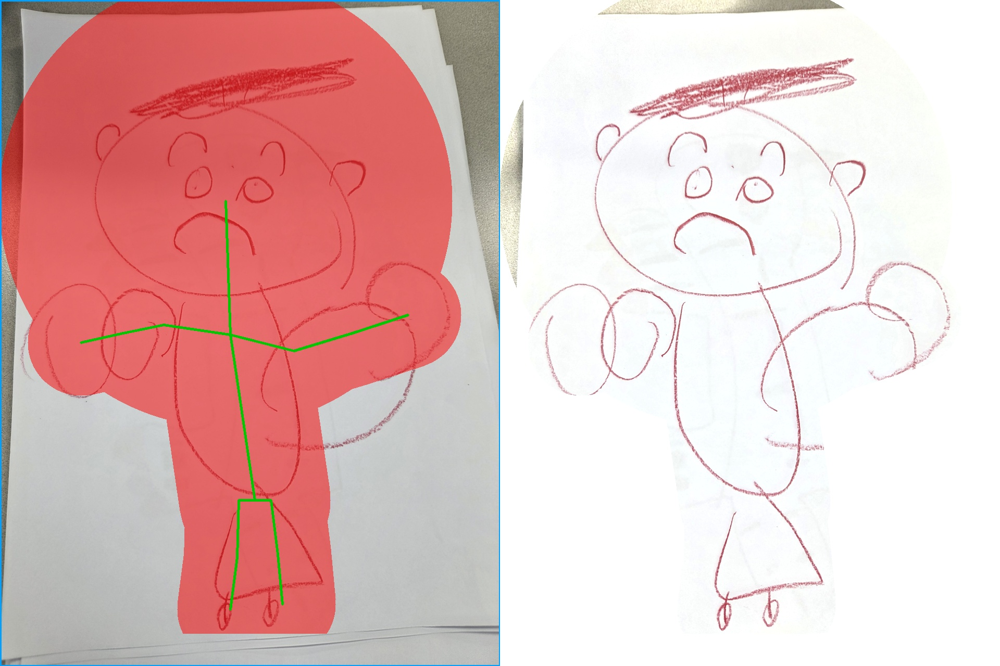

KakaoTalk_20261028_192709367_17.jpg


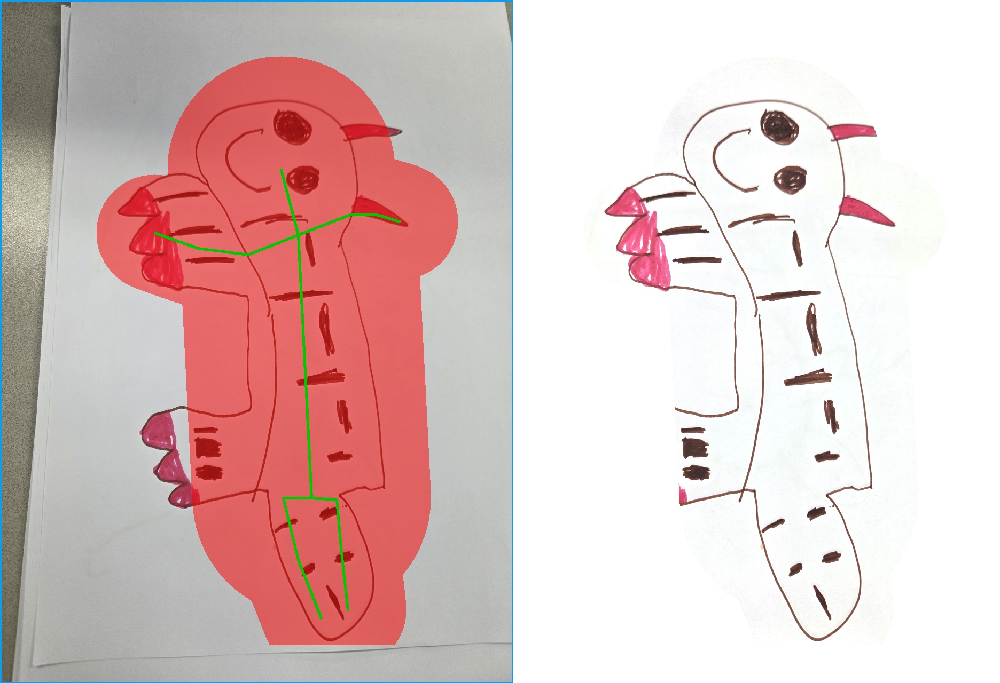

KakaoTalk_20261028_192709367_18.jpg


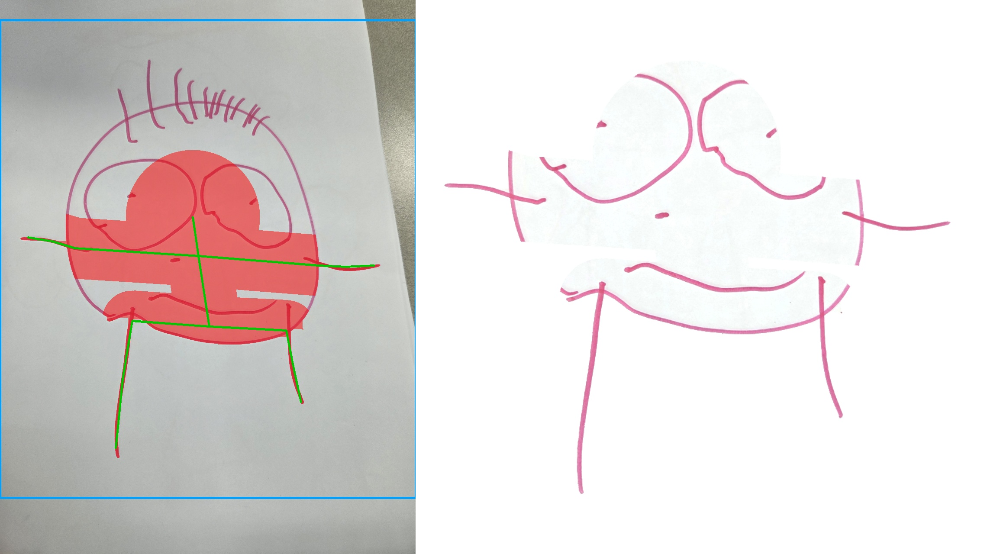

KakaoTalk_20261028_192709367_19.jpg


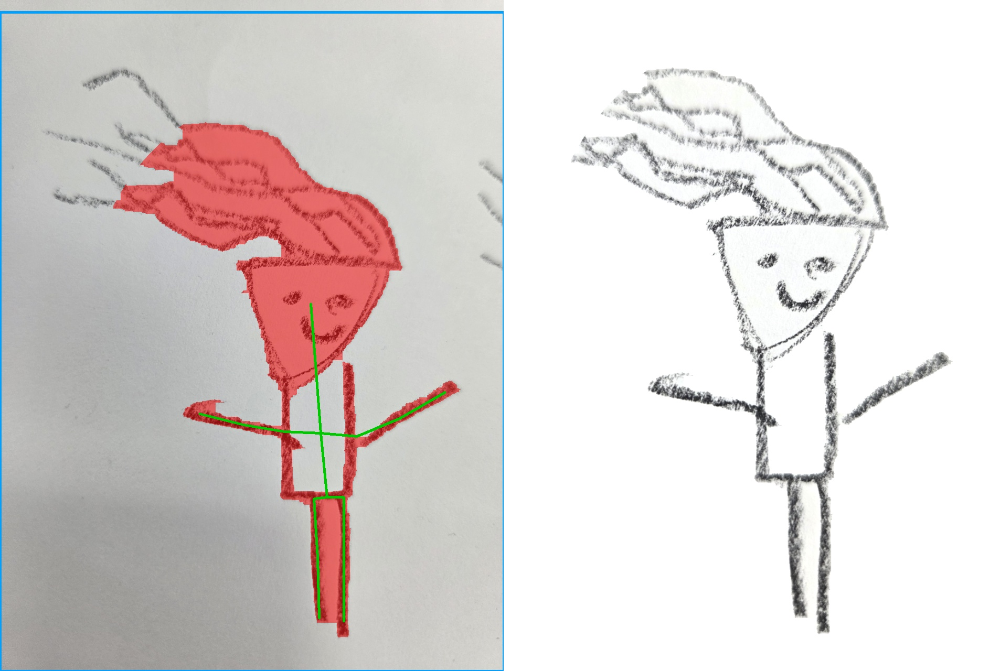

KakaoTalk_20261028_192709367_20.jpg


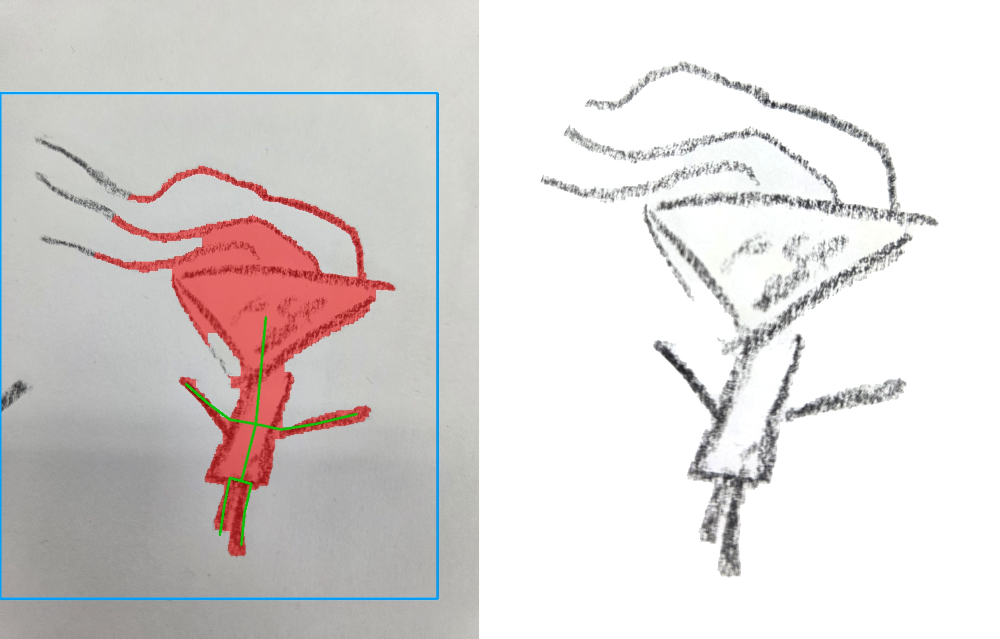

KakaoTalk_20261028_192709367_21.jpg


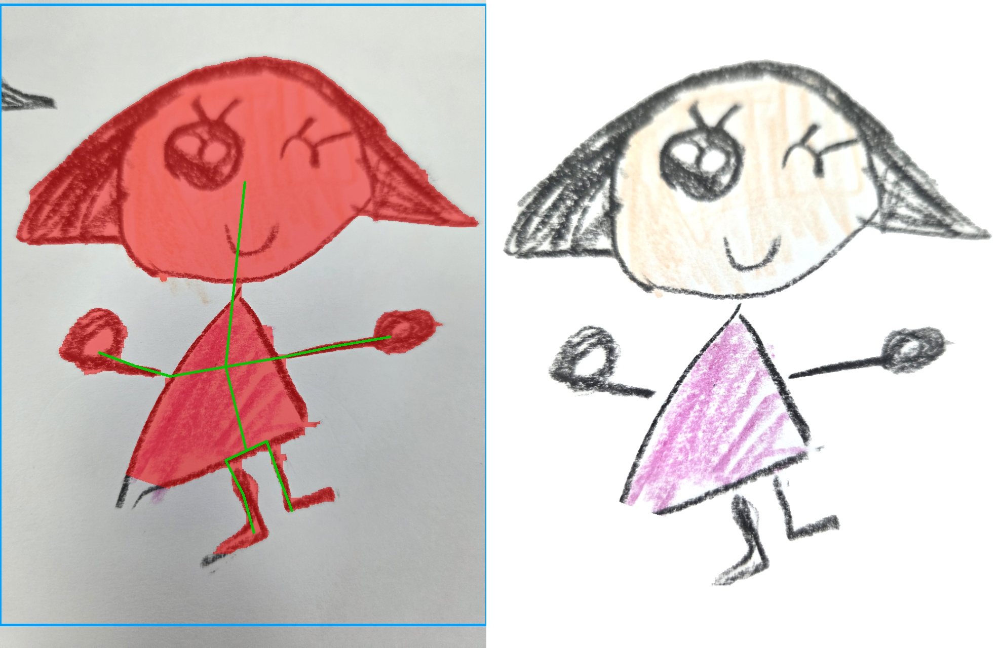

KakaoTalk_20261028_192709367_23.jpg


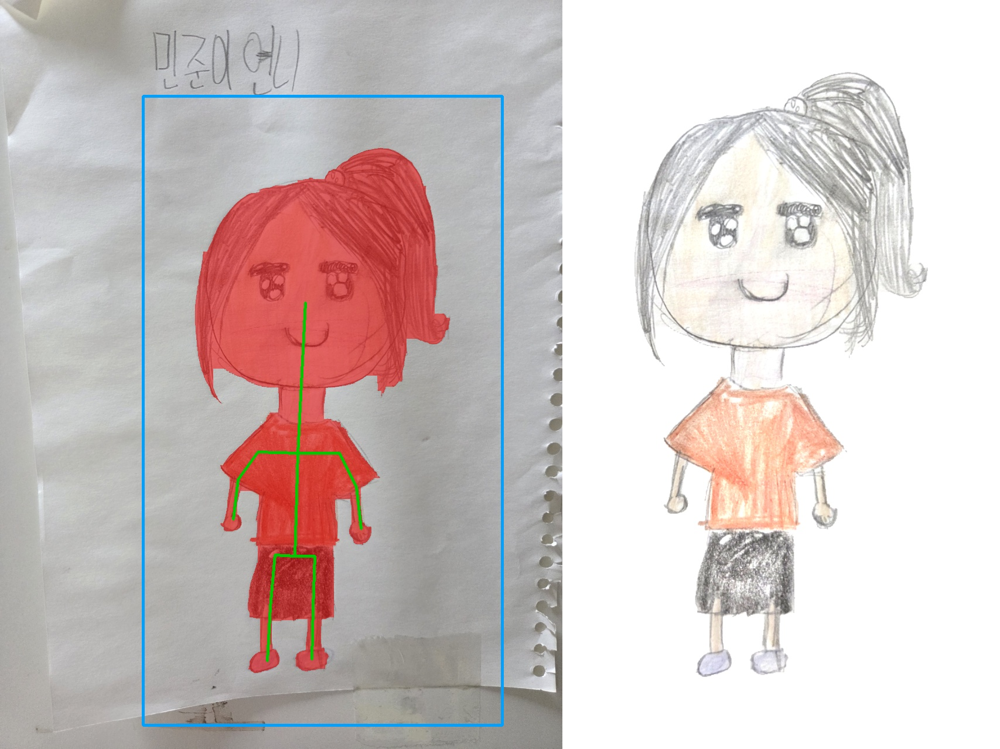


===== 동작 [0] image_1-1/1-1_006-C05 =====
KakaoTalk_20261028_192709367_12: mean score 0.71 -> -
KakaoTalk_20261028_192709367_13: mean score 0.40 -> -
KakaoTalk_20261028_192709367_14: mean score 0.69 -> -
KakaoTalk_20261028_192709367_15: mean score 0.51 -> -
KakaoTalk_20261028_192709367_16: mean score 0.69 -> -
KakaoTalk_20261028_192709367_17: mean score 0.48 -> -
KakaoTalk_20261028_192709367_18: mean score 0.66 -> -
KakaoTalk_20261028_192709367_19: mean score 0.81 -> -
KakaoTalk_20261028_192709367_20: mean score 0.75 -> -
KakaoTalk_20261028_192709367_21: mean score 0.79 -> -
KakaoTalk_20261028_192709367_23: mean score 0.82 -> -


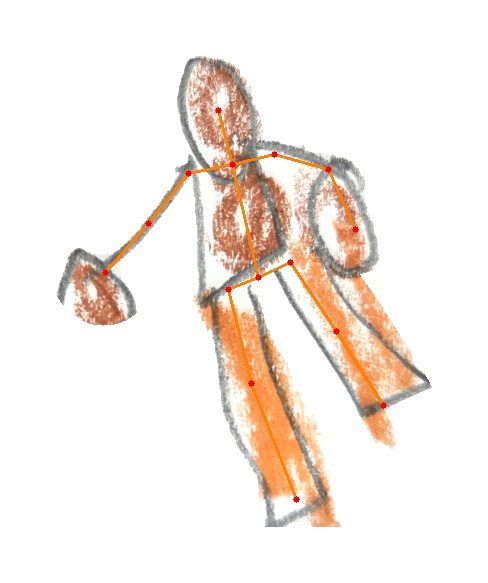

KakaoTalk_20261028_192709367_12


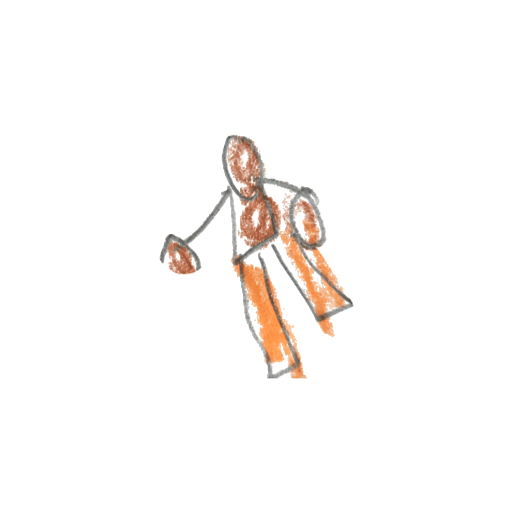

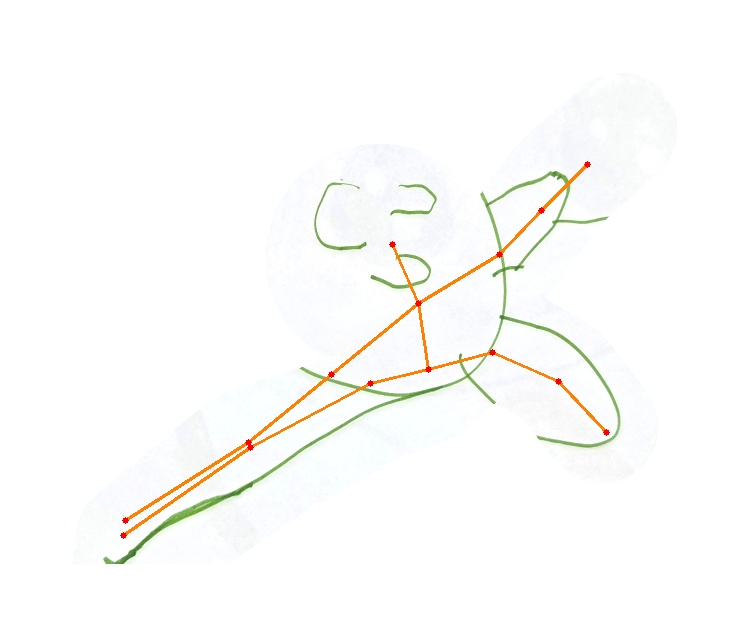

KakaoTalk_20261028_192709367_13


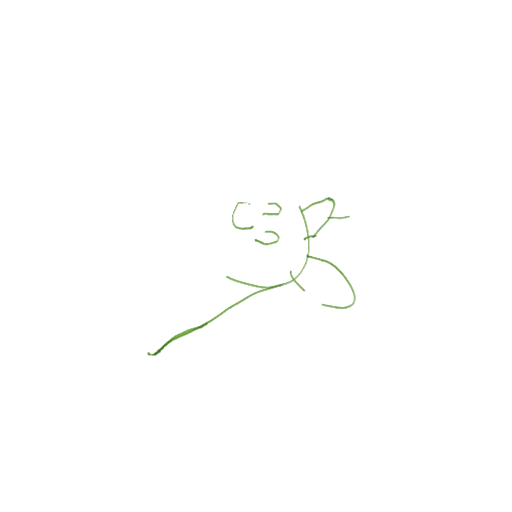

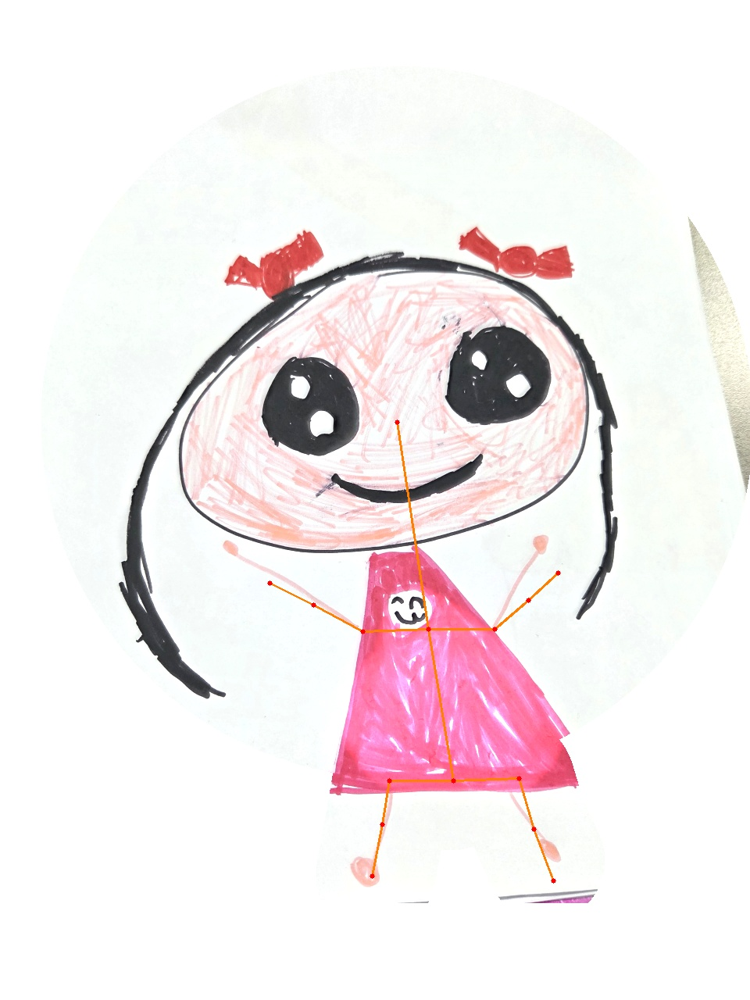

KakaoTalk_20261028_192709367_14


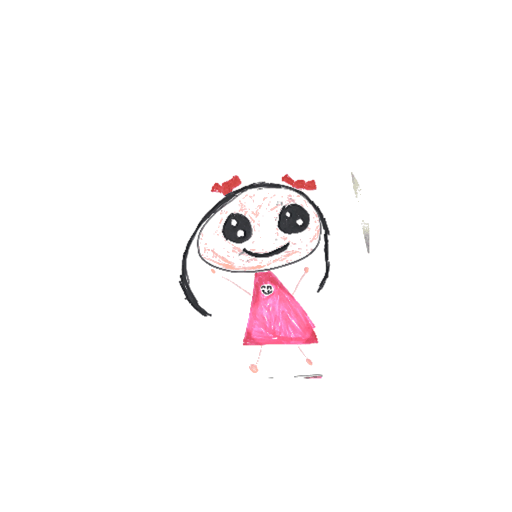

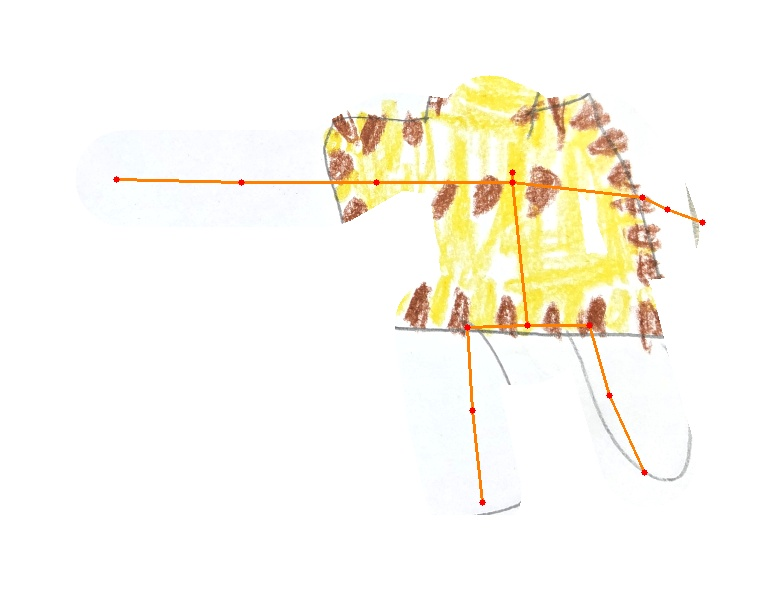

KakaoTalk_20261028_192709367_15


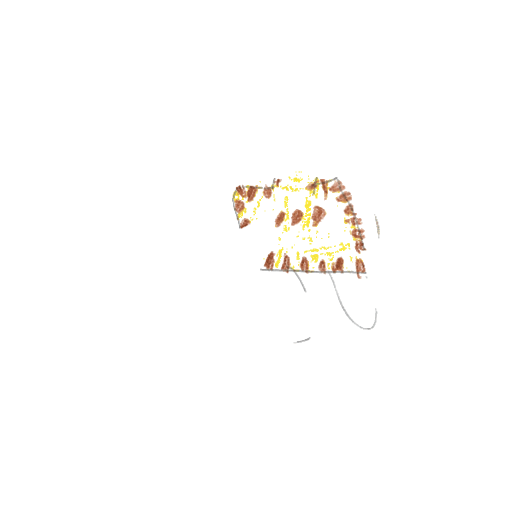

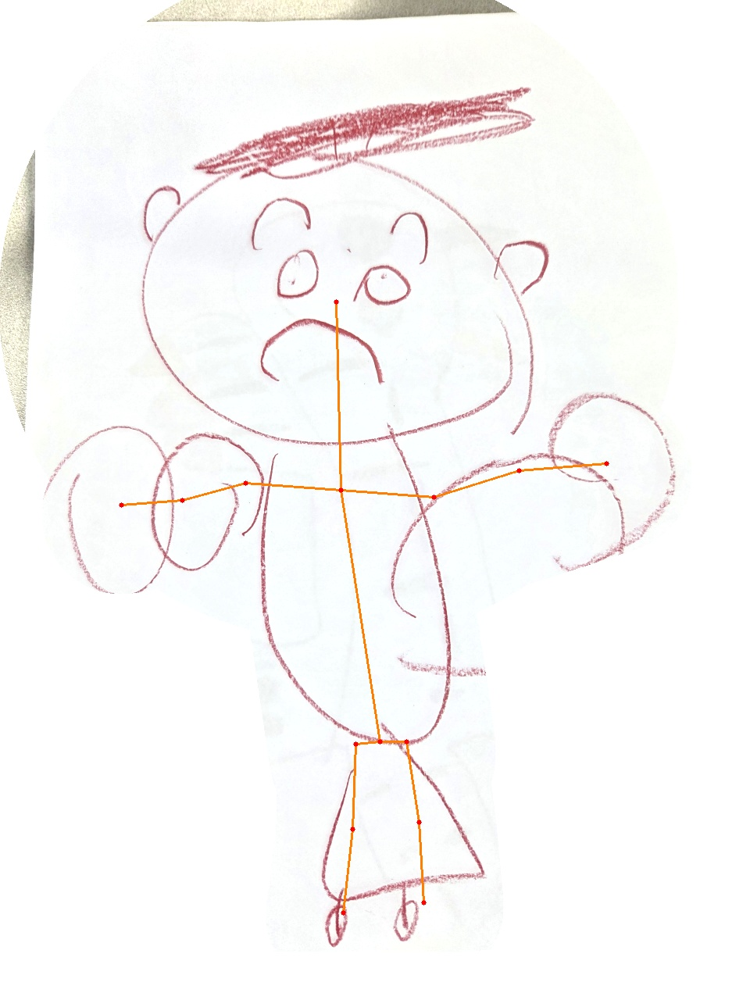

KakaoTalk_20261028_192709367_16


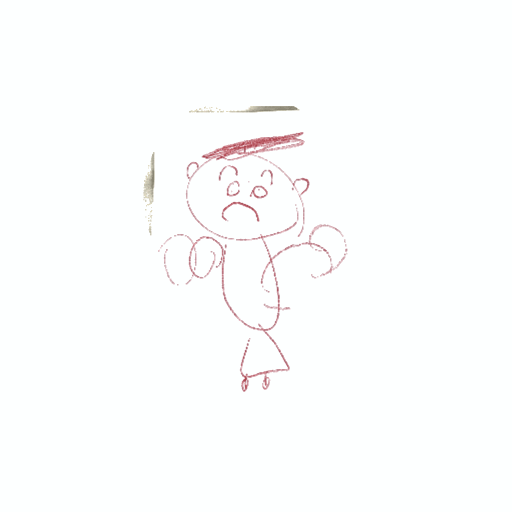

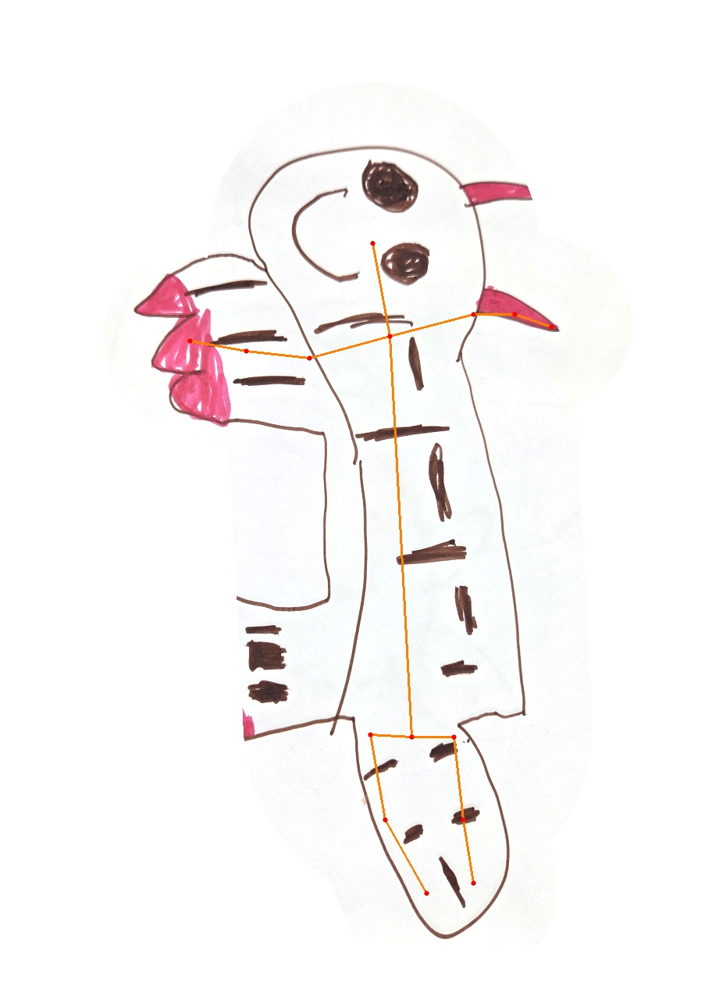

KakaoTalk_20261028_192709367_17


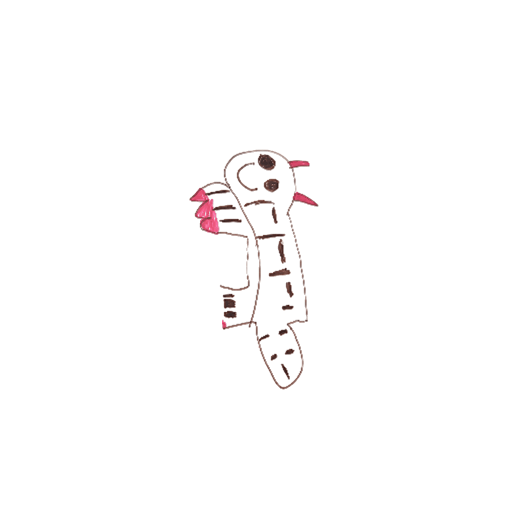

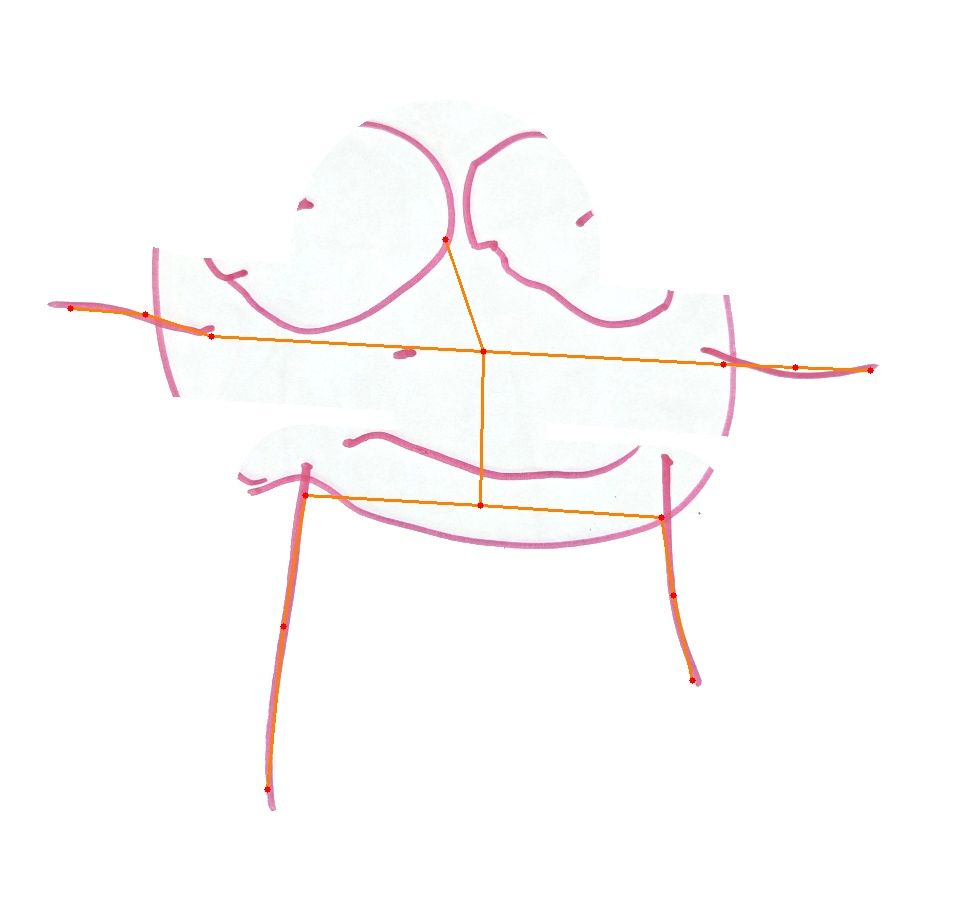

KakaoTalk_20261028_192709367_18


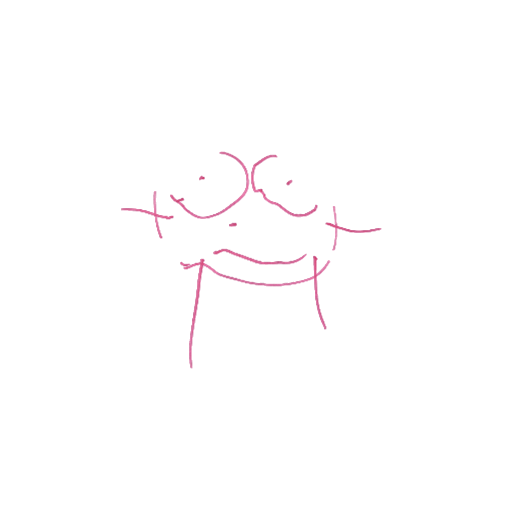

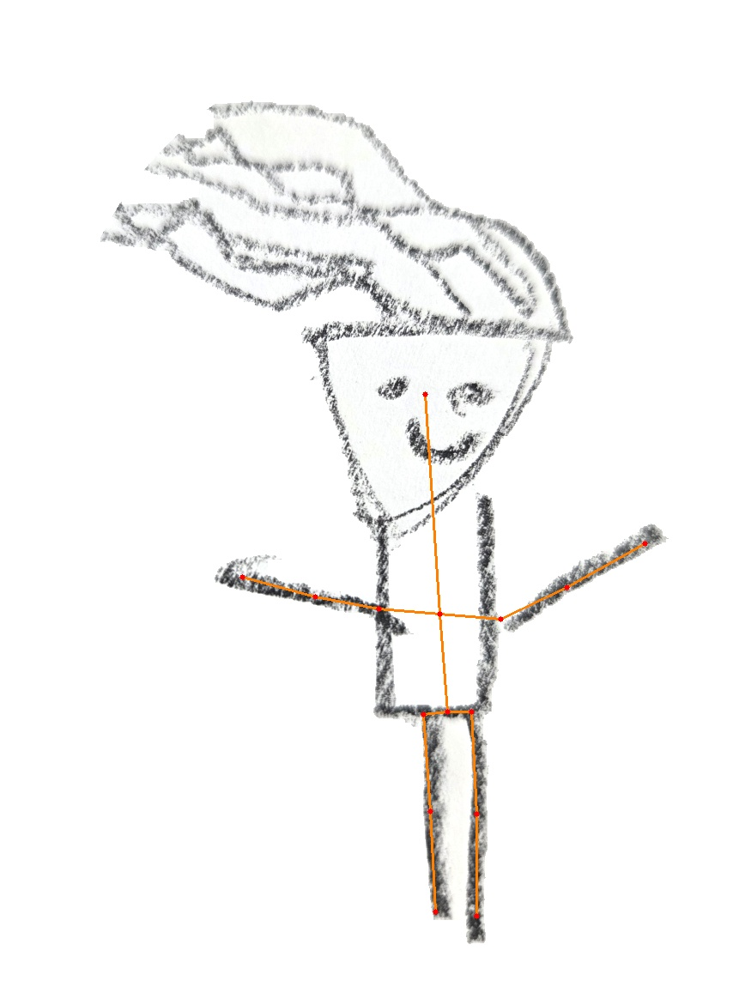

KakaoTalk_20261028_192709367_19


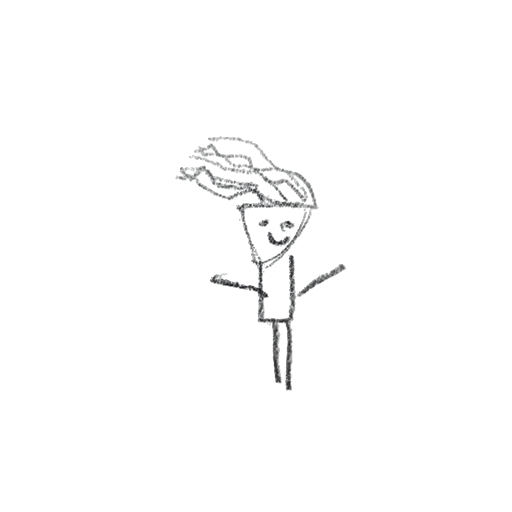

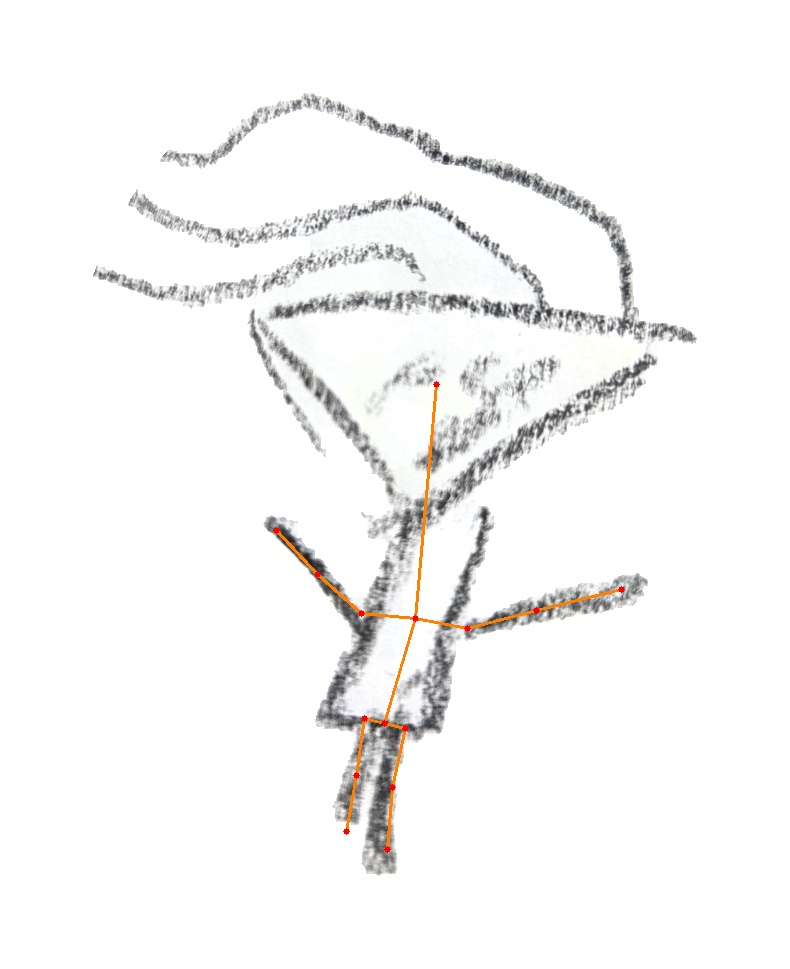

KakaoTalk_20261028_192709367_20


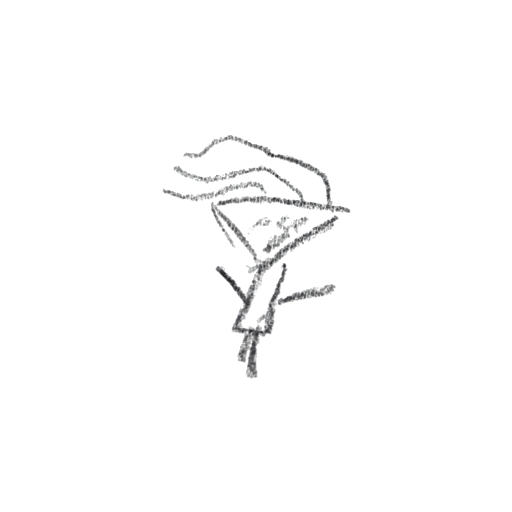

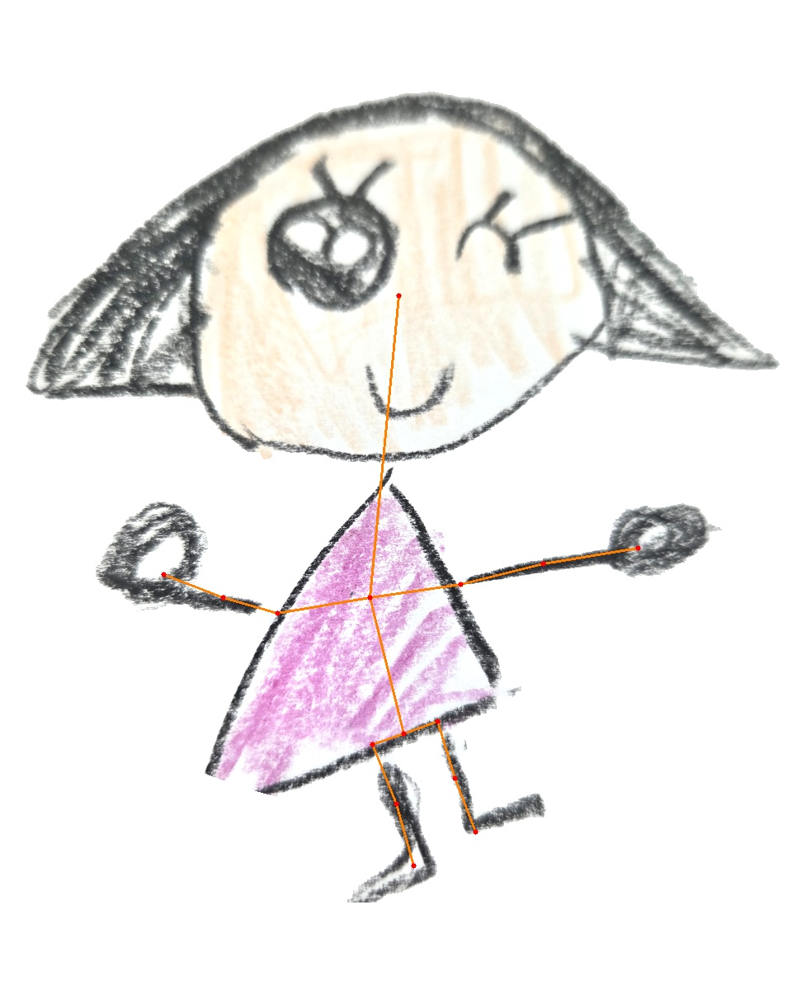

KakaoTalk_20261028_192709367_21


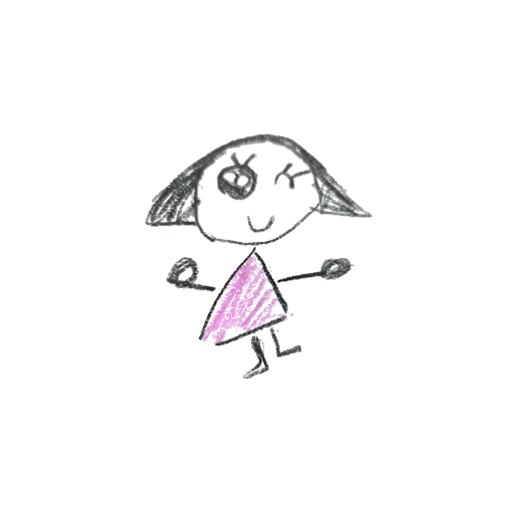

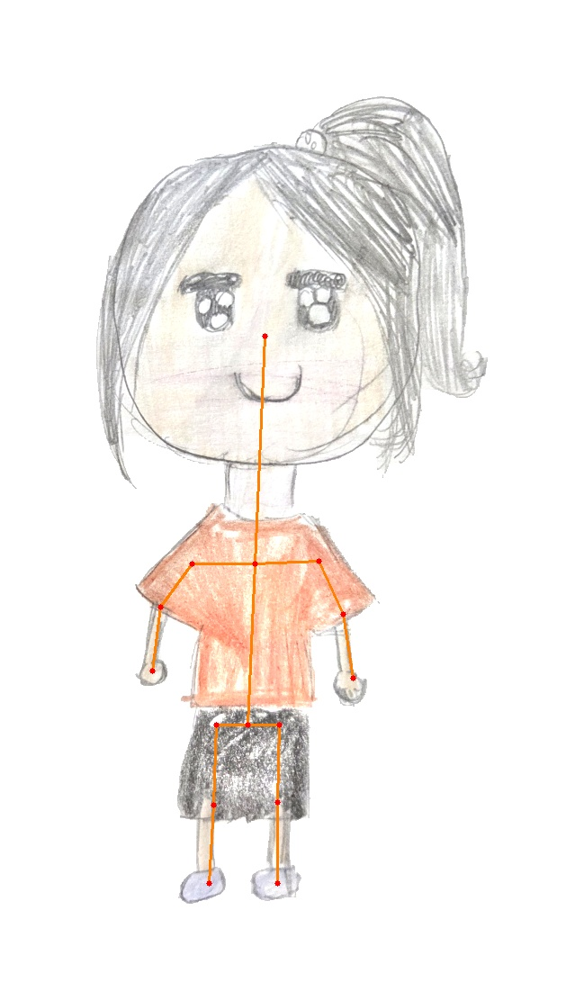

KakaoTalk_20261028_192709367_23


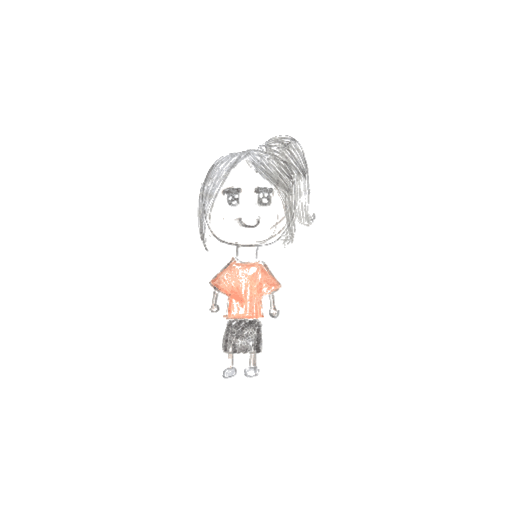


===== 동작 [1] image_1-1/1-1_008-C11 =====
KakaoTalk_20261028_192709367_12: mean score 0.71 -> -
KakaoTalk_20261028_192709367_13: mean score 0.40 -> -
KakaoTalk_20261028_192709367_14: mean score 0.69 -> -
KakaoTalk_20261028_192709367_15: mean score 0.51 -> -
KakaoTalk_20261028_192709367_16: mean score 0.69 -> -
KakaoTalk_20261028_192709367_17: mean score 0.48 -> -
KakaoTalk_20261028_192709367_18: mean score 0.66 -> -
KakaoTalk_20261028_192709367_19: mean score 0.81 -> -
KakaoTalk_20261028_192709367_20: mean score 0.75 -> -
KakaoTalk_20261028_192709367_21: mean score 0.79 -> -
KakaoTalk_20261028_192709367_23: mean score 0.82 -> -


KakaoTalk_20261028_192709367_12


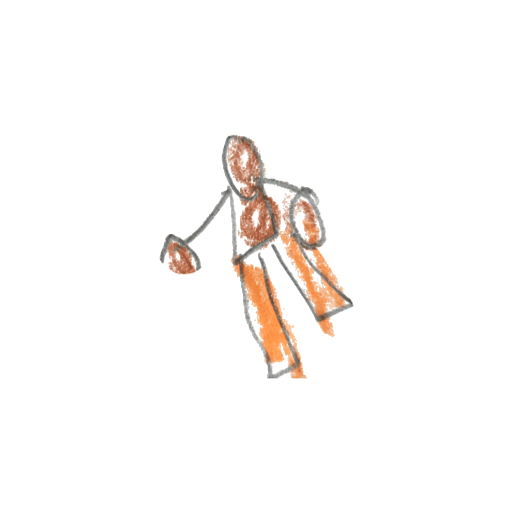

KakaoTalk_20261028_192709367_13


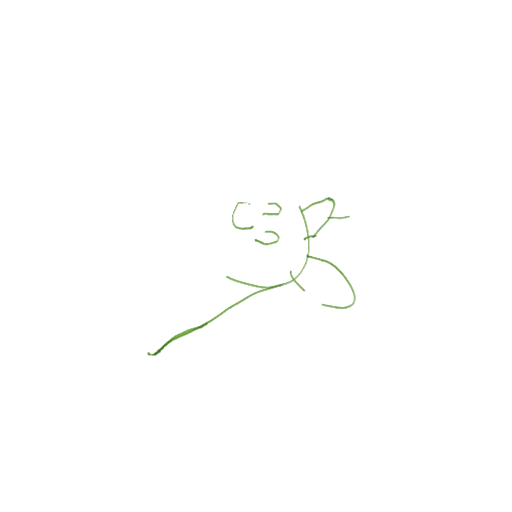

KakaoTalk_20261028_192709367_14


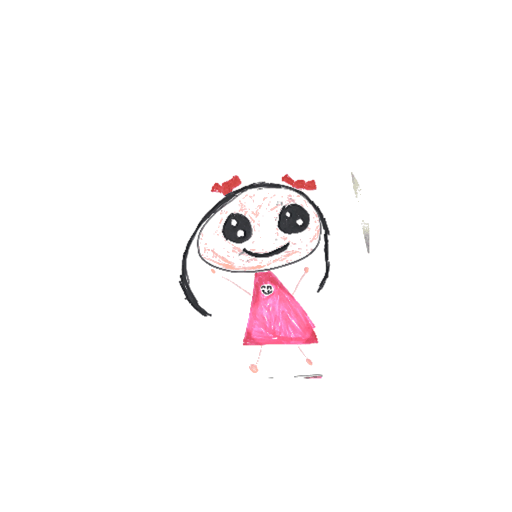

KakaoTalk_20261028_192709367_15


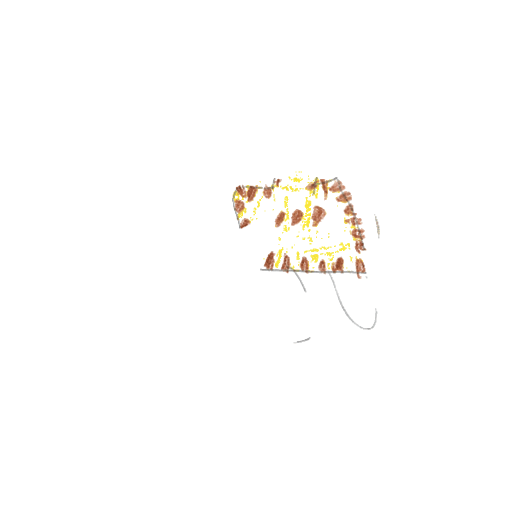

KakaoTalk_20261028_192709367_16


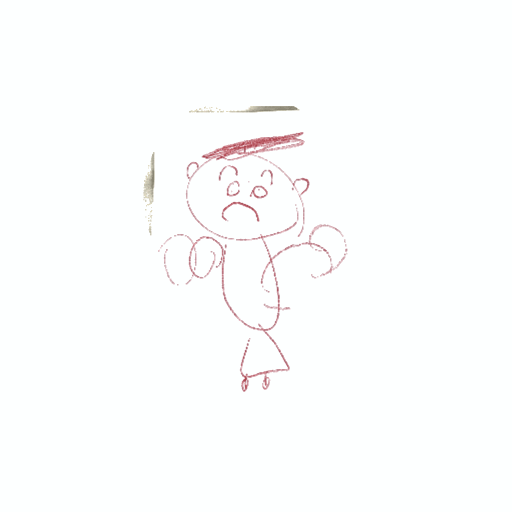

KakaoTalk_20261028_192709367_17


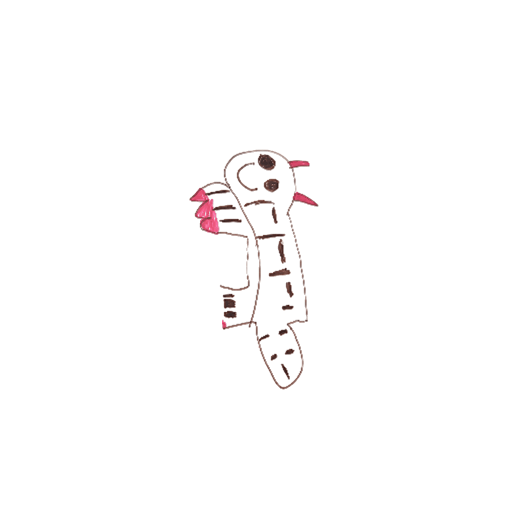

KakaoTalk_20261028_192709367_18


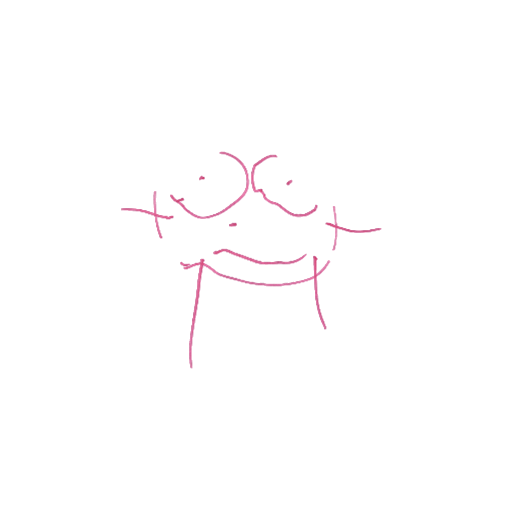

KakaoTalk_20261028_192709367_19


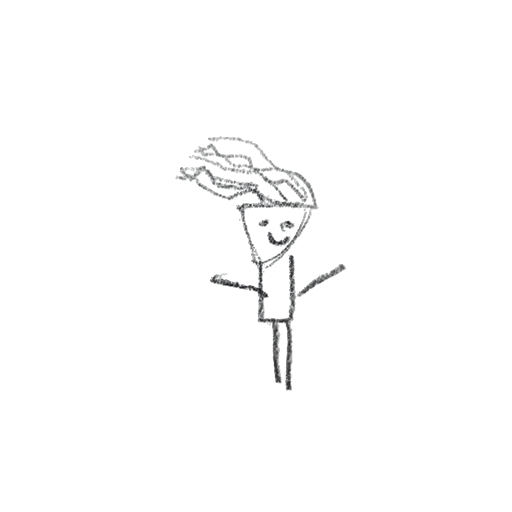

KakaoTalk_20261028_192709367_20


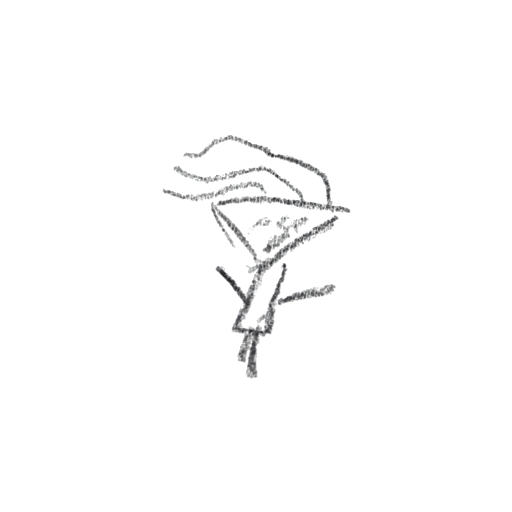

KakaoTalk_20261028_192709367_21


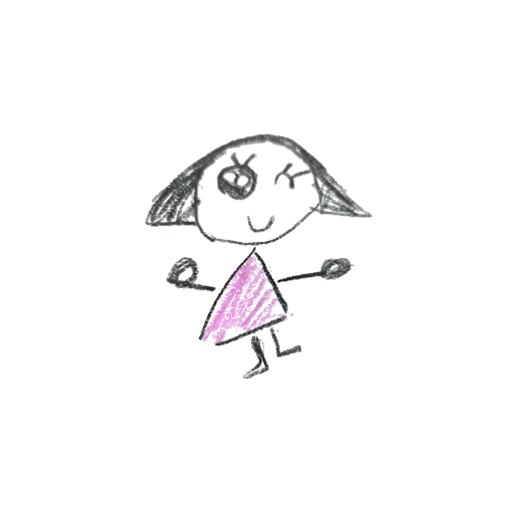

KakaoTalk_20261028_192709367_23


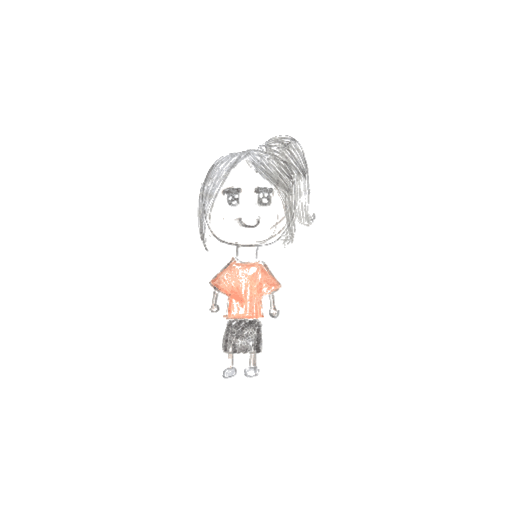


===== 동작 [2] image_1-1/1-1_601-C04 =====
KakaoTalk_20261028_192709367_12: mean score 0.71 -> -
KakaoTalk_20261028_192709367_13: mean score 0.40 -> -
KakaoTalk_20261028_192709367_14: mean score 0.69 -> -
KakaoTalk_20261028_192709367_15: mean score 0.51 -> -
KakaoTalk_20261028_192709367_16: mean score 0.69 -> -
KakaoTalk_20261028_192709367_17: mean score 0.48 -> -
KakaoTalk_20261028_192709367_18: mean score 0.66 -> -
KakaoTalk_20261028_192709367_19: mean score 0.81 -> -
KakaoTalk_20261028_192709367_20: mean score 0.75 -> -
KakaoTalk_20261028_192709367_21: mean score 0.79 -> -
KakaoTalk_20261028_192709367_23: mean score 0.82 -> -


KakaoTalk_20261028_192709367_12


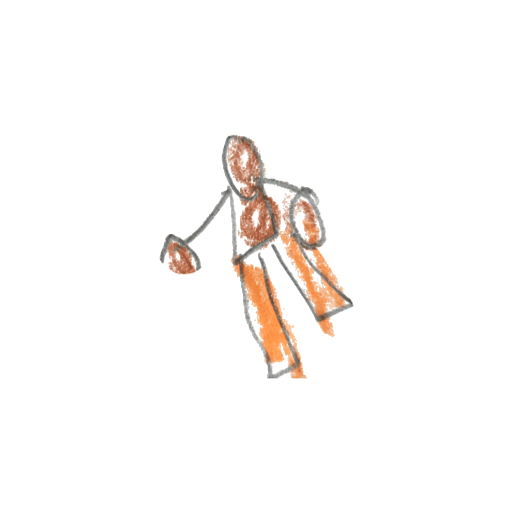

KakaoTalk_20261028_192709367_13


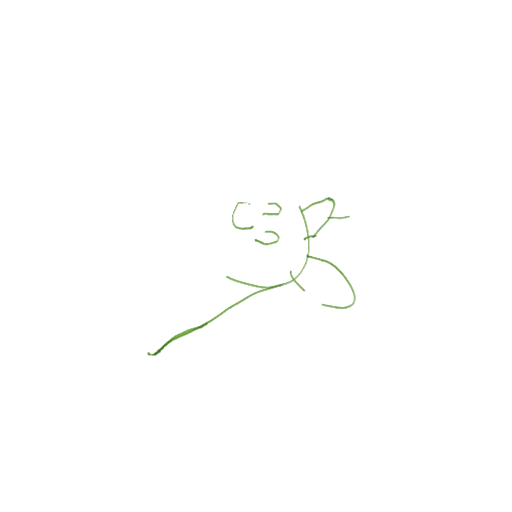

KakaoTalk_20261028_192709367_14


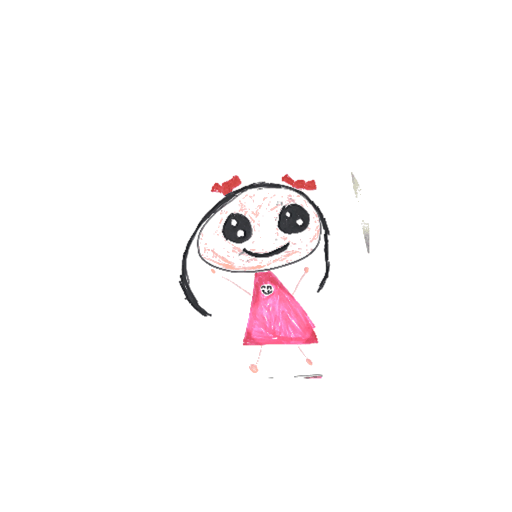

KakaoTalk_20261028_192709367_15


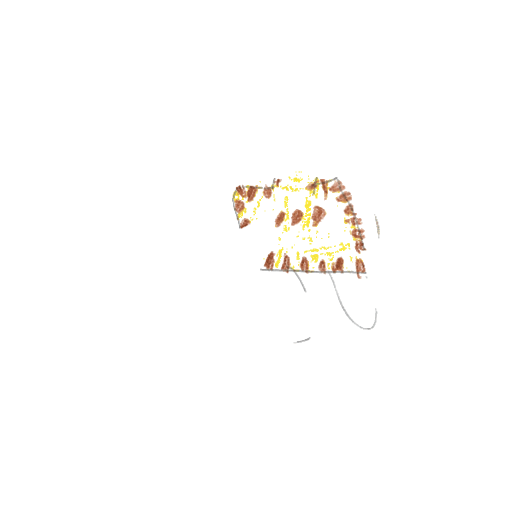

KakaoTalk_20261028_192709367_16


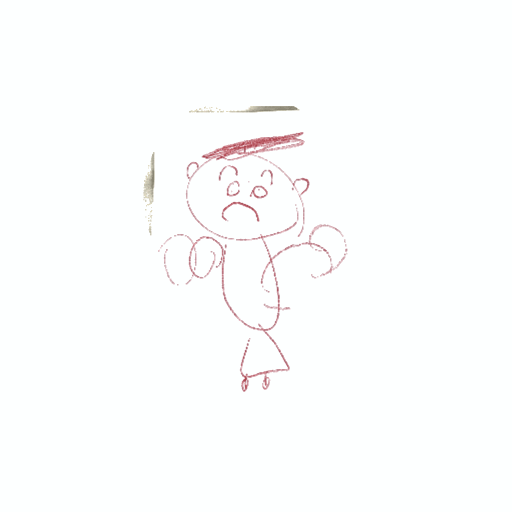

KakaoTalk_20261028_192709367_17


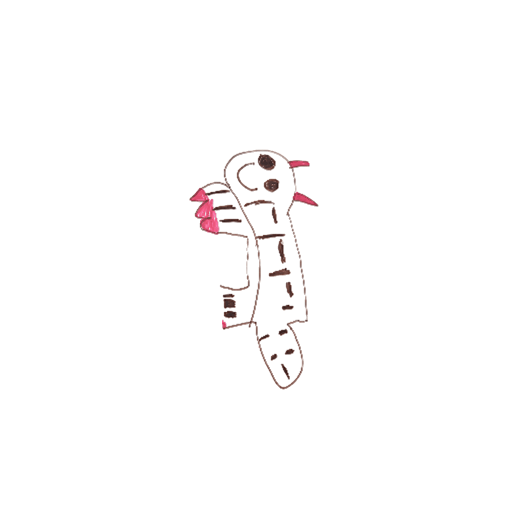

KakaoTalk_20261028_192709367_18


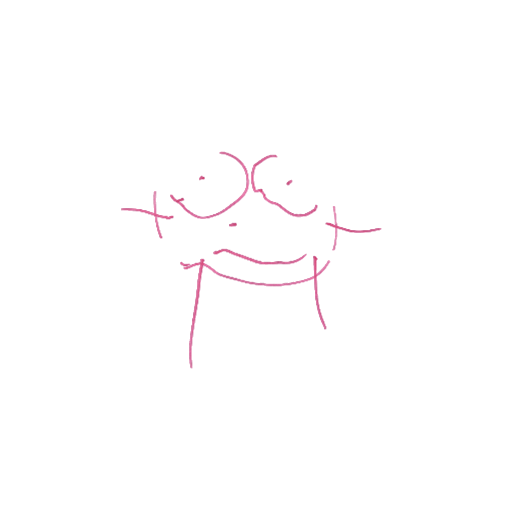

KakaoTalk_20261028_192709367_19


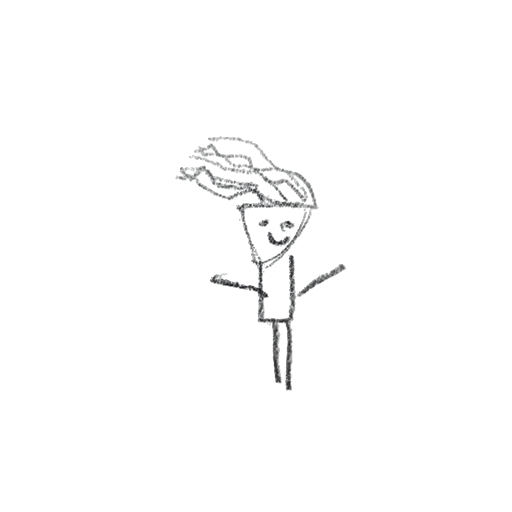

KakaoTalk_20261028_192709367_20


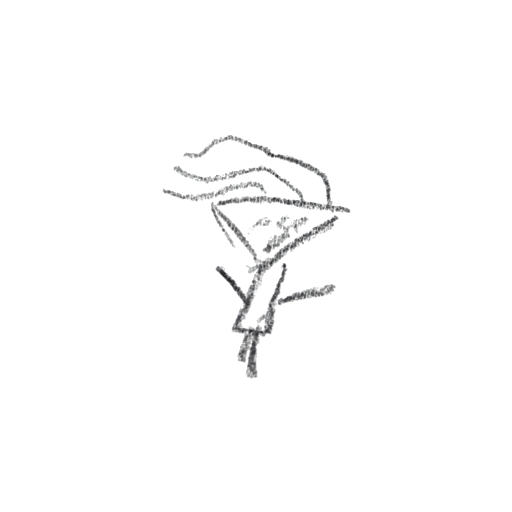

KakaoTalk_20261028_192709367_21


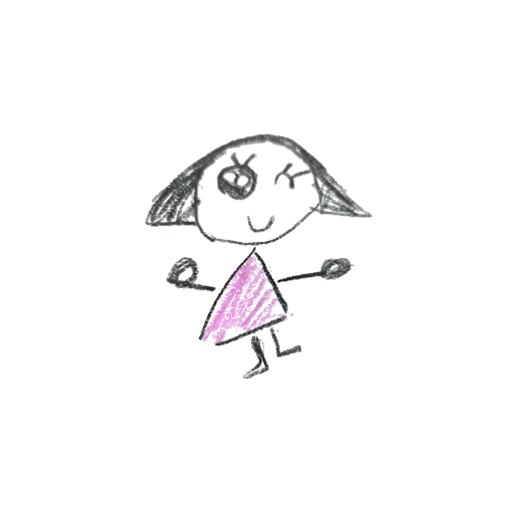

KakaoTalk_20261028_192709367_23


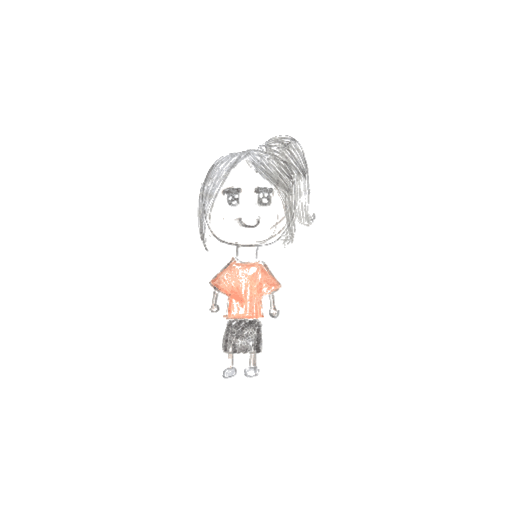

In [12]:
import os, glob, subprocess, shutil
from google.colab import files
from IPython.display import Image as IImage, Video, display

SELECT = [0, 1, 2]   # 위 목록에서 입힐 동작 번호
SEPARATE_BG = True   # 종이 사진이면 True: 배경(종이, 글씨, 그림자)을 지우고 인물만 잘라서 사용
MIRROR = False       # 그림이 동작과 좌우 반대로 움직이면 True
RELATIVE = True      # True: 그림의 원래 자세에서 사람이 움직인 만큼만 / False: 사람 자세를 그대로 따라 함
FOLLOW_ROOT = False  # 몸 이동까지 따라 할지 (제자리 동작은 False)

ENV = {**os.environ, "MPLBACKEND": "Agg"}
PY = ["/usr/local/miniconda/bin/conda", "run", "--no-capture-output", "-n", "mmpose_env", "python", "-u"]

# 1) 그림 업로드
shutil.rmtree("/content/my_imgs", ignore_errors=True); os.makedirs("/content/my_imgs")
for n in files.upload():
    shutil.move(n, f"/content/my_imgs/{n}")

# 2) 배경 분리 (내 모델로 관절 → 관절 주변 몸 영역의 잉크만 남김)
SRC_DIR = "/content/my_imgs"
if SEPARATE_BG:
    shutil.rmtree("/content/my_imgs_clean", ignore_errors=True)
    r = subprocess.run(PY + ["/content/segment_drawing.py", "/content/my_imgs", "/content/my_imgs_clean"],
                       capture_output=True, text=True, env=ENV)
    print(r.stdout[-2000:])
    if r.returncode:
        print(r.stderr[-2000:]); raise SystemExit("배경 분리 실패")
    for d in sorted(glob.glob("/content/my_imgs_clean/_debug/*.jpg")):   # 왼쪽: 남긴 영역(빨강)/관절(초록), 오른쪽: 결과
        print(os.path.basename(d)); display(IImage(d, width=520))
    SRC_DIR = "/content/my_imgs_clean"

# 3) 동작 입히기
for k, i in enumerate(SELECT):
    m = motions[i]
    out = f"/content/anim_motion/{m['stem']}"
    shutil.rmtree(out, ignore_errors=True)
    cmd = (PY + ["/content/animate_drawing.py", "--src", SRC_DIR, "--seq", m["npy"], "--seq-fps", str(m["fps"]),
                 "--motions", "", "--out", out]
           + (["--mirror"] if MIRROR else []) + (["--relative"] if RELATIVE else [])
           + ([] if FOLLOW_ROOT else ["--no-root"]))
    r = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
    if r.returncode:
        print("실패:", m["seq"]); print(r.stdout[-1500:]); print(r.stderr[-1500:]); continue
    print(f"\n===== 동작 [{i}] {m['seq']} =====")
    print("\n".join(l for l in r.stdout.splitlines() if "mean score" in l))     # 그림별 관절 신뢰도
    src = MOTION_ROOT / "previews" / f"{m['stem']}_frames.mp4"                    # 원본 사람 동작 (비교용)
    if src.exists():
        display(Video(str(src), embed=True, width=320))
    for g in sorted(glob.glob(f"{out}/*_video.gif")):
        name = os.path.basename(g)[:-len("_video.gif")]
        if k == 0:                                                                # 내 모델이 뽑은 관절 (첫 동작에서만)
            display(IImage(f"{out}/{name}_pose.jpg", width=320))
        print(name); display(IImage(g, width=320))

## 7. 결과 내려받기

In [13]:
!cd /content && zip -qr anim_motion.zip anim_motion && ls -la /content/anim_motion.zip
from google.colab import files
files.download("/content/anim_motion.zip")

-rw-r--r-- 1 root root 35351808 Oct 30 06:12 /content/anim_motion.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#평가

In [15]:
%%writefile /content/eval_motion.py
"""동작 입히기 성능 확인 (정답 관절 없이 측정).
① 재검출 일치도: 움직인 그림의 각 프레임을 내 모델로 다시 추정 → 뼈대가 의도한 관절 위치와 비교
   (그림이 찢어지거나 번지면 모델이 엉뚱한 곳을 찾음). 기준선 = 움직이기 전 그림의 같은 측정값
② 형태 유지: 프레임별 그림 면적 / 원래 면적 (찢어지면 줄고, 번지면 늘어남)
③ 떨림: 관절 가속도 평균 (몸 크기 대비)
사용: python eval_motion.py <그림 폴더> <출력 폴더> <npy:fps> [<npy:fps> ...] [--relative] [--no-root] [--mirror] [--stride N]"""
import os, sys, glob, json, csv
os.environ.setdefault('MPLBACKEND', 'Agg')
import cv2
import numpy as np
sys.path.insert(0, '/content')
import animate_drawing as ad

J15 = ['nose', 'neck', 'r_sho', 'r_elb', 'r_wri', 'l_sho', 'l_elb', 'l_wri',
       'pelvis', 'r_hip', 'r_knee', 'r_ank', 'l_hip', 'l_knee', 'l_ank']
ARMS = [3, 4, 6, 7]
SW = [0, 1, 5, 6, 7, 2, 3, 4, 8, 12, 13, 14, 9, 10, 11]


def ink(frame, bg):
    g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY).astype(np.int16)
    return g < int(np.mean(bg)) - 30


def redetect(model, frame, bg, infer):
    m = ink(frame, bg).astype(np.uint8)
    if m.sum() == 0:
        return None, None
    x, y, w, h = cv2.boundingRect(m)
    p = int(max(w, h) * 0.1)
    box = [max(0, x - p), max(0, y - p), min(frame.shape[1], x + w + p), min(frame.shape[0], y + h + p)]
    r = infer(model, frame, bboxes=np.array([box], np.float32), bbox_format='xyxy')[0]
    return np.asarray(r.pred_instances.keypoints[0], float), max(box[2] - box[0], box[3] - box[1])


def frames_for(img, kp, seq, relative, follow_root, mirror, stride):
    """animate_drawing.make_gif_seq와 같은 계산으로 (프레임, 의도한 관절 위치)를 만든다."""
    crop, rest, _ = ad.prep(img, np.asarray(kp, np.float64), [0, 0, img.shape[1], img.shape[0]], 512)
    S = max(np.ptp(rest[:, 0]), np.ptp(rest[:, 1]), 40)
    B = ad.bind(crop, rest, S)
    seq = np.asarray(seq, np.float64).copy()
    if mirror:
        seq[:, :, 0] *= -1
        seq = seq[:, SW]
    body = max(np.ptp(seq[0, :, 1]), 1.0)
    cb0 = ad.retarget(rest, seq[0], 1.0)
    zero = {k: 0.0 for k in cb0}
    rest_frame = ad.render(B, rest, rest, zero)
    out = []
    for t in range(0, len(seq), stride):
        cb = ad.retarget(rest, seq[t], 1.0)
        if relative:
            cb = {k: ad._wrap(v - cb0[k]) for k, v in cb.items()}
        tr = (seq[t, 8] - seq[0, 8]) * (np.ptp(rest[:, 1]) / body) if follow_root else np.zeros(2)
        pos = ad.pose_from_bones(rest, cb, tr)
        out.append((t, ad.render(B, rest, pos, cb), pos))
    return rest_frame, rest, out, B['bg']


def overlay(frame, target, pred):
    v = frame.copy()
    for p, c in ad.SKEL:
        cv2.line(v, tuple(map(int, target[p])), tuple(map(int, target[c])), (0, 180, 0), 2)
        cv2.line(v, tuple(map(int, pred[p])), tuple(map(int, pred[c])), (0, 0, 230), 1)
    return v


def main():
    args = sys.argv[1:]
    flags = {a for a in args if a.startswith('--')}
    stride = 2
    if '--stride' in args:
        stride = int(args[args.index('--stride') + 1]); args.remove(args[args.index('--stride') + 1])
    pos_args = [a for a in args if not a.startswith('--')]
    src, dst, seqs = pos_args[0], pos_args[1], pos_args[2:]
    os.makedirs(f'{dst}/worst', exist_ok=True)
    from mmpose.apis import init_model, inference_topdown
    model = init_model(ad.CFG, ad.CKPT, device=ad.DEV)
    files = sorted(f for e in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG') for f in glob.glob(os.path.join(src, e)))
    rows, joint_err = [], {}
    for f in files:
        name = os.path.splitext(os.path.basename(f))[0]
        img = cv2.imread(f)
        h, w = img.shape[:2]
        r = inference_topdown(model, img, bboxes=np.array([[0, 0, w, h]], np.float32), bbox_format='xyxy')[0]
        kp = np.asarray(r.pred_instances.keypoints[0], float)
        for spec in seqs:
            npy, fps = spec.rsplit(':', 1)
            motion = os.path.splitext(os.path.basename(npy))[0]
            seq = ad.smooth_seq(np.load(npy))
            rest_frame, rest, fr, bg = frames_for(img, kp, seq, '--relative' in flags, '--no-root' not in flags,
                                                  '--mirror' in flags, stride)
            base_area = ink(rest_frame, bg).sum()
            p0, s0 = redetect(model, rest_frame, bg, inference_topdown)
            e0 = np.linalg.norm(p0 - rest, axis=1) / s0 if p0 is not None else np.full(15, np.nan)
            errs, areas, recs = [], [], []
            for t, frame, pos in fr:
                pred, size = redetect(model, frame, bg, inference_topdown)
                if pred is None:
                    errs.append(np.full(15, np.nan)); areas.append(0.0); continue
                e = np.linalg.norm(pred - pos, axis=1) / size          # 몸(bbox) 크기 대비 거리 = PCK 기준과 동일
                errs.append(e); areas.append(ink(frame, bg).sum() / max(base_area, 1))
                recs.append((float(np.nanmean(e)), t, frame, pos, pred))
            E = np.array(errs)
            P = np.array([p for _, _, p in fr])
            jitter = float(np.nanmean(np.linalg.norm(np.diff(P, 2, axis=0), axis=2)) / max(np.ptp(rest[:, 1]), 1)) if len(P) > 2 else 0.0
            row = dict(image=name, motion=motion, frames=len(fr),
                       rest_pck05=round(float(np.nanmean(e0 < 0.05)), 3), rest_pck10=round(float(np.nanmean(e0 < 0.10)), 3),
                       pck05=round(float(np.nanmean(E < 0.05)), 3), pck10=round(float(np.nanmean(E < 0.10)), 3),
                       arm_pck10=round(float(np.nanmean(E[:, ARMS] < 0.10)), 3),
                       worst_frame_pck10=round(float(np.nanmin(np.nanmean(E < 0.10, axis=1))), 3),
                       area_min=round(float(np.min(areas)), 3), area_max=round(float(np.max(areas)), 3),
                       jitter=round(jitter, 4))
            rows.append(row)
            for j in range(15):
                joint_err.setdefault(J15[j], []).extend(E[:, j][~np.isnan(E[:, j])].tolist())
            recs.sort(key=lambda r: -r[0])                           # 가장 많이 어긋난 프레임 3장 저장
            for k, (m, t, frame, pos, pred) in enumerate(recs[:3]):
                cv2.imwrite(f'{dst}/worst/{name}__{motion}__{k}_t{t}.jpg', overlay(frame, pos, pred))
            print(f"{name} | {motion} | 재검출 PCK@0.1 {row['pck10']:.2f} (움직이기 전 {row['rest_pck10']:.2f}) | "
                  f"팔 {row['arm_pck10']:.2f} | 최악 프레임 {row['worst_frame_pck10']:.2f} | "
                  f"면적 {row['area_min']:.2f}~{row['area_max']:.2f} | 떨림 {row['jitter']:.4f}", flush=True)
    with open(f'{dst}/summary.csv', 'w', newline='', encoding='utf-8-sig') as fo:
        w = csv.DictWriter(fo, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    jt = {j: dict(pck10=round(float(np.mean(np.array(v) < 0.1)), 3), mean_err=round(float(np.mean(v)), 4)) for j, v in joint_err.items()}
    json.dump(jt, open(f'{dst}/per_joint.json', 'w'), ensure_ascii=False, indent=1)


if __name__ == '__main__':
    main()

Overwriting /content/eval_motion.py


 | image_1-1_1-1_008-C11 | 재검출 PCK@0.1 0.80 (움직이기 전 0.73) | 팔 0.50 | 최악 프레임 0.73 | 면적 0.90~1.01 | 떨림 0.0102
KakaoTalk_20261028_192709367_13 | image_1-1_1-1_601-C04 | 재검출 PCK@0.1 0.50 (움직이기 전 0.73) | 팔 0.22 | 최악 프레임 0.20 | 면적 0.70~1.00 | 떨림 0.0300
KakaoTalk_20261028_192709367_14 | image_1-1_1-1_006-C05 | 재검출 PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 프레임 1.00 | 면적 0.96~1.00 | 떨림 0.0023
KakaoTalk_20261028_192709367_14 | image_1-1_1-1_008-C11 | 재검출 PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 프레임 1.00 | 면적 0.92~1.01 | 떨림 0.0051
KakaoTalk_20261028_192709367_14 | image_1-1_1-1_601-C04 | 재검출 PCK@0.1 0.62 (움직이기 전 1.00) | 팔 0.45 | 최악 프레임 0.13 | 면적 0.69~1.01 | 떨림 0.0183
KakaoTalk_20261028_192709367_15 | image_1-1_1-1_006-C05 | 재검출 PCK@0.1 0.73 (움직이기 전 0.73) | 팔 0.50 | 최악 프레임 0.67 | 면적 0.99~1.01 | 떨림 0.0039
KakaoTalk_20261028_192709367_15 | image_1-1_1-1_008-C11 | 재검출 PCK@0.1 0.66 (움직이기 전 0.73) | 팔 0.50 | 최악 프레임 0.47 | 면적 0.99~1.01 | 떨림 0.0098
KakaoTalk_20261028_192709367_15 | image_1-1_1-1_601-C04 | 

,image,motion,frames,rest_pck05,rest_pck10,pck05,pck10,arm_pck10,worst_frame_pck10,area_min,area_max,jitter,재검출 하락
0,KakaoTalk_20261028_192709367_12,image_1-1_1-1_006-C05,43,1.000,1.000,1.000,1.000,1.000,1.000,0.997,1.038,0.0026,0.000
1,KakaoTalk_20261028_192709367_12,image_1-1_1-1_008-C11,51,1.000,1.000,0.937,0.986,1.000,0.800,0.949,1.061,0.0083,0.014
2,KakaoTalk_20261028_192709367_12,image_1-1_1-1_601-C04,36,1.000,1.000,0.522,0.644,0.576,0.133,0.614,1.000,0.0164,0.356
3,KakaoTalk_20261028_192709367_13,image_1-1_1-1_006-C05,43,0.533,0.733,0.533,0.733,0.500,0.733,0.968,1.016,0.0035,0.000
4,KakaoTalk_20261028_192709367_13,image_1-1_1-1_008-C11,51,0.533,0.733,0.552,0.796,0.500,0.733,0.901,1.010,0.0102,-0.063
5,KakaoTalk_20261028_192709367_13,image_1-1_1-1_601-C04,36,0.533,0.733,0.315,0.496,0.222,0.200,0.698,1.000,0.0300,0.237
6,KakaoTalk_20261028_192709367_14,image_1-1_1-1_006-C05,43,1.000,1.000,1.000,1.000,1.000,1.000,0.957,1.000,0.0023,0.000
7,KakaoTalk_20261028_192709367_14,image_1-1_1-1_008-C11,51,1.000,1.000,1.000,1.000,1.000,1.000,0.915,1.006,0.0051,0.000
8,KakaoTalk_20261028_192709367_14,image_1-1_1-1_601-C04,36,1.000,1.000,0.520,0.620,0.451,0.133,0.694,1.012,0.0183,0.380
9,KakaoTalk_20261028_192709367_15,image_1-1_1-1_006-C05,43,0.533,0.733,0.558,0.732,0.500,0.667,0.990,1.012,0.0039,0.001



전체 평균:


,rest_pck10,pck10,arm_pck10,worst_frame_pck10,area_min,area_max,jitter
평균,0.951,0.844,0.757,0.689,0.88,1.023,0.01



관절별 재검출 PCK@0.1:


,pck10,mean_err
nose,0.977,0.0238
neck,0.856,0.0411
r_sho,0.735,0.0731
r_elb,0.704,0.0871
r_wri,0.673,0.1351
l_sho,0.871,0.0427
l_elb,0.892,0.0438
l_wri,0.863,0.0537
pelvis,0.970,0.0216
r_hip,0.861,0.0387



가장 많이 어긋난 프레임 (초록 = 의도한 관절, 빨강 = 모델이 다시 찾은 관절)
KakaoTalk_20261028_192709367_12__image_1-1_1-1_006-C05__0_t36.jpg


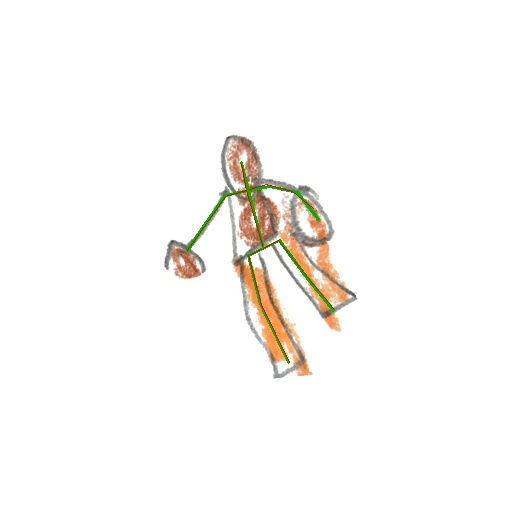

KakaoTalk_20261028_192709367_12__image_1-1_1-1_008-C11__0_t98.jpg


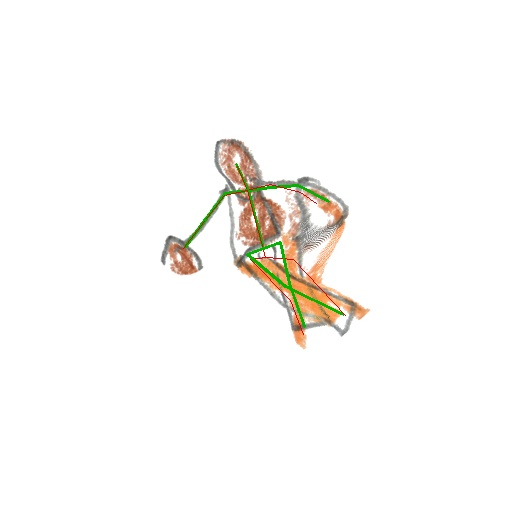

KakaoTalk_20261028_192709367_12__image_1-1_1-1_601-C04__0_t54.jpg


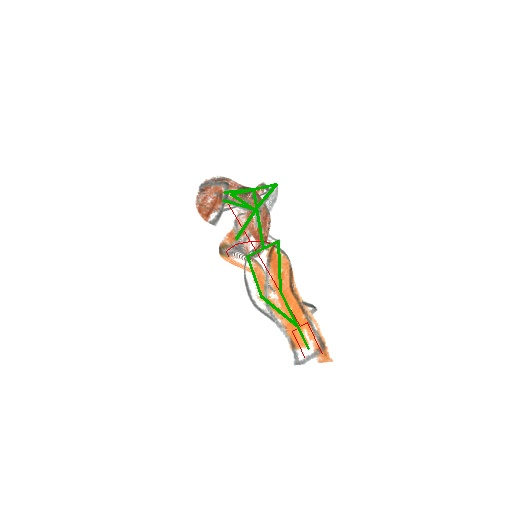

KakaoTalk_20261028_192709367_13__image_1-1_1-1_006-C05__0_t58.jpg


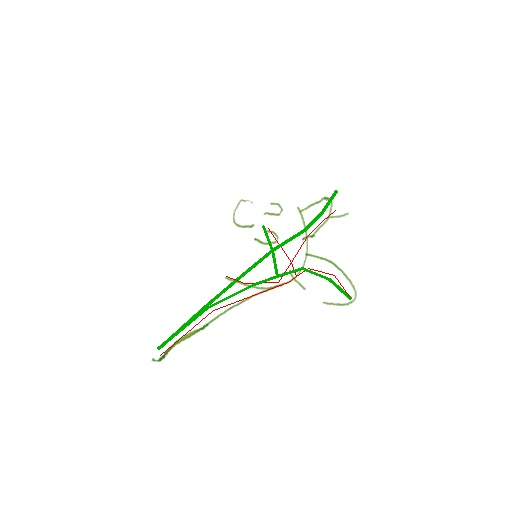

KakaoTalk_20261028_192709367_13__image_1-1_1-1_008-C11__0_t20.jpg


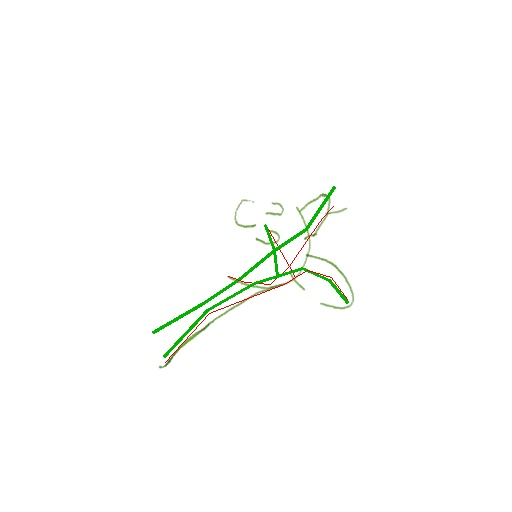

KakaoTalk_20261028_192709367_13__image_1-1_1-1_601-C04__0_t48.jpg


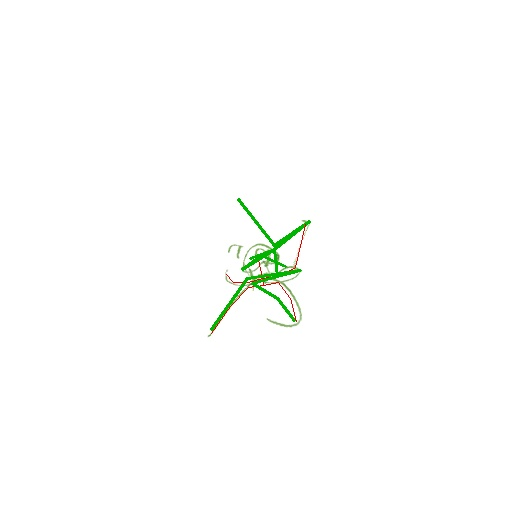

KakaoTalk_20261028_192709367_14__image_1-1_1-1_006-C05__0_t14.jpg


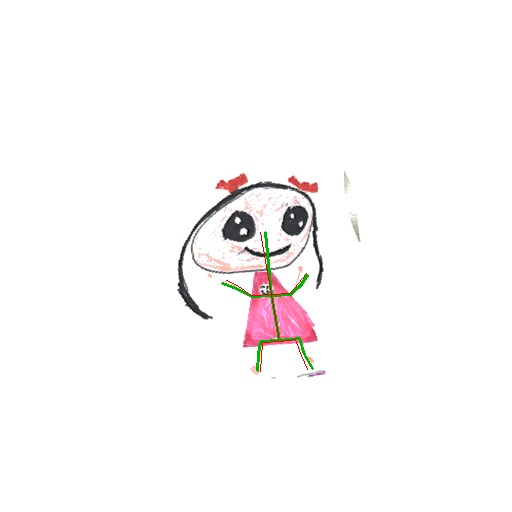

KakaoTalk_20261028_192709367_14__image_1-1_1-1_008-C11__0_t16.jpg


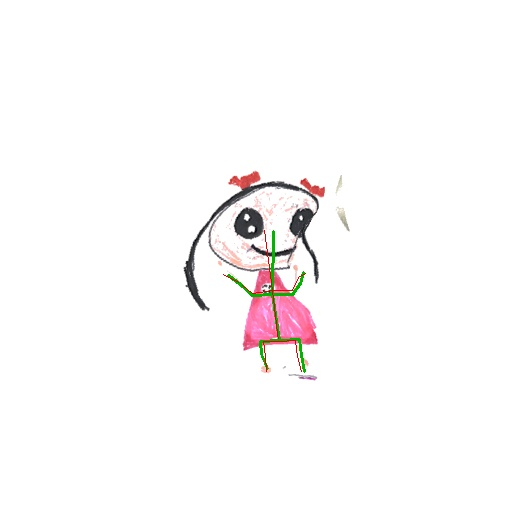

KakaoTalk_20261028_192709367_14__image_1-1_1-1_601-C04__0_t44.jpg


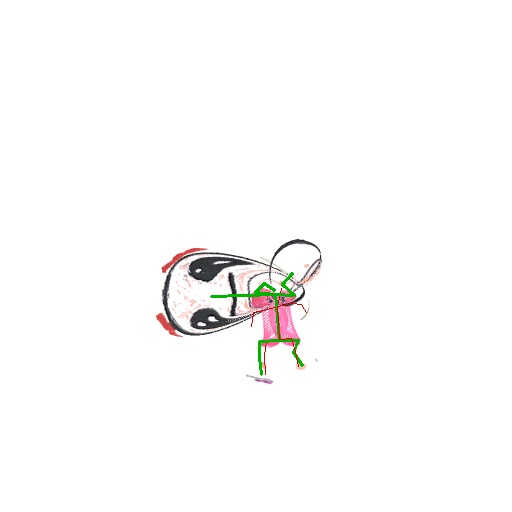

KakaoTalk_20261028_192709367_15__image_1-1_1-1_006-C05__0_t6.jpg


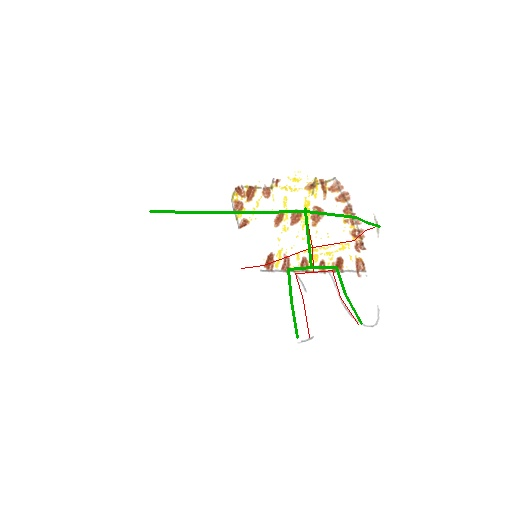

KakaoTalk_20261028_192709367_15__image_1-1_1-1_008-C11__0_t36.jpg


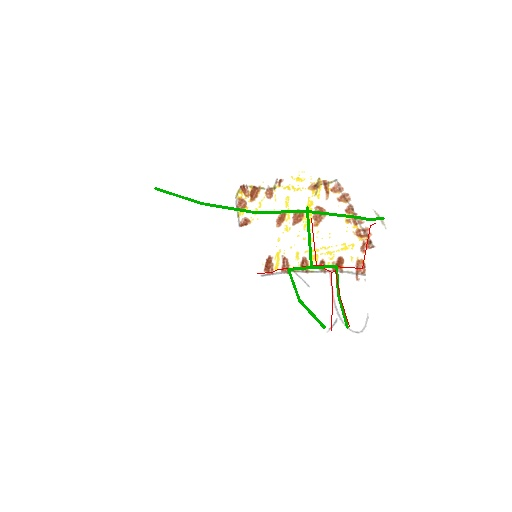

KakaoTalk_20261028_192709367_15__image_1-1_1-1_601-C04__0_t60.jpg


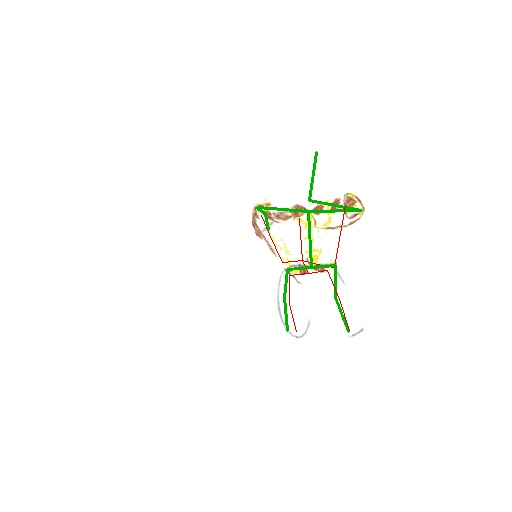

KakaoTalk_20261028_192709367_16__image_1-1_1-1_006-C05__0_t30.jpg


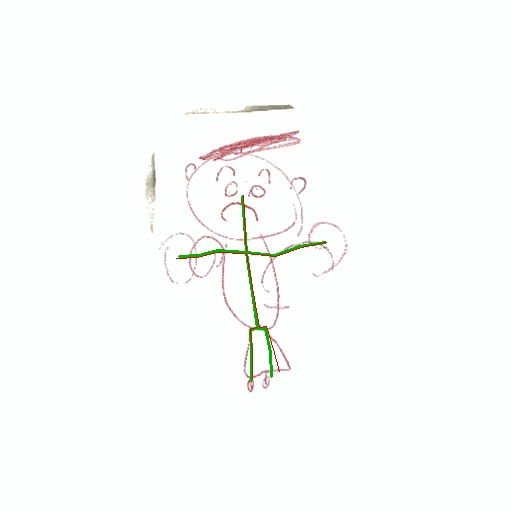

KakaoTalk_20261028_192709367_16__image_1-1_1-1_008-C11__0_t98.jpg


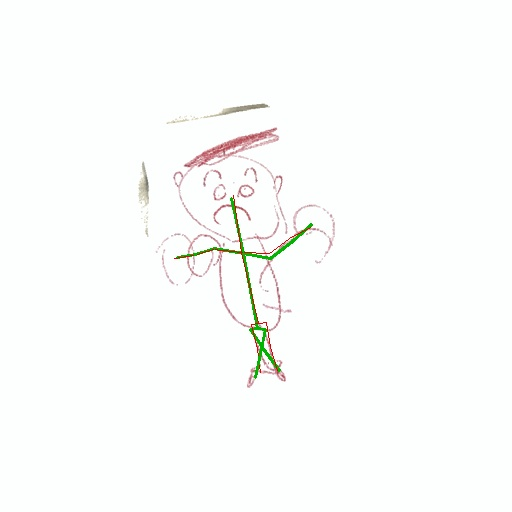

KakaoTalk_20261028_192709367_16__image_1-1_1-1_601-C04__0_t44.jpg


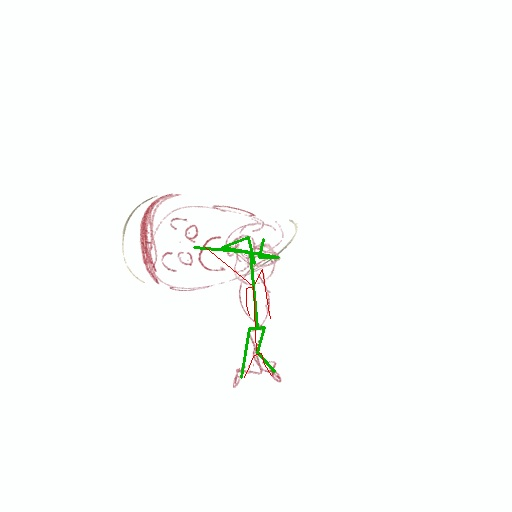

KakaoTalk_20261028_192709367_17__image_1-1_1-1_006-C05__0_t44.jpg


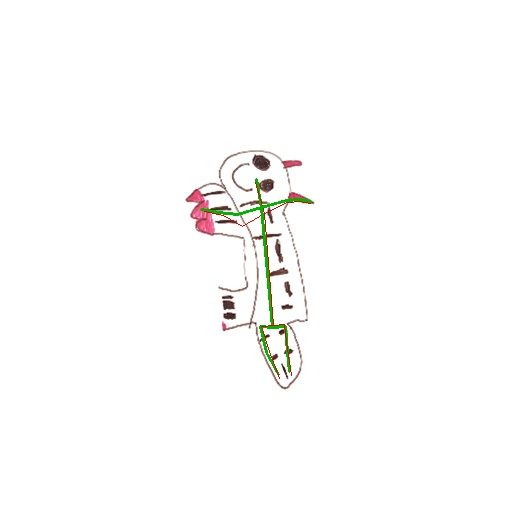

KakaoTalk_20261028_192709367_17__image_1-1_1-1_008-C11__0_t98.jpg


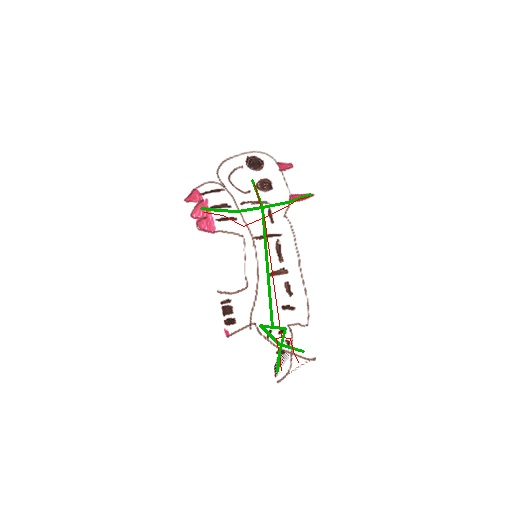

KakaoTalk_20261028_192709367_17__image_1-1_1-1_601-C04__0_t44.jpg


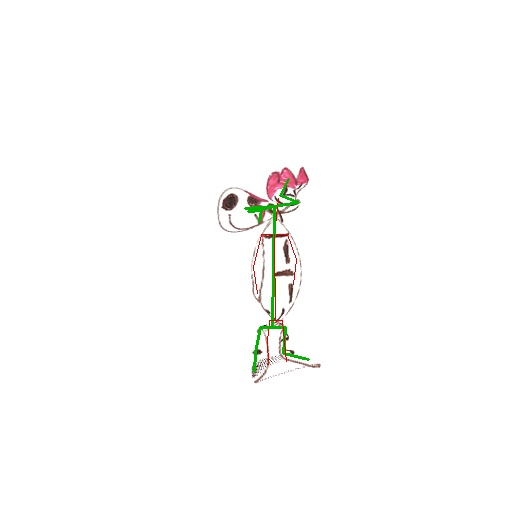

KakaoTalk_20261028_192709367_18__image_1-1_1-1_006-C05__0_t78.jpg


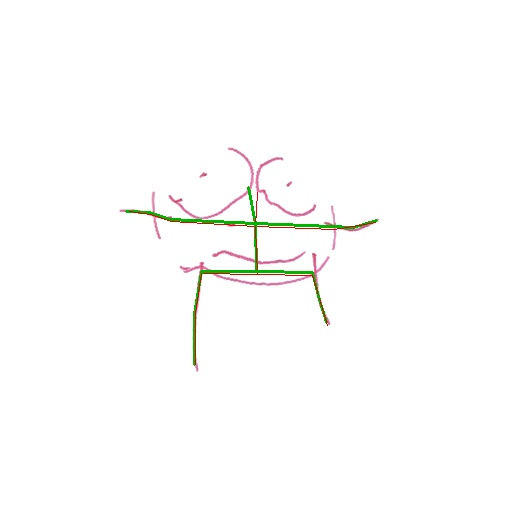

KakaoTalk_20261028_192709367_18__image_1-1_1-1_008-C11__0_t76.jpg


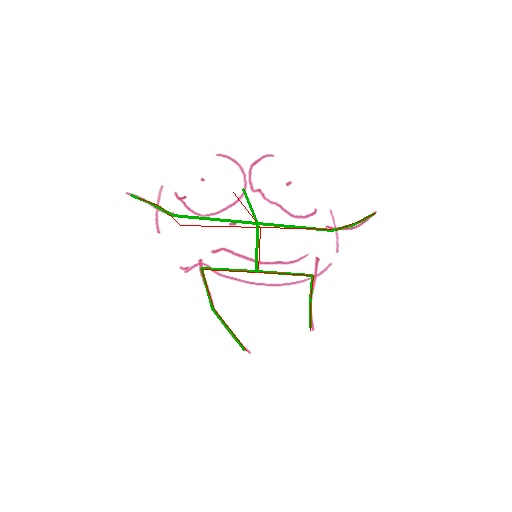

KakaoTalk_20261028_192709367_18__image_1-1_1-1_601-C04__0_t44.jpg


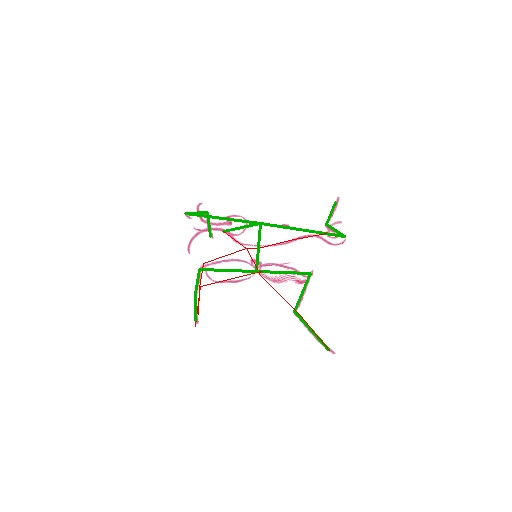

KakaoTalk_20261028_192709367_19__image_1-1_1-1_006-C05__0_t60.jpg


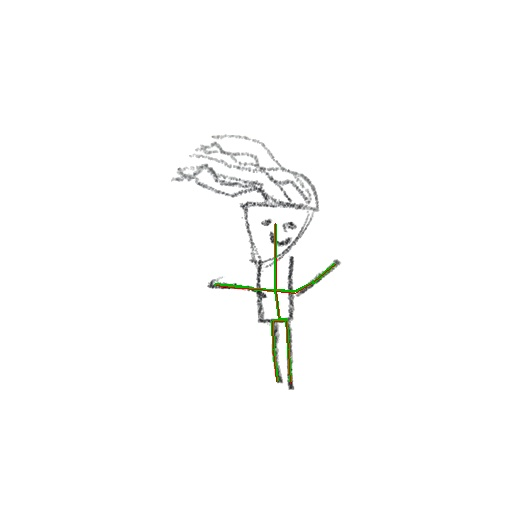

KakaoTalk_20261028_192709367_19__image_1-1_1-1_008-C11__0_t98.jpg


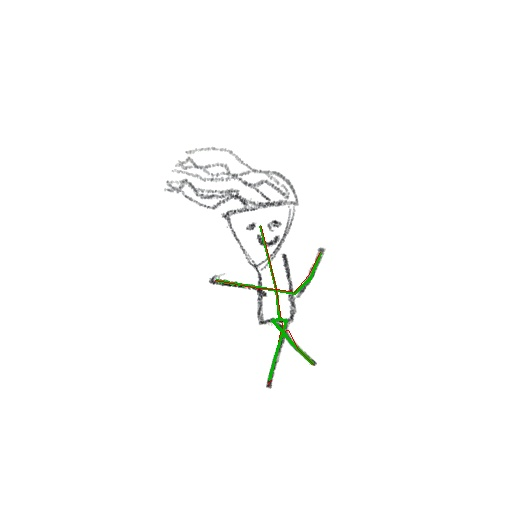

KakaoTalk_20261028_192709367_19__image_1-1_1-1_601-C04__0_t46.jpg


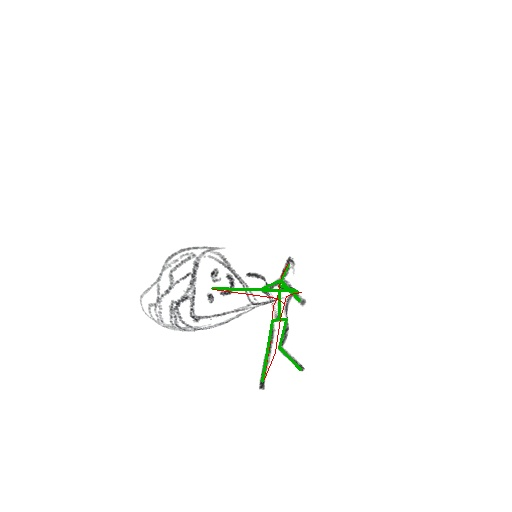

KakaoTalk_20261028_192709367_20__image_1-1_1-1_006-C05__0_t14.jpg


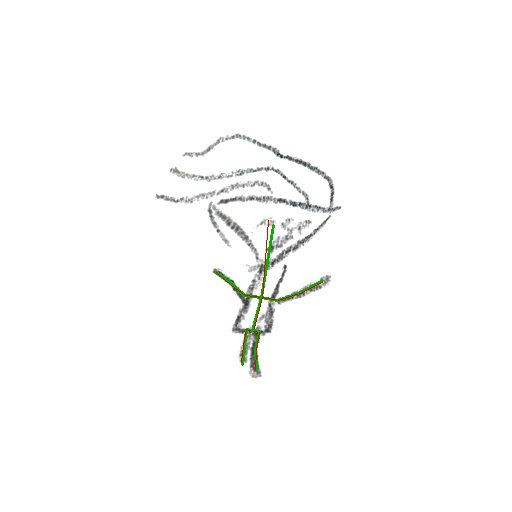

KakaoTalk_20261028_192709367_20__image_1-1_1-1_008-C11__0_t98.jpg


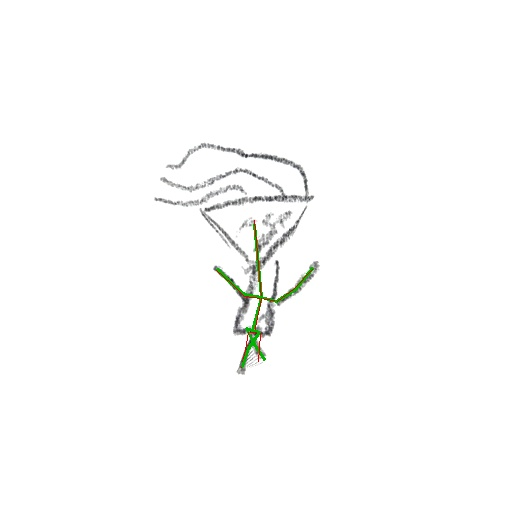

KakaoTalk_20261028_192709367_20__image_1-1_1-1_601-C04__0_t50.jpg


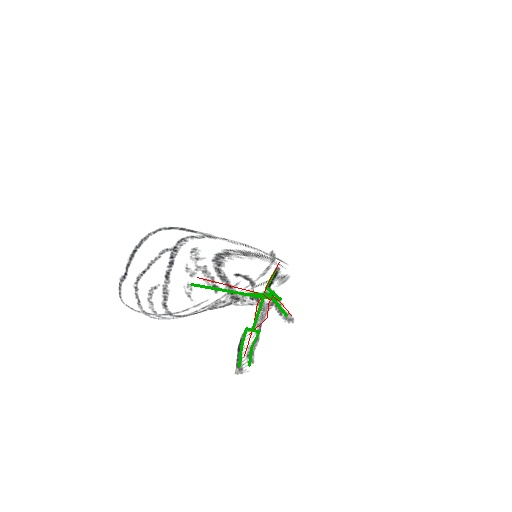

KakaoTalk_20261028_192709367_21__image_1-1_1-1_006-C05__0_t58.jpg


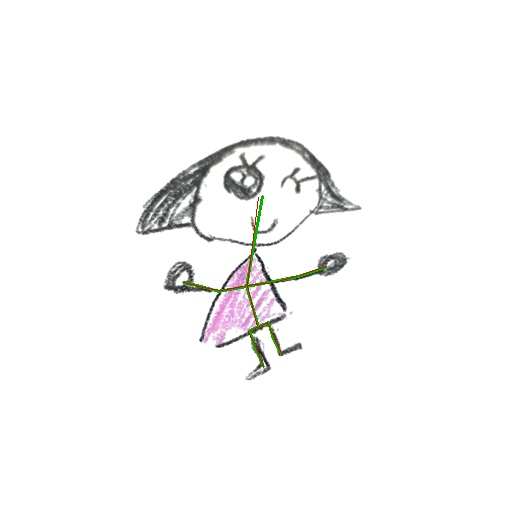

KakaoTalk_20261028_192709367_21__image_1-1_1-1_008-C11__0_t98.jpg


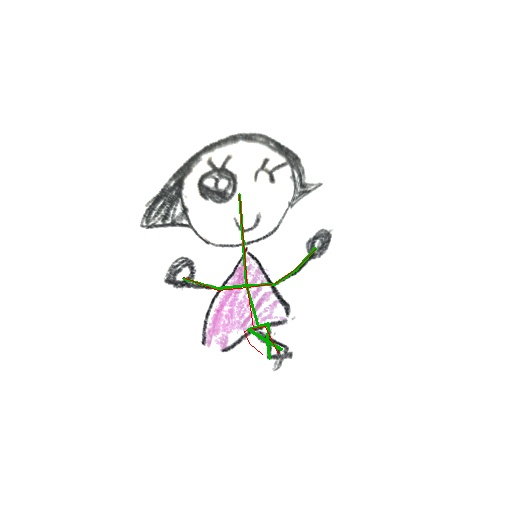

KakaoTalk_20261028_192709367_21__image_1-1_1-1_601-C04__0_t56.jpg


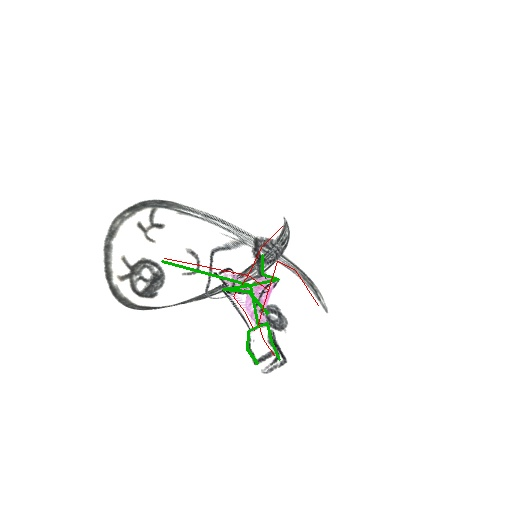

KakaoTalk_20261028_192709367_23__image_1-1_1-1_006-C05__0_t38.jpg


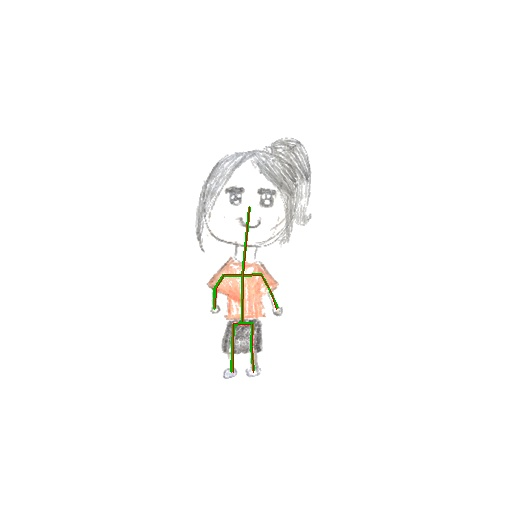

KakaoTalk_20261028_192709367_23__image_1-1_1-1_008-C11__0_t98.jpg


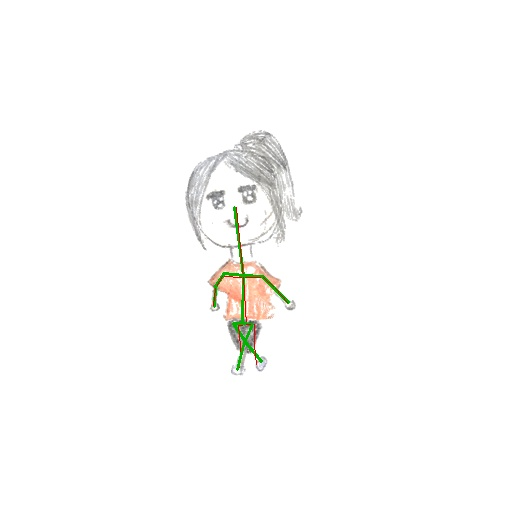

KakaoTalk_20261028_192709367_23__image_1-1_1-1_601-C04__0_t38.jpg


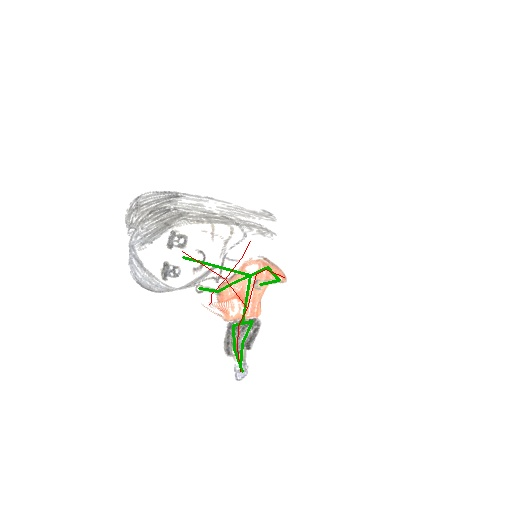

In [16]:
import json, subprocess, glob, os
import pandas as pd
from IPython.display import Image as IImage, display

EVAL_DIR = "/content/eval_motion"
STRIDE = 2           # 몇 프레임마다 측정할지 (1이면 전부, 느림)

specs = [f"{motions[i]['npy']}:{motions[i]['fps']}" for i in SELECT]
cmd = (PY + ["/content/eval_motion.py", SRC_DIR, EVAL_DIR] + specs + ["--stride", str(STRIDE)]
       + (["--mirror"] if MIRROR else []) + (["--relative"] if RELATIVE else []) + ([] if FOLLOW_ROOT else ["--no-root"]))
r = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
print(r.stdout[-4000:])
if r.returncode:
    print(r.stderr[-2000:]); raise SystemExit("평가 실패")

df = pd.read_csv(f"{EVAL_DIR}/summary.csv")
df["재검출 하락"] = (df["rest_pck10"] - df["pck10"]).round(3)          # 동작 때문에 생긴 손상
display(df)
print("\n전체 평균:")
display(df[["rest_pck10", "pck10", "arm_pck10", "worst_frame_pck10", "area_min", "area_max", "jitter"]].mean().round(3).to_frame("평균").T)
print("\n관절별 재검출 PCK@0.1:")
display(pd.DataFrame(json.load(open(f"{EVAL_DIR}/per_joint.json"))).T)

print("\n가장 많이 어긋난 프레임 (초록 = 의도한 관절, 빨강 = 모델이 다시 찾은 관절)")
for p in sorted(glob.glob(f"{EVAL_DIR}/worst/*__0_*.jpg")):
    print(os.path.basename(p)); display(IImage(p, width=360))

 | image_1-1_1-1_008-C11 | 재검출 PCK@0.1 0.80 (움직이기 전 0.73) | 팔 0.50 | 최악 프레임 0.73 | 면적 0.90~1.01 | 떨림 0.0102
KakaoTalk_20261028_192709367_13 | image_1-1_1-1_601-C04 | 재검출 PCK@0.1 0.50 (움직이기 전 0.73) | 팔 0.22 | 최악 프레임 0.20 | 면적 0.70~1.00 | 떨림 0.0300
KakaoTalk_20261028_192709367_14 | image_1-1_1-1_006-C05 | 재검출 PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 프레임 1.00 | 면적 0.96~1.00 | 떨림 0.0023
KakaoTalk_20261028_192709367_14 | image_1-1_1-1_008-C11 | 재검출 PCK@0.1 1.00 (움직이기 전 1.00) | 팔 1.00 | 최악 프레임 1.00 | 면적 0.92~1.01 | 떨림 0.0051
KakaoTalk_20261028_192709367_14 | image_1-1_1-1_601-C04 | 재검출 PCK@0.1 0.62 (움직이기 전 1.00) | 팔 0.45 | 최악 프레임 0.13 | 면적 0.69~1.01 | 떨림 0.0183
KakaoTalk_20261028_192709367_15 | image_1-1_1-1_006-C05 | 재검출 PCK@0.1 0.73 (움직이기 전 0.73) | 팔 0.50 | 최악 프레임 0.67 | 면적 0.99~1.01 | 떨림 0.0039
KakaoTalk_20261028_192709367_15 | image_1-1_1-1_008-C11 | 재검출 PCK@0.1 0.66 (움직이기 전 0.73) | 팔 0.50 | 최악 프레임 0.47 | 면적 0.99~1.01 | 떨림 0.0098
KakaoTalk_20261028_192709367_15 | image_1-1_1-1_601-C04 | 

,image,motion,frames,rest_pck05,rest_pck10,pck05,pck10,arm_pck10,worst_frame_pck10,area_min,area_max,jitter,재검출 하락
0,KakaoTalk_20261028_192709367_12,image_1-1_1-1_006-C05,43,1.000,1.000,1.000,1.000,1.000,1.000,0.997,1.038,0.0026,0.000
1,KakaoTalk_20261028_192709367_12,image_1-1_1-1_008-C11,51,1.000,1.000,0.937,0.986,1.000,0.800,0.949,1.061,0.0083,0.014
2,KakaoTalk_20261028_192709367_12,image_1-1_1-1_601-C04,36,1.000,1.000,0.522,0.644,0.576,0.133,0.614,1.000,0.0164,0.356
3,KakaoTalk_20261028_192709367_13,image_1-1_1-1_006-C05,43,0.533,0.733,0.533,0.733,0.500,0.733,0.968,1.016,0.0035,0.000
4,KakaoTalk_20261028_192709367_13,image_1-1_1-1_008-C11,51,0.533,0.733,0.552,0.796,0.500,0.733,0.901,1.010,0.0102,-0.063
5,KakaoTalk_20261028_192709367_13,image_1-1_1-1_601-C04,36,0.533,0.733,0.315,0.496,0.222,0.200,0.698,1.000,0.0300,0.237
6,KakaoTalk_20261028_192709367_14,image_1-1_1-1_006-C05,43,1.000,1.000,1.000,1.000,1.000,1.000,0.957,1.000,0.0023,0.000
7,KakaoTalk_20261028_192709367_14,image_1-1_1-1_008-C11,51,1.000,1.000,1.000,1.000,1.000,1.000,0.915,1.006,0.0051,0.000
8,KakaoTalk_20261028_192709367_14,image_1-1_1-1_601-C04,36,1.000,1.000,0.520,0.620,0.451,0.133,0.694,1.012,0.0183,0.380
9,KakaoTalk_20261028_192709367_15,image_1-1_1-1_006-C05,43,0.533,0.733,0.558,0.732,0.500,0.667,0.990,1.012,0.0039,0.001



전체 평균:


,rest_pck10,pck10,arm_pck10,worst_frame_pck10,area_min,area_max,jitter
평균,0.951,0.844,0.757,0.689,0.88,1.023,0.01



관절별 재검출 PCK@0.1:


,pck10,mean_err
nose,0.977,0.0238
neck,0.856,0.0411
r_sho,0.735,0.0731
r_elb,0.704,0.0871
r_wri,0.673,0.1351
l_sho,0.871,0.0427
l_elb,0.892,0.0438
l_wri,0.863,0.0537
pelvis,0.970,0.0216
r_hip,0.861,0.0387



가장 많이 어긋난 프레임 (초록 = 의도한 관절, 빨강 = 모델이 다시 찾은 관절)
KakaoTalk_20261028_192709367_12__image_1-1_1-1_006-C05__0_t36.jpg


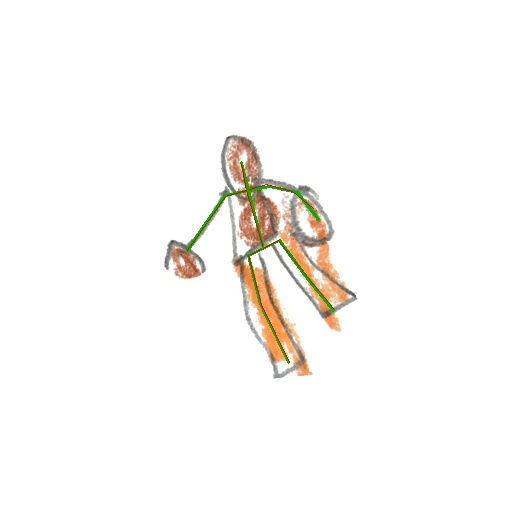

KakaoTalk_20261028_192709367_12__image_1-1_1-1_008-C11__0_t98.jpg


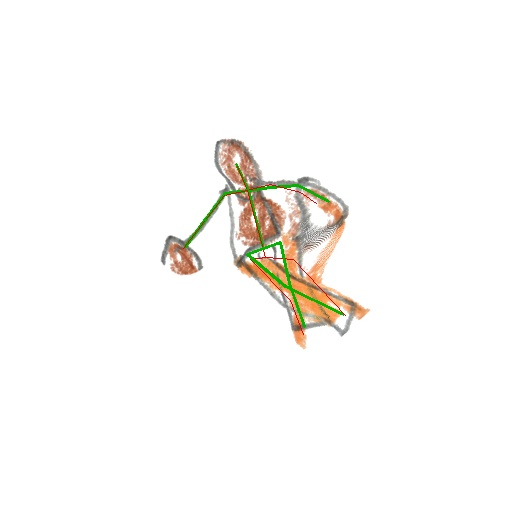

KakaoTalk_20261028_192709367_12__image_1-1_1-1_601-C04__0_t54.jpg


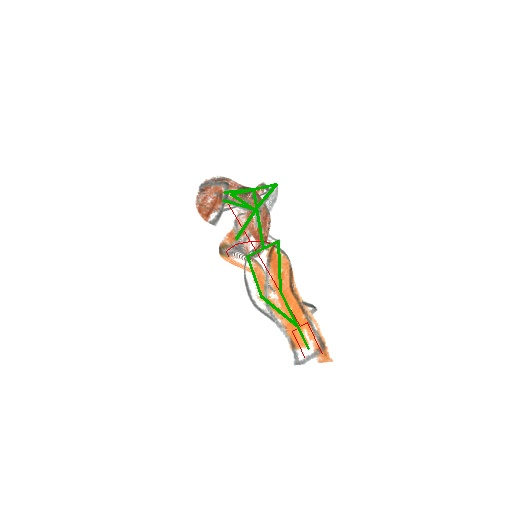

KakaoTalk_20261028_192709367_13__image_1-1_1-1_006-C05__0_t58.jpg


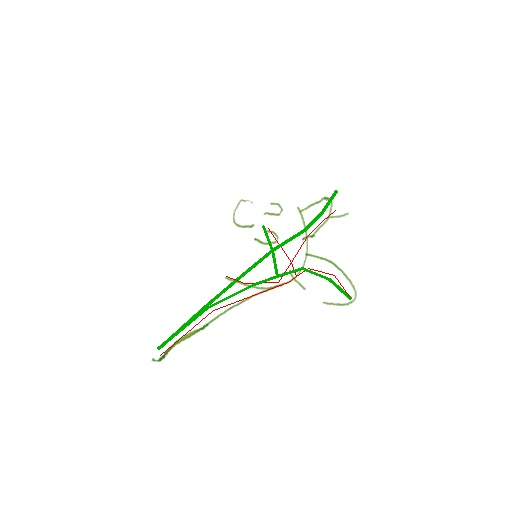

KakaoTalk_20261028_192709367_13__image_1-1_1-1_008-C11__0_t20.jpg


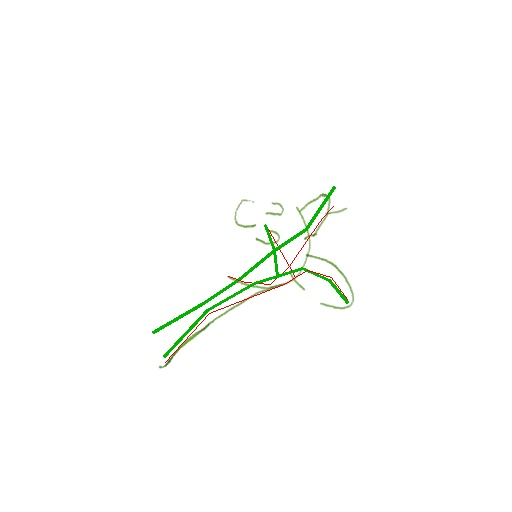

KakaoTalk_20261028_192709367_13__image_1-1_1-1_601-C04__0_t48.jpg


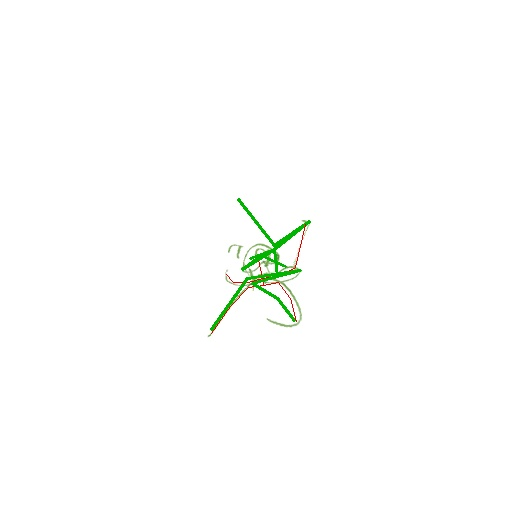

KakaoTalk_20261028_192709367_14__image_1-1_1-1_006-C05__0_t14.jpg


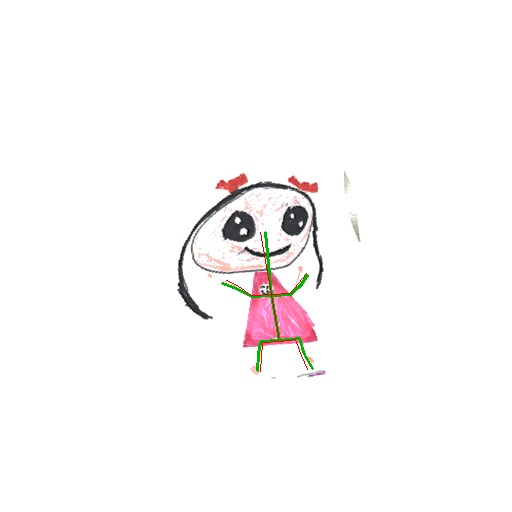

KakaoTalk_20261028_192709367_14__image_1-1_1-1_008-C11__0_t16.jpg


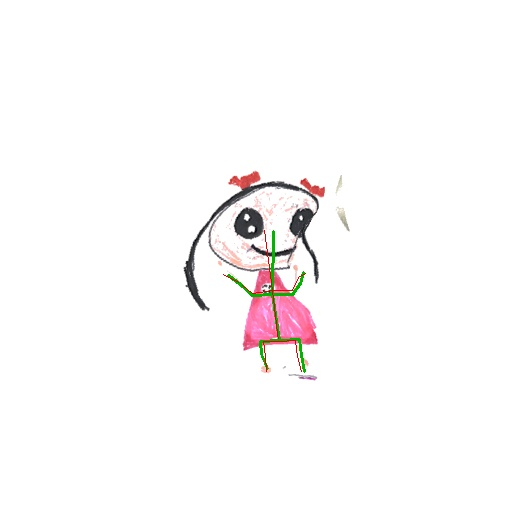

KakaoTalk_20261028_192709367_14__image_1-1_1-1_601-C04__0_t44.jpg


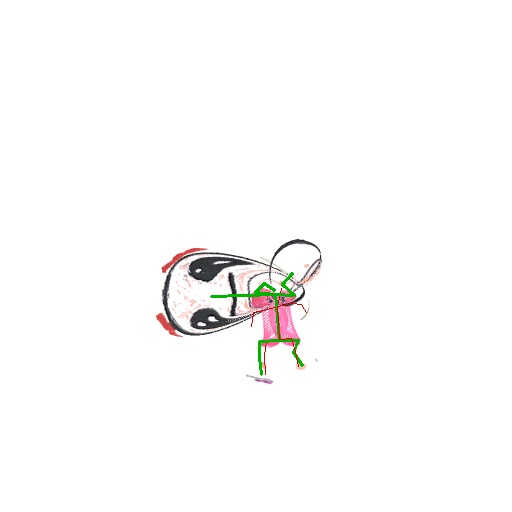

KakaoTalk_20261028_192709367_15__image_1-1_1-1_006-C05__0_t6.jpg


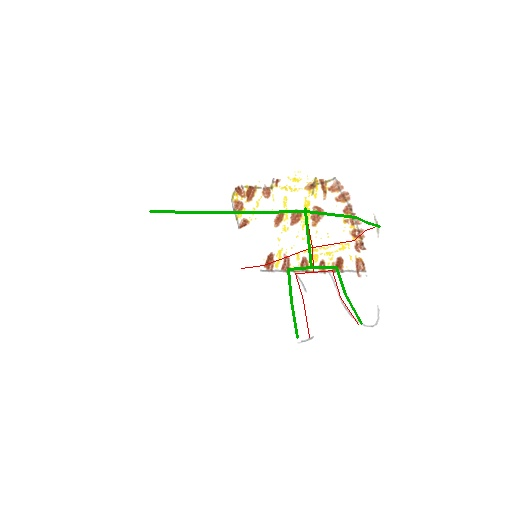

KakaoTalk_20261028_192709367_15__image_1-1_1-1_008-C11__0_t36.jpg


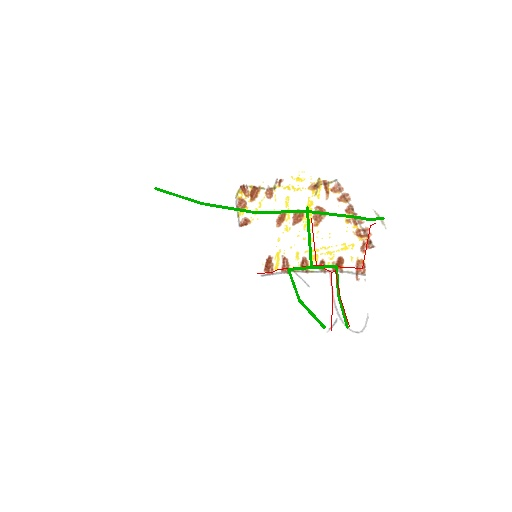

KakaoTalk_20261028_192709367_15__image_1-1_1-1_601-C04__0_t60.jpg


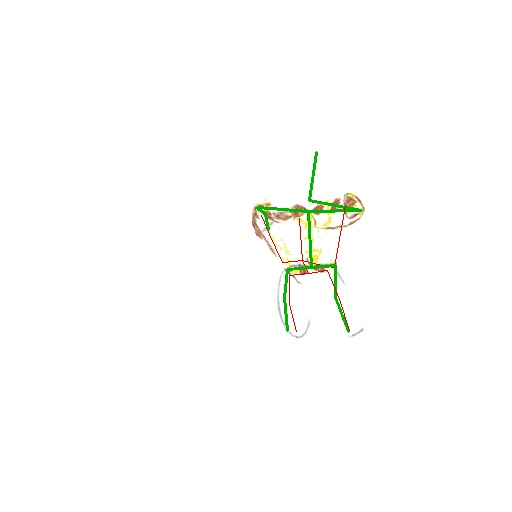

KakaoTalk_20261028_192709367_16__image_1-1_1-1_006-C05__0_t30.jpg


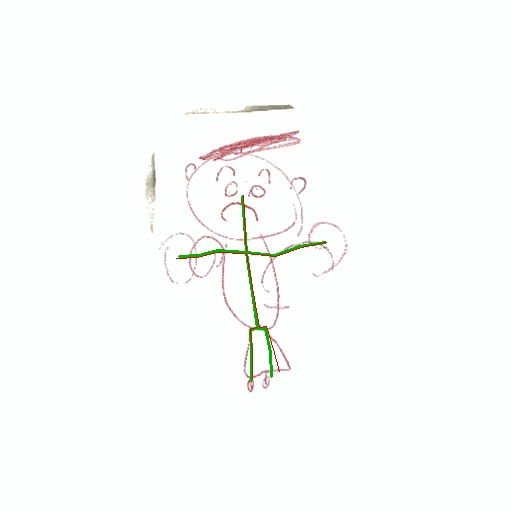

KakaoTalk_20261028_192709367_16__image_1-1_1-1_008-C11__0_t98.jpg


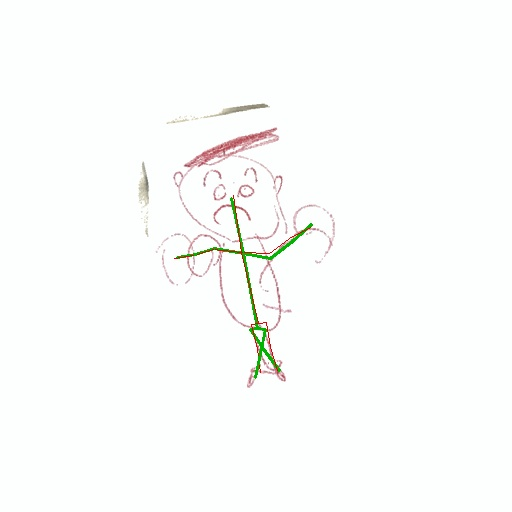

KakaoTalk_20261028_192709367_16__image_1-1_1-1_601-C04__0_t44.jpg


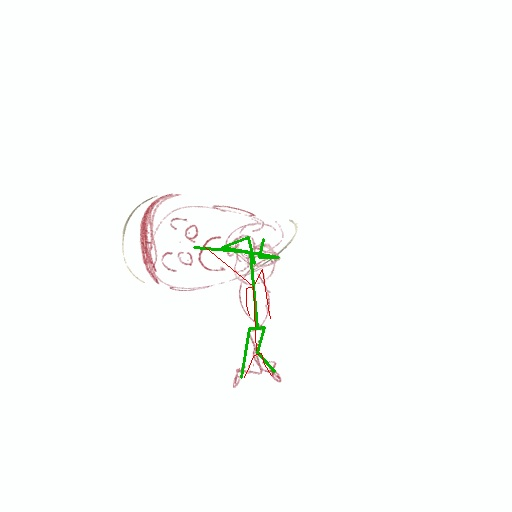

KakaoTalk_20261028_192709367_17__image_1-1_1-1_006-C05__0_t44.jpg


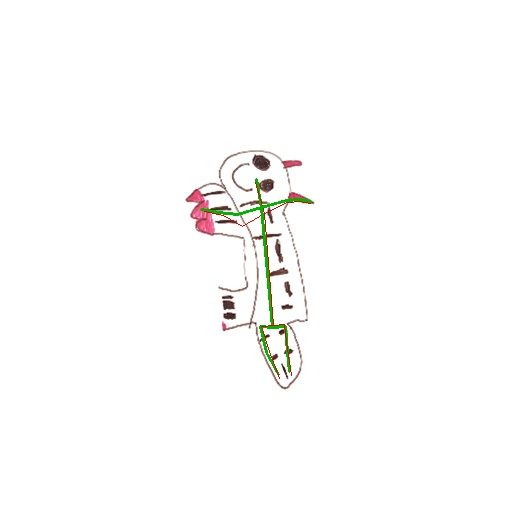

KakaoTalk_20261028_192709367_17__image_1-1_1-1_008-C11__0_t98.jpg


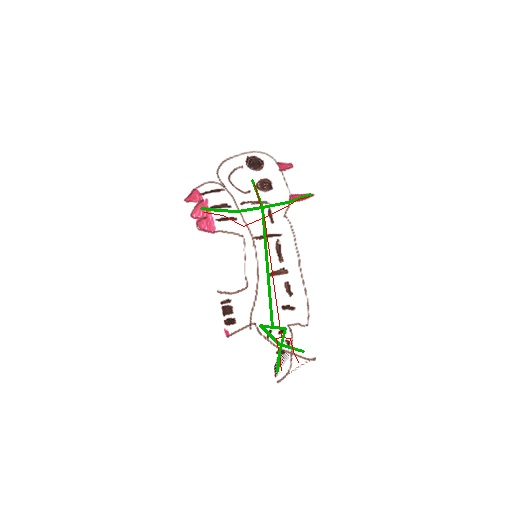

KakaoTalk_20261028_192709367_17__image_1-1_1-1_601-C04__0_t44.jpg


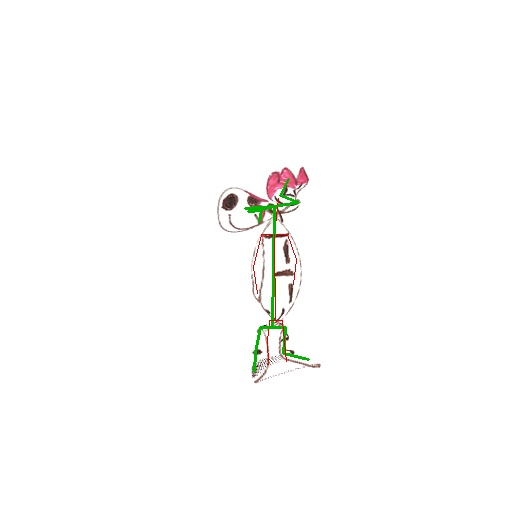

KakaoTalk_20261028_192709367_18__image_1-1_1-1_006-C05__0_t78.jpg


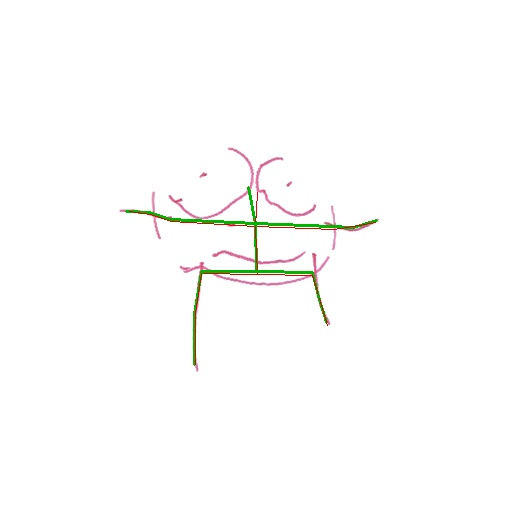

KakaoTalk_20261028_192709367_18__image_1-1_1-1_008-C11__0_t76.jpg


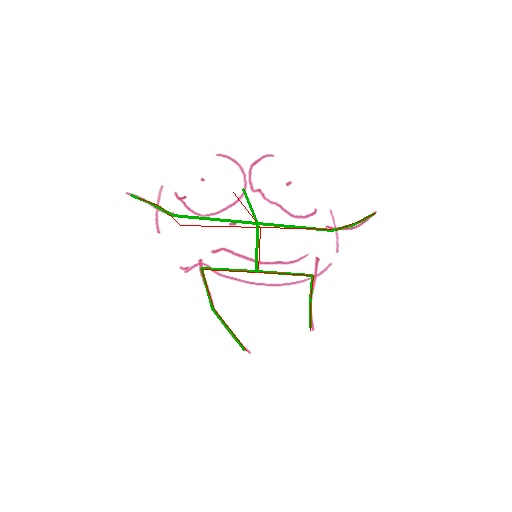

KakaoTalk_20261028_192709367_18__image_1-1_1-1_601-C04__0_t44.jpg


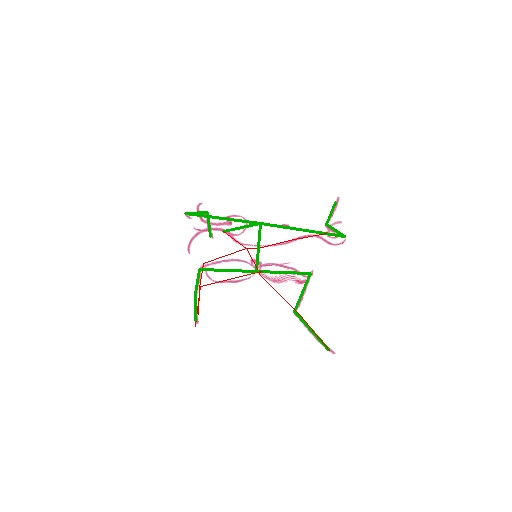

KakaoTalk_20261028_192709367_19__image_1-1_1-1_006-C05__0_t60.jpg


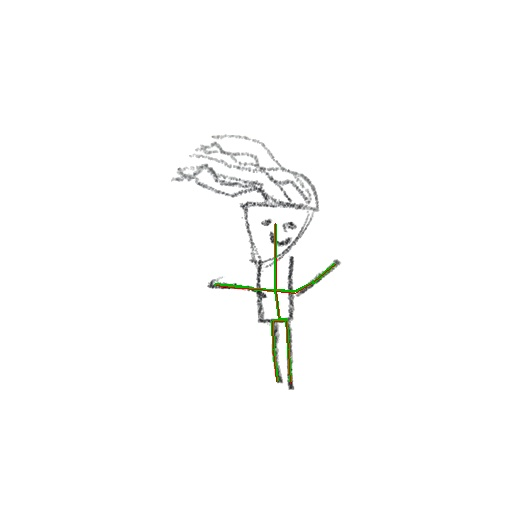

KakaoTalk_20261028_192709367_19__image_1-1_1-1_008-C11__0_t98.jpg


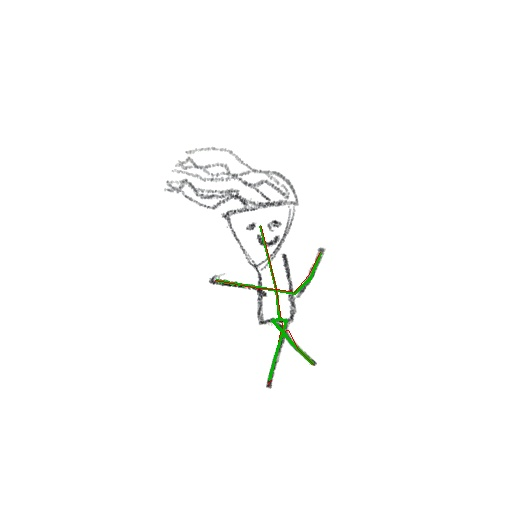

KakaoTalk_20261028_192709367_19__image_1-1_1-1_601-C04__0_t46.jpg


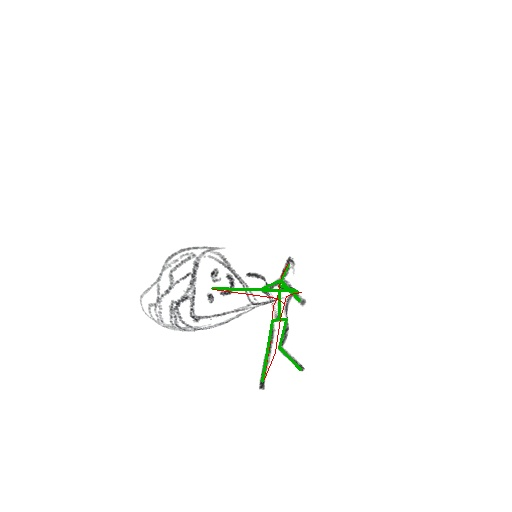

KakaoTalk_20261028_192709367_20__image_1-1_1-1_006-C05__0_t14.jpg


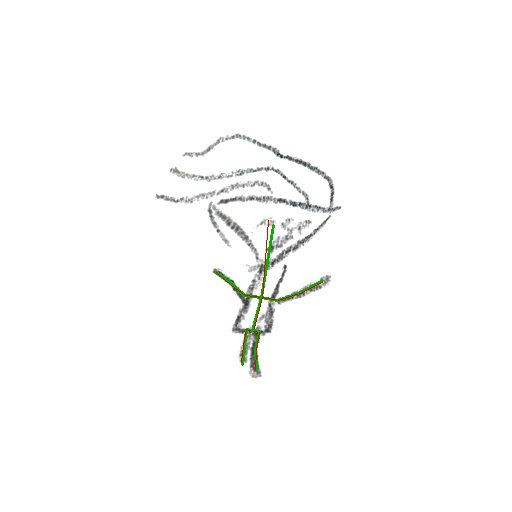

KakaoTalk_20261028_192709367_20__image_1-1_1-1_008-C11__0_t98.jpg


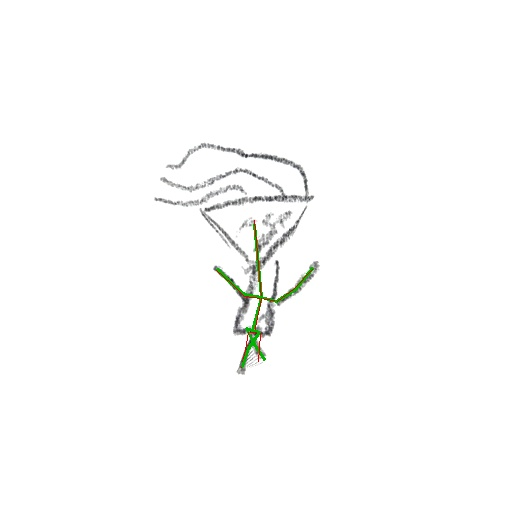

KakaoTalk_20261028_192709367_20__image_1-1_1-1_601-C04__0_t50.jpg


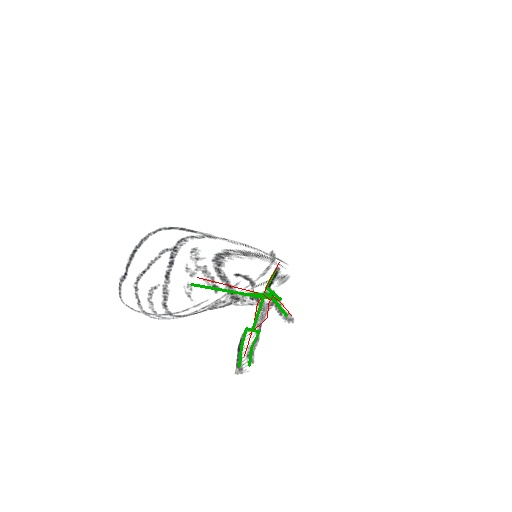

KakaoTalk_20261028_192709367_21__image_1-1_1-1_006-C05__0_t58.jpg


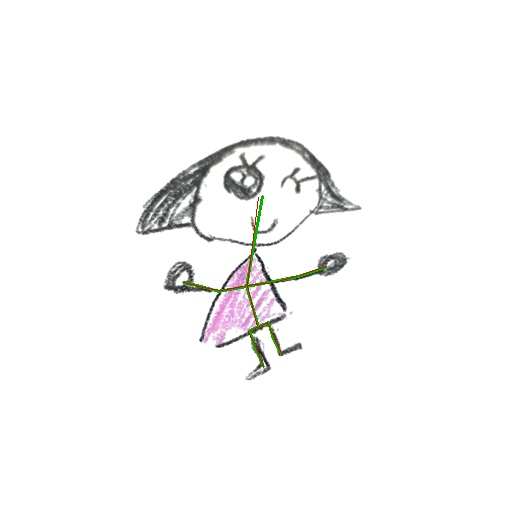

KakaoTalk_20261028_192709367_21__image_1-1_1-1_008-C11__0_t98.jpg


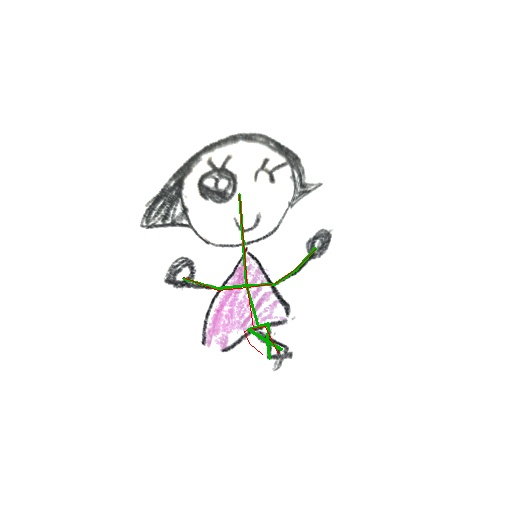

KakaoTalk_20261028_192709367_21__image_1-1_1-1_601-C04__0_t56.jpg


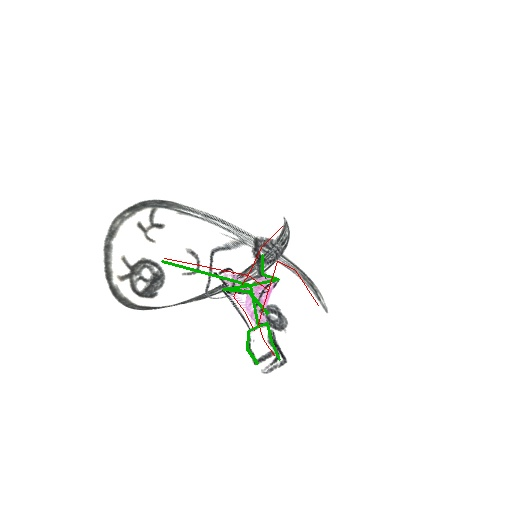

KakaoTalk_20261028_192709367_23__image_1-1_1-1_006-C05__0_t38.jpg


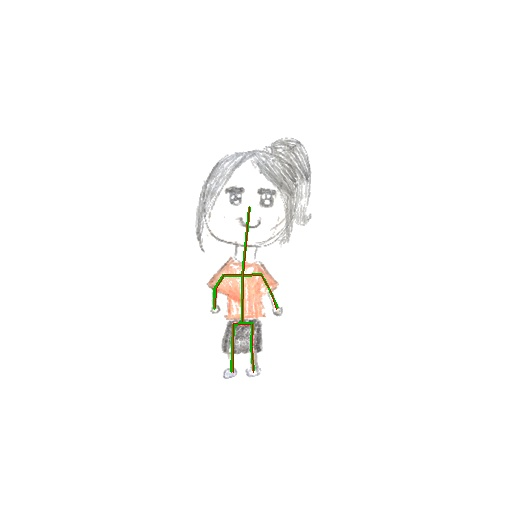

KakaoTalk_20261028_192709367_23__image_1-1_1-1_008-C11__0_t98.jpg


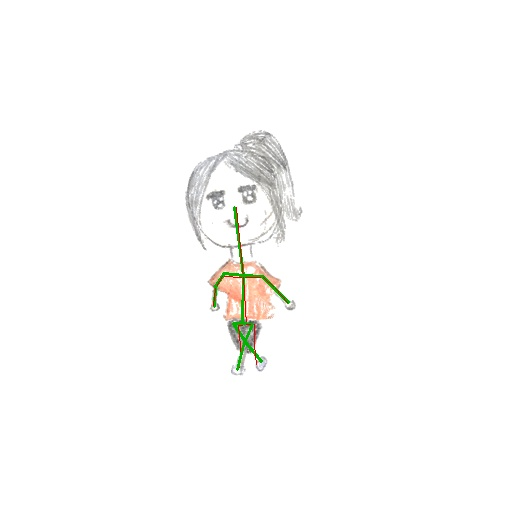

KakaoTalk_20261028_192709367_23__image_1-1_1-1_601-C04__0_t38.jpg


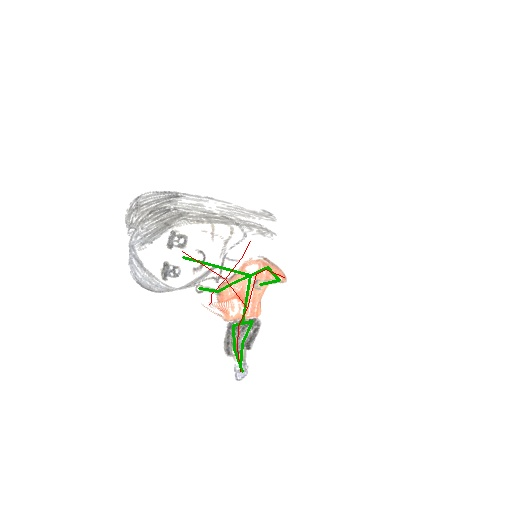

In [17]:
import json, subprocess, glob, os
import pandas as pd
from IPython.display import Image as IImage, display

EVAL_DIR = "/content/eval_motion"
STRIDE = 2           # 몇 프레임마다 측정할지 (1이면 전부, 느림)

specs = [f"{motions[i]['npy']}:{motions[i]['fps']}" for i in SELECT]
cmd = (PY + ["/content/eval_motion.py", SRC_DIR, EVAL_DIR] + specs + ["--stride", str(STRIDE)]
       + (["--mirror"] if MIRROR else []) + (["--relative"] if RELATIVE else []) + ([] if FOLLOW_ROOT else ["--no-root"]))
r = subprocess.run(cmd, capture_output=True, text=True, env=ENV)
print(r.stdout[-4000:])
if r.returncode:
    print(r.stderr[-2000:]); raise SystemExit("평가 실패")

df = pd.read_csv(f"{EVAL_DIR}/summary.csv")
df["재검출 하락"] = (df["rest_pck10"] - df["pck10"]).round(3)          # 동작 때문에 생긴 손상
display(df)
print("\n전체 평균:")
display(df[["rest_pck10", "pck10", "arm_pck10", "worst_frame_pck10", "area_min", "area_max", "jitter"]].mean().round(3).to_frame("평균").T)
print("\n관절별 재검출 PCK@0.1:")
display(pd.DataFrame(json.load(open(f"{EVAL_DIR}/per_joint.json"))).T)

print("\n가장 많이 어긋난 프레임 (초록 = 의도한 관절, 빨강 = 모델이 다시 찾은 관절)")
for p in sorted(glob.glob(f"{EVAL_DIR}/worst/*__0_*.jpg")):
    print(os.path.basename(p)); display(IImage(p, width=360))

KakaoTalk_20261028_192709367_12__image_1-1_1-1_601-C04__0_t54.jpg


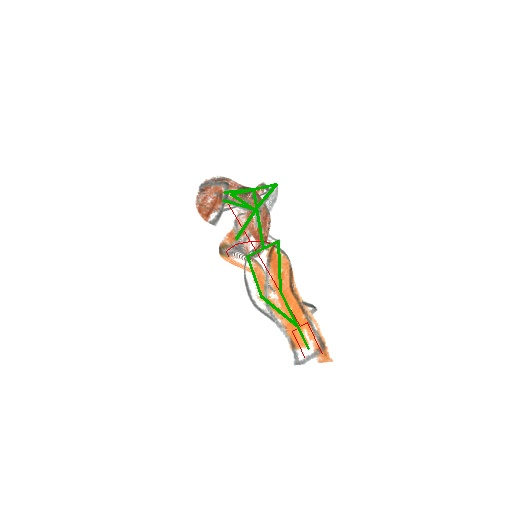

KakaoTalk_20261028_192709367_13__image_1-1_1-1_601-C04__0_t48.jpg


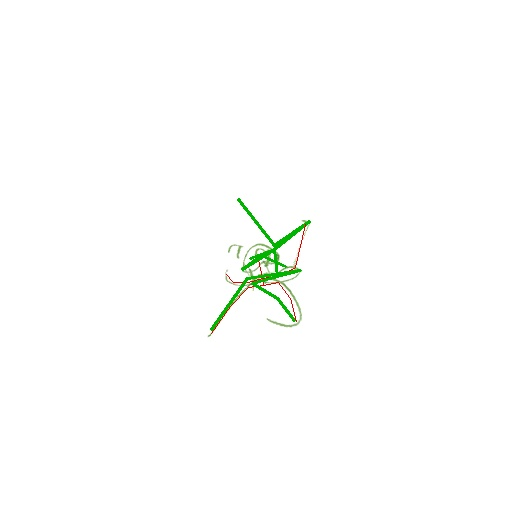

KakaoTalk_20261028_192709367_14__image_1-1_1-1_601-C04__0_t44.jpg


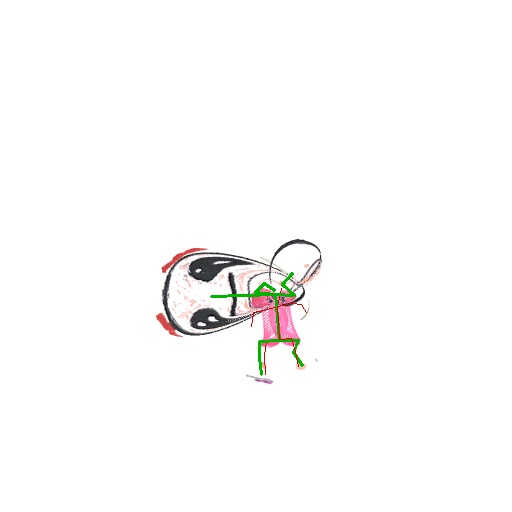

KakaoTalk_20261028_192709367_15__image_1-1_1-1_601-C04__0_t60.jpg


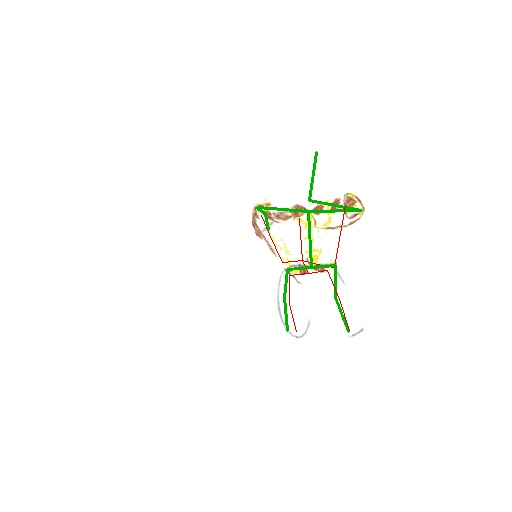

{'seq': 'image_1-1/1-1_601-C04', 'action': '1-1', 'take': '601', 'cam': 'C04', 'torso_ratio': 1.0, 'missing_ratio': 0.0, 'frontal': 0.616, 'facing': 'front', 'planar_ratio': 0.6, 'usable': True, 'best_camera': True}
KakaoTalk_20261028_192709367_13


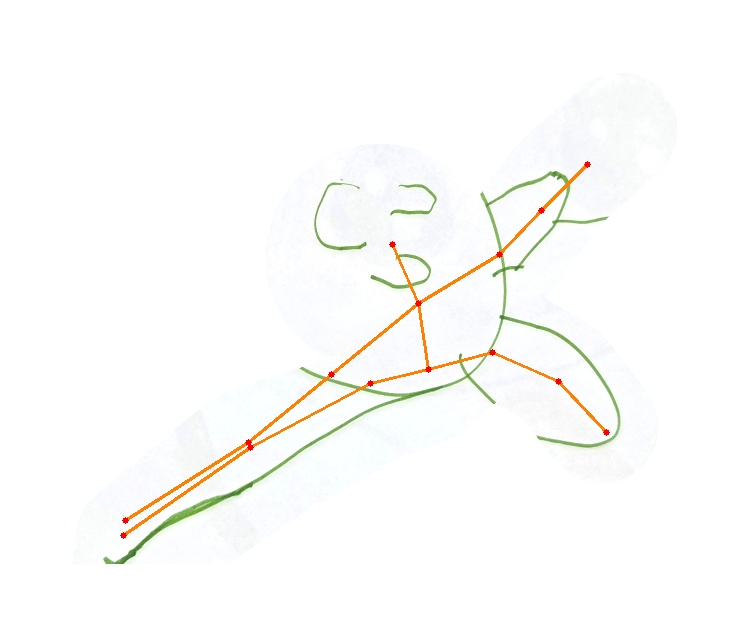

KakaoTalk_20261028_192709367_15


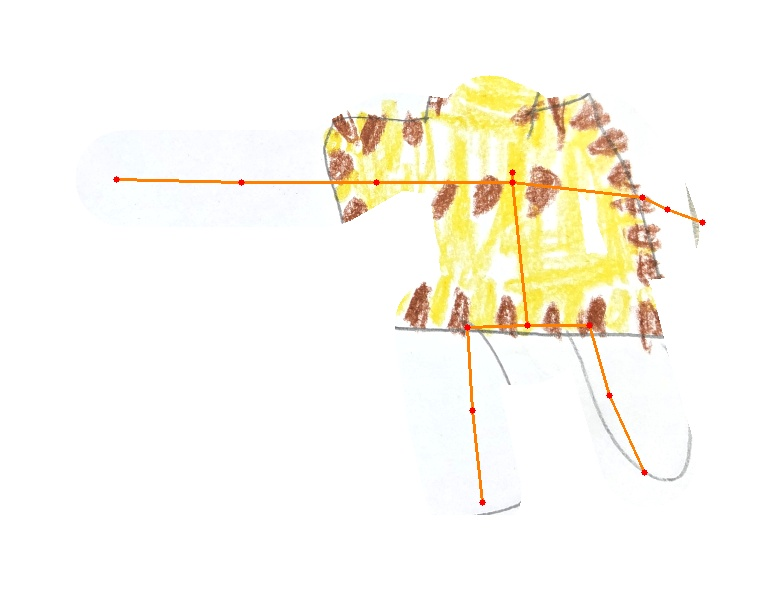

In [19]:
from IPython.display import Image as IImage, Video, display
import glob, os
for p in sorted(glob.glob(f"{EVAL_DIR}/worst/*601-C04__0_*.jpg"))[:4]:      # 601 동작 최악 프레임
    print(os.path.basename(p)); display(IImage(p, width=360))
m601 = [m for m in motions if "601-C04" in m["stem"]][0]
src = MOTION_ROOT / "previews" / f"{m601['stem']}_frames.mp4"                 # 601 원본 사람 영상
if src.exists(): display(Video(str(src), embed=True, width=360))
print([s for s in summary if "601-C04" in s["seq"]][0])                      # 추출 품질 (누락, 평면, 정면도)
for n in ("KakaoTalk_20261028_192709367_13", "KakaoTalk_20261028_192709367_15"):   # 처음부터 약한 그림
    p = glob.glob(f"/content/anim_motion/*/{n}_pose.jpg")
    if p: print(n); display(IImage(p[0], width=320))